## Migration note (read before re-running)

This notebook currently loads all targets/predictors from hardcoded local paths (`E:\Land_Use\Guinea\...`) instead of the shared `landuse_tool` pipeline (`api_connector.py` / `data_loader.py` / `config.py`) that the Deforestation module (`run_analysis.ipynb`) already uses. That's the root cause of several issues fixed/flagged in this update:

- The undocumented 14-class MODIS-derived legend, the missing Kazakhstan-origin scenario functions (removed above), the local hand-downloaded OSM/WDPA vector files were all symptoms of this notebook running outside the shared pipeline.
- The Land Use and Deforestation modules do **not** need identical predictor sets or thresholds -- they answer different questions. What changed is that the Land Use module's choices are now explicit and individually justified (see `config.py`: `LAND_USE_PREDICTOR_RASTERS`, `LAND_USE_PREDICTOR_VECTORS`, `MIN_CHANGE_PIXELS_LAND_USE`), rather than an unexamined smaller/different set assembled ad hoc.

**Recommended replacement for the data-loading cells (cells 4-9):**

```python
from landuse_tool import api_connector, data_loader, config

api_connector.initialize_all()
boundary = api_connector.get_admin_boundary()  # Guinea ADM0, via config.ADMIN_BOUNDARY_CONFIG

# Target: ESRI_LULC (10 m, 2017-2025, documented 9-class legend) instead of
# the ad-hoc local MODIS exports -- see config.LAND_USE_TARGET_DATASET.
target_cfg = config.TARGET_RASTERS_CONFIG[config.LAND_USE_TARGET_DATASET]
target_files = data_loader.fetch_and_load_api_targets(boundary)

# Predictors: the Land-Use-specific subset (config.LAND_USE_PREDICTOR_RASTERS
# + config.LAND_USE_PREDICTOR_VECTORS), each individually justified in
# config.py -- not the Deforestation module's set, and not required to match
# it. Includes the two new additions wired into config.py this update:
# SOIL_MOISTURE and PROTECTED_AREAS (WDPA). Deliberately excludes TEMPERATURE
# (LST, circularity risk) and RAILWAYS (not a general accessibility layer for
# Guinea's dominant transitions) -- see config.py comments for the reasoning.
predictor_files = data_loader.fetch_and_load_api_predictors(
    boundary,
    raster_keys=config.LAND_USE_PREDICTOR_RASTERS,
    vector_keys=config.LAND_USE_PREDICTOR_VECTORS,
)

# Hold-out reference year: pull the latest year from the SAME ESRI series
# used for training, rather than a separately-sourced validation raster --
# mirrors the same-source-consistency principle used for the Hansen/ESRI
# cross-check in the Deforestation module.

# Transition significance threshold: config.MIN_CHANGE_PIXELS_LAND_USE (see
# config.py for the statistical -- not cross-module -- justification).
MIN_PIXELS = config.MIN_CHANGE_PIXELS_LAND_USE
```

**Also available now, not yet wired into this notebook's flow:**
- `change_analysis.analyze_non_linear_trends()` -- refined in this update, same name/signature as before -- now fits genuine linear/exponential/logistic candidates per transition and selects the best by AICc (via the new `fit_transition_curve()` helper), instead of always fitting a straight line despite the function's name. Falls back to simpler models automatically when there isn't enough data (e.g. logistic needs >= 5 points).
- `change_analysis.run_intensity_analysis()` runs the Aldwaik & Pontius (2012) interval/category/transition Intensity Analysis referenced in the methodology but never implemented.
- `prediction.run_monte_carlo_allocation()` -- new in this update -- runs the existing single-draw stochastic allocation N times and aggregates into a per-pixel change-frequency map, so the methodology's existing Monte Carlo claim is actually backed by an ensemble rather than one realization.
- `training.train_transition_models(..., use_growth_modes=True)` already supports training Expander alongside Patcher; this notebook currently only calls the Patcher path.

**This notebook cannot be re-run end-to-end here** -- it requires live Earth Engine / OSM / WorldPop access that this environment does not have. Run the updated cells in the environment with GEE credentials (local Windows machine or the Azure Container App).

## Addendum: merged with Deforestation module's data_loader/api_connector updates

`data_loader.py` and `api_connector.py` were updated again with three new functions from the Deforestation module's own investigation (`build_coarsest_reference_profile`, `rasterize_market_points`, `fetch_period_specific_predictor`, `fetch_wfp_prices`). Merged cleanly -- they're inserted at different locations than everything changed for this module (FeatureCollection support, `raster_keys`/`vector_keys` filtering), no overlap.

**`build_coarsest_reference_profile` -- NOT recommended for this module's default workflow.** It builds the reference grid at the COARSEST input predictor's resolution -- correct for the Deforestation module's use case, but here the predictor set spans 10 m (ESRI target) to 11,132 m (SOIL_MOISTURE, ERA5-Land's native resolution). Using coarsest-wins would collapse the entire analysis grid to ~11 km, silently discarding all the resolution gained by switching to ESRI and making pixel-level Patcher/Expander allocation meaningless (each cell would be ~121 km²). Keep this module's existing approach instead: a fixed working resolution (matching ESRI's 10 m, or a coarser but still sub-100 m working grid if 10 m nationally is too heavy computationally) with coarse layers like SOIL_MOISTURE/PRECIPITATION bilinearly *upsampled* onto it -- standard practice for combining coarse climate layers with fine-resolution predictors (the smoothness this introduces reflects that climate variables genuinely don't vary at fine scale, it isn't fabricating false precision the way downsampling the *target* would). `build_coarsest_reference_profile` remains available if a future run deliberately wants a coarser, faster national-scale pass.

**`rasterize_market_points` / `fetch_period_specific_predictor` / `fetch_wfp_prices`** -- WFP market-price interpolation, built for the Deforestation module's economic-driver testing. Not added to `LAND_USE_PREDICTOR_RASTERS`/`_VECTORS` -- Guinea's dominant observed Land Use transitions (Fallow Land ↔ Agriculture/Urban/Bare Soil/Grassland) don't yet have a specific hypothesis motivating a commodity-price predictor the way deforestation's clearing-for-cash-crop pathway does. Available if that hypothesis comes up later -- not included by default, per the same only-what's-justified principle applied to the rest of this module's predictor set.


## API Ingestion (Stage 2) -- replaces the Stage 1 local-file cells below

This follows the exact same GEE connection pattern already confirmed working
in the Deforestation module's `run_analysis_v3.ipynb`: read the service-account
JSON key file directly into `GEE_SA_KEY` at runtime (not a hand-pasted `.env`
value, which breaks PEM parsing), then hand off to
`landuse_tool.api_connector.initialize_gee()`.

**If this cell runs successfully, skip cell "# Guinea Data Paths" below --
`TARGET_RASTER` and `PREDICTOR_FILES` are now built here from live data
instead of local files.** Both paths are left in the notebook so you can
compare Stage 1 vs. Stage 2 results directly if you want to.

In [ ]:
import os, sys
from dotenv import load_dotenv

# 1. Point to the shared .env (same file the Deforestation/plastic-waste
# modules use -- same project, same credentials).
env_path = r"E:\SDG AI Lab\Guinea\Land Use-Deforestation\.env"
load_dotenv(dotenv_path=env_path, override=True)

# 2. Read the actual service-account JSON key file fresh -- do NOT rely on a
# hand-pasted GEE_SA_KEY value in .env (that breaks PEM parsing; confirmed
# root cause in the plastic-waste module session, same fix applies here).
full_key_path = r"E:\SDG AI Lab\Guinea\Land Use-Deforestation\landuse_tool\credentials\tribal-mapper-275801-7b57ce84f3bd.json"
try:
    with open(full_key_path, "r") as f:
        os.environ["GEE_SA_KEY"] = f.read()
    print("Loaded GEE key contents.")
except FileNotFoundError:
    print(f"Could not find the JSON key file at: {full_key_path} -- fix the path before continuing.")

sys.path.insert(0, r"E:\SDG AI Lab\Guinea\Land Use-Deforestation")
from landuse_tool.azure_utils import load_secrets_into_env
load_secrets_into_env()

from landuse_tool import api_connector, data_loader, config

api_connector.initialize_gee()
print("GEE initialized.")


Loaded GEE key contents.


c:\Users\ASUS\AppData\Local\Programs\Python\Python310\lib\site-packages\google\api_core\_python_version_support.py:273: FutureWarning: You are using a Python version (3.10.0) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


GEE initialized.


In [ ]:
import os
import rasterio
import numpy as np
import pandas as pd

config.PREDICTOR_RASTERS_CONFIG["DEM"]["enabled"] = False
config.PREDICTOR_RASTERS_CONFIG["DEM_GEE"]["enabled"] = True
config.MULTITEMPORAL_CONFIG["years"] = [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]

# get_admin_boundary() takes NO arguments -- pre-scoped to Guinea via
# config.ADMIN_BOUNDARY_CONFIG (confirmed against the real function in the
# Deforestation module session; an earlier draft of this cell incorrectly
# guessed a country_iso3 kwarg that does not exist).
boundary = api_connector.get_admin_boundary()

# Target: ONLY ESRI_LULC (config.LAND_USE_TARGET_DATASET) -- target_keys
# filter added specifically so MODIS_MCD12Q1 and any other enabled LULC
# product in TARGET_RASTERS_CONFIG don't also get pulled by default.
target_paths, target_masks = data_loader.fetch_and_load_api_targets(
    boundary, target_keys=[config.LAND_USE_TARGET_DATASET]
)
esri_years = sorted(target_paths[config.LAND_USE_TARGET_DATASET].keys())
print(f"ESRI_LULC years available: {esri_years}")

# Predictors: ONLY the Land-Use-justified subset (config.py has the
# literature justification for each -- terrain, population, precipitation,
# soil moisture, AGB as rasters; roads, waterways, POI, protected areas as
# vectors). raster_keys/vector_keys filtering added specifically for this.
predictor_raster_paths, predictor_vector_paths, _ = data_loader.fetch_and_load_api_predictors(
    boundary,
    raster_keys=config.LAND_USE_PREDICTOR_RASTERS,
    vector_keys=config.LAND_USE_PREDICTOR_VECTORS,
)
print(f"Raster predictors fetched: {list(predictor_raster_paths.keys())}")
print(f"Vector predictors fetched: {list(predictor_vector_paths.keys())}")

# TARGET_RASTER / PREDICTOR_FILES built here so every downstream cell
# (load_data_aligned, significant-transition selection, Expander/Patcher
# training, etc.) works completely unchanged whether the data came from
# Stage 1 (local files) or Stage 2 (this cell) -- only this cell and the
# "# Guinea Data Paths" cell below differ; nothing past load_data_aligned()
# needs to know which one ran.
TARGET_RASTER = [target_paths[config.LAND_USE_TARGET_DATASET][y] for y in esri_years]

# Hold-out year: the LATEST ESRI year is withheld as the independent
# validation raster, matching the same-source-consistency principle used
# for the Hansen/ESRI cross-check in the Deforestation module. All earlier
# years feed the Markov/Intensity/non-linear historical analysis.
VALIDATION_RASTER_PATH = TARGET_RASTER.pop()
print(f"Training years: {[os.path.basename(p) for p in TARGET_RASTER]}")
print(f"Hold-out (validation) year: {os.path.basename(VALIDATION_RASTER_PATH)}")

with rasterio.open(VALIDATION_RASTER_PATH) as src:
    actual_2024_data = src.read(1)  # variable name kept for downstream compatibility;
                                      # actually the latest ESRI year, not literally 2024

# predictor_raster_paths is {key: {year: path}} (some predictors, e.g.
# PRECIPITATION/SOIL_MOISTURE, are fetched per-year); this notebook uses one
# static file per predictor for all 5 historical epochs (matching the
# existing Stage 1 design), so take the latest available year per raster.
empty_predictors = [key for key, paths in predictor_raster_paths.items() if not paths]
if empty_predictors:
    print(f'WARNING: these predictors returned zero usable years (every per-year '
          f'fetch failed silently -- check the per-year "failed KEY YEAR: ..." '
          f'log lines above for the actual cause, e.g. an asset/band mismatch or '
          f'a persistent size-cap rejection even after subdivision): {empty_predictors}')
    print('These will be EXCLUDED from PREDICTOR_FILES rather than crashing the whole cell.')

# SLOPE/ASPECT: config.py marks these source="Derived" (computed from DEM,
# not fetched directly) -- fetch_and_load_api_predictors only handles
# source in ("GEE", "OpenTopography"), so these were silently never fetched.
# Deriving them here directly since the DEM is already downloaded (DEM_GEE).
if "DEM_GEE" in predictor_raster_paths and predictor_raster_paths["DEM_GEE"]:
    dem_path = predictor_raster_paths["DEM_GEE"][max(predictor_raster_paths["DEM_GEE"].keys())]
    with rasterio.open(dem_path) as dem_src:
        dem_arr = dem_src.read(1).astype(np.float64)
        dem_profile = dem_src.profile
        px_deg = abs(dem_src.transform.a)
        mean_lat = (dem_src.bounds.top + dem_src.bounds.bottom) / 2.0
        px_m = px_deg * 111_320.0 * np.cos(np.radians(mean_lat))

    dzdy, dzdx = np.gradient(dem_arr, px_m)
    slope_deg = np.degrees(np.arctan(np.sqrt(dzdx**2 + dzdy**2)))
    aspect_deg = (np.degrees(np.arctan2(-dzdx, dzdy)) + 360) % 360

    slope_path = os.path.join(os.path.dirname(dem_path), "SLOPE_derived.tif")
    aspect_path = os.path.join(os.path.dirname(dem_path), "ASPECT_derived.tif")
    out_profile = dict(dem_profile); out_profile.update(dtype="float32")
    with rasterio.open(slope_path, "w", **out_profile) as dst:
        dst.write(slope_deg.astype("float32"), 1)
    with rasterio.open(aspect_path, "w", **out_profile) as dst:
        dst.write(aspect_deg.astype("float32"), 1)

    raster_files_latest = [paths[max(paths.keys())] for paths in predictor_raster_paths.values() if paths]
    raster_files_latest += [slope_path, aspect_path]
    print(f"Derived SLOPE/ASPECT from DEM_GEE -> {slope_path}, {aspect_path}")
else:
    raster_files_latest = [paths[max(paths.keys())] for paths in predictor_raster_paths.values() if paths]
    print("WARNING: DEM_GEE not available -- SLOPE/ASPECT cannot be derived.")

# Vectors (ROADS/WATERWAYS/POI/PROTECTED_AREAS) are still raw .geojson at this
# point -- load_data_aligned() only knows how to rasterio.open() actual
# rasters, so passing geojson paths straight into PREDICTOR_FILES crashes
# with "not recognized as being in a supported file format." Rasterizing
# them here, before PREDICTOR_FILES is built, so everything downstream sees
# ready-to-use rasters exactly like Stage 1 always did. Self-contained (not
# reusing process_vector_layer from cell 16 -- that cell hasn't run yet at
# this point in the notebook).
import geopandas as gpd
from rasterio.features import rasterize as _rasterize
from scipy.ndimage import distance_transform_edt as _distance_transform_edt

def _rasterize_vector_for_predictor_files(vector_path, ref_profile, mode, attribute=None):
    gdf = gpd.read_file(vector_path)
    gdf["geometry"] = gdf.geometry.make_valid()
    if gdf.crs != ref_profile["crs"]:
        gdf = gdf.to_crs(ref_profile["crs"])

    if mode == "zoning" and attribute:
        shapes = ((geom, val) for geom, val in zip(gdf.geometry, gdf[attribute]))
    else:
        shapes = ((geom, 1) for geom in gdf.geometry)

    burned = _rasterize(
        shapes=shapes, out_shape=(ref_profile["height"], ref_profile["width"]),
        transform=ref_profile["transform"], fill=0, all_touched=True, dtype="float32",
    )

    if mode == "distance":
        return _distance_transform_edt(burned == 0).astype("float32")
    elif mode == "heatmap":
        dist = _distance_transform_edt(burned == 0)
        max_dist = dist.max() if dist.max() > 0 else 1
        return np.exp(-dist / (max_dist * 0.1)).astype("float32")
    else:  # "zoning" / "binary_zone" -- both are just the burned mask itself
        return burned.astype("float32")


# Reference grid: same source load_data_aligned() itself uses internally
# (the first target raster) -- so these rasterized vectors land on EXACTLY
# the grid everything else gets aligned to, with no separate resampling step.
with rasterio.open(TARGET_RASTER[0]) as _ref_src:
    _ref_profile = {"height": _ref_src.height, "width": _ref_src.width,
                     "crs": _ref_src.crs, "transform": _ref_src.transform}

predictor_vector_files_rasterized = []
for _key, _vpath in predictor_vector_paths.items():
    _cfg = config.PREDICTOR_VECTORS_CONFIG.get(_key, {})
    _mode = _cfg.get("rasterization_mode", "distance")
    _attribute = _cfg.get("attribute")
    _arr = _rasterize_vector_for_predictor_files(_vpath, _ref_profile, _mode, _attribute)

    _out_path = os.path.join(os.path.dirname(_vpath), f"{_key}_rasterized.tif")
    _out_profile = {"driver": "GTiff", "height": _ref_profile["height"], "width": _ref_profile["width"],
                     "count": 1, "dtype": "float32", "crs": _ref_profile["crs"],
                     "transform": _ref_profile["transform"]}
    with rasterio.open(_out_path, "w", **_out_profile) as _dst:
        _dst.write(_arr, 1)
    predictor_vector_files_rasterized.append(_out_path)
    print(f"Rasterized {_key} ({_mode}) -> {_out_path}")

PREDICTOR_FILES = raster_files_latest + predictor_vector_files_rasterized
print(f"Final PREDICTOR_FILES count: {len(PREDICTOR_FILES)}")

ESRI_LULC years available: [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


Year discovery failed for ECMWF/ERA5_LAND/MONTHLY_AGGR ([Errno 22] Invalid argument); using year_hint.
NASA/ORNL/biomass_carbon_density/v1: found 1 image(s) but none has a usable system:time_start in range -- falling back to year_hint instead of returning no years.


Raster predictors fetched: ['DEM_GEE', 'POPULATION_DENSITY', 'PRECIPITATION', 'SOIL_MOISTURE', 'AGB_NASA', 'NDVI']
Vector predictors fetched: ['ROADS', 'WATERWAYS', 'POI', 'PROTECTED_AREAS']
Training years: ['ESRI_LULC_2017.tif', 'ESRI_LULC_2018.tif', 'ESRI_LULC_2019.tif', 'ESRI_LULC_2020.tif', 'ESRI_LULC_2021.tif', 'ESRI_LULC_2022.tif', 'ESRI_LULC_2023.tif', 'ESRI_LULC_2024.tif']
Hold-out (validation) year: ESRI_LULC_2025.tif
Derived SLOPE/ASPECT from DEM_GEE -> /tmp/landuse\cache\predictors\SLOPE_derived.tif, /tmp/landuse\cache\predictors\ASPECT_derived.tif
Rasterized ROADS (distance) -> /tmp/landuse\cache\vectors\ROADS_rasterized.tif
Rasterized WATERWAYS (distance) -> /tmp/landuse\cache\vectors\WATERWAYS_rasterized.tif
Rasterized POI (heatmap) -> /tmp/landuse\cache\vectors\POI_rasterized.tif
Rasterized PROTECTED_AREAS (binary_zone) -> /tmp/landuse\cache\vectors\PROTECTED_AREAS_rasterized.tif
Final PREDICTOR_FILES count: 12


Package Requirements

In [3]:
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio import features
from rasterio.features import rasterize

import numpy as np
import geopandas as gpd
import os
import json
import cv2
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as colors

from scipy.ndimage import distance_transform_edt
from scipy.ndimage import generic_filter
from scipy.ndimage import binary_dilation
from scipy.optimize import curve_fit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import balanced_accuracy_score

import ee
import ee.ee_exception
import geemap

# Data Pre-processing

Define Layers
1. Validation Raster: Raster layer for model validation
2. Target Raster: Multitemporal land cover layers (more than 1)
3. Predictor Files: Raster layers for land cover analysis predictor / parameters

In [ ]:
# # Guinea Data Paths
# BASE_PATH = r"E:\Land_Use\Guinea"

# VALIDATION_RASTER_PATH = rf"{BASE_PATH}\Guinea_LandCover_2024.tif" # Validation Ground Truth

# with rasterio.open(VALIDATION_RASTER_PATH) as src:
#     actual_2024_data = src.read(1)

# TARGET_RASTER = [
#     "Guinea_LandCover_2001.tif",
#     "Guinea_LandCover_2005.tif",
#     "Guinea_LandCover_2010.tif",
#     "Guinea_LandCover_2015.tif",
#     "Guinea_LandCover_2020.tif"
# ]

# PREDICTOR_FILES = [
#     "Guinea_SRTM_DEM_Slope_Aspect.tif",
#     "gin_pd_2020_1km_UNadj.tif",
#     "Guinea_AGB.tif",
#     "Guinea_SoilMoisture.tif"
# ]

# PREDICTOR_PATHS = [rf"{BASE_PATH}\{f}" for f in PREDICTOR_FILES]

Load data, aligning, resampling, and reproject. This is designed to handle specific complexities of geospatial data input.

- Multi-band raster layer.
- Ensures that even if a predictor has a different resolution, the values are correctly aligned.

In [ ]:
# DISABLED for Stage 2 (API ingestion) -- this cell searches local drives
# and will OVERWRITE TARGET_RASTER/PREDICTOR_FILES with local files if run,
# undoing the Stage 2 fetch above. Left in place for reference/Stage 1 use
# only; do not uncomment while running Stage 2.

# Run this BEFORE load_data_aligned(). It does two things:
# 1. Finds which TARGET_RASTER paths actually exist right now (fixes the
#    immediate crash -- almost certainly a stale variable pointing at a
#    filename with no directory, or a drive that isn't currently attached).
# 2. Prints the unique pixel values in each target raster, so you can confirm
#    they actually match the assumed 14-class legend (1-14) before trusting
#    any Stage 1 output. If a file shows values outside 1-14, or is missing
#    values that should be there (e.g. no Dense Forest=2 pixels at all in an
#    early year), the legend has silently drifted from what the methodology
#    document assumes, and needs to be re-checked before proceeding.

# import os
# import rasterio
# import numpy as np

# CANDIDATE_DIRS = [
#     r"C:\Users\ASUS\Guinea_Project\Land Use-Deforestation\data",
#     r"E:\Land_Use\Guinea",
# ]

# EXPECTED_CLASSES = {
#     1: "Water", 2: "Dense Forest", 3: "Open Forest", 4: "Wooded Savanna",
#     5: "Shrubland", 6: "Agriculture", 7: "Fallow Land", 8: "Urban/Built-up",
#     9: "Mining Areas", 10: "Bare Soil", 11: "Mangroves", 12: "Grassland",
#     13: "Degraded Land", 14: "Other",
# }

# years = [2001, 2005, 2010, 2015, 2020]
# resolved_paths = {}

# print("=" * 70)
# print("STEP 1: Locating target rasters")
# print("=" * 70)
# for year in years:
#     fname = f"Guinea_LandCover_{year}.tif"
#     found = None
#     for d in CANDIDATE_DIRS:
#         candidate = os.path.join(d, fname)
#         if os.path.exists(candidate):
#             found = candidate
#             break
#     if found:
#         print(f"  {year}: FOUND  -> {found}")
#         resolved_paths[year] = found
#     else:
#         print(f"  {year}: MISSING -- not in either candidate directory:")
#         for d in CANDIDATE_DIRS:
#             print(f"           checked: {os.path.join(d, fname)}")

# if len(resolved_paths) < len(years):
#     print()
#     print("!! Not all target years were found. Fix the missing paths above")
#     print("   (drive not attached? file never exported this session? typo?)")
#     print("   before continuing -- do not proceed with a partial year set.")
# else:
#     print()
#     print("All target years located. Rebuilding TARGET_RASTER with resolved paths:")
#     TARGET_RASTER = [resolved_paths[y] for y in years]
#     print(TARGET_RASTER)

# print()
# print("=" * 70)
# print("STEP 2: Verifying land cover legend against what's actually in the files")
# print("=" * 70)
# for year, path in resolved_paths.items():
#     with rasterio.open(path) as src:
#         arr = src.read(1)
#         nodata = src.nodata
#         vals, counts = np.unique(arr, return_counts=True)
#         if nodata is not None:
#             keep = vals != nodata
#             vals, counts = vals[keep], counts[keep]

#         unexpected = [v for v in vals if v not in EXPECTED_CLASSES]
#         print(f"\n{year} ({os.path.basename(path)}):")
#         for v, c in zip(vals, counts):
#             label = EXPECTED_CLASSES.get(v, "*** UNEXPECTED VALUE ***")
#             print(f"    class {v:>3} ({label:<20}): {c:>10,} px")
#         if unexpected:
#             print(f"    !! {len(unexpected)} pixel value(s) not in the assumed "
#                   f"14-class legend: {unexpected}")
#             print(f"    !! Legend has likely drifted from what the methodology "
#                   f"assumes -- resolve before trusting Stage 1 results.")

# print()
# print("=" * 70)
# print("If everything above looks right: use `TARGET_RASTER` as rebuilt in Step 1")
# print("and proceed with the rest of the notebook unchanged for Stage 1 testing.")
# print("=" * 70)

In [ ]:
# DISABLED for Stage 2 (API ingestion) -- this cell searches local drives
# and will OVERWRITE TARGET_RASTER/PREDICTOR_FILES with local files if run,
# undoing the Stage 2 fetch above. Left in place for reference/Stage 1 use
# only; do not uncomment while running Stage 2.

# import rasterio
# import numpy as np

# path = r"C:\Users\ASUS\Guinea_Project\Land Use-Deforestation\data\Guinea_LandCover_2020.tif"

# with rasterio.open(path) as src:
#     print("=" * 70)
#     print("METADATA / PROVENANCE CHECK")
#     print("=" * 70)
#     print("Tags:", src.tags())
#     print("Band descriptions:", src.descriptions)
#     print("CRS:", src.crs)
#     print("Bounds:", src.bounds)
#     print("Nodata (as declared in file):", src.nodata)
#     print()

#     arr = src.read(1)
#     transform = src.transform

    # Where are the class-0 pixels, spatially? If they're a solid block along
    # one/more edges of the raster (coastline, or a rectangular border strip)
    # rather than scattered inland, that's strong visual confirmation this is
    # boundary/nodata, not real inland water bodies.
#     class0_mask = (arr == 0)
#     rows, cols = np.where(class0_mask)
#     print("=" * 70)
#     print("SPATIAL DISTRIBUTION OF 'class 0'")
#     print("=" * 70)
#     print(f"Total class-0 pixels: {class0_mask.sum():,}")
#     print(f"Row range: {rows.min()} to {rows.max()} (raster height: {arr.shape[0]})")
#     print(f"Col range: {cols.min()} to {cols.max()} (raster width: {arr.shape[1]})")

    # Fraction of each edge (10-pixel-wide border strip) that is class 0 --
    # a real edge-hugging nodata pattern will show high fractions here.
#     edge = 10
#     top = arr[:edge, :]
#     bottom = arr[-edge:, :]
#     left = arr[:, :edge]
#     right = arr[:, -edge:]
#     for name, region in [("top", top), ("bottom", bottom), ("left", left), ("right", right)]:
#         frac = (region == 0).mean()
#         print(f"  {name:>6} edge strip: {frac:.1%} class-0")

    # Compare to overall image fraction, for contrast
#     print(f"  {'overall':>6} image:      {class0_mask.mean():.1%} class-0")
#     print()
#     print("If the edge fractions are much higher than the overall fraction,")
#     print("class 0 is hugging the raster boundary -- consistent with ocean/")
#     print("outside-Guinea nodata, not real distributed inland water bodies.")
#     print()
#     print("If a GEE asset ID or collection name shows up in Tags() above,")
#     print("that's the fastest way to pull the TRUE source legend and rebuild")
#     print("class_names_map correctly, rather than guessing further.")

In [4]:
class_names_map = {
    # code 0 is nodata/unclassified -- NOT a key here.
    # code 10 (Clouds) is ALSO not a key here -- it's a cloud-contamination
    # data artifact, not a real land-cover class, and is now excluded from
    # every mask throughout this notebook (same treatment as 0/254/255),
    # rather than being relabeled and left in the analysis.
    #
    # ESRI Impact Observatory legend (Stage 2's actual target dataset) --
    # replaces the previous MODIS IGBP map, which was silently wrong for
    # this data source (confirmed via magnitude cross-check: Water was flat,
    # Rangeland was the dominant class, Clouds showed a sporadic near-zero
    # artifact pattern, and Snow/Ice was correctly absent in tropical Guinea
    # under either legend).
    1: "Water",
    2: "Trees",
    4: "Flooded Vegetation",
    5: "Crops",
    7: "Built Area",
    8: "Bare Ground",
    9: "Snow/Ice",  # will not appear in Guinea's actual data -- kept for completeness
    11: "Rangeland",
}

print("Corrected class_names_map loaded (ESRI Impact Observatory legend, Clouds excluded).")


Corrected class_names_map loaded (ESRI Impact Observatory legend, Clouds excluded).


In [ ]:
# DISABLED for Stage 2 (API ingestion) -- this cell searches local drives
# and will OVERWRITE TARGET_RASTER/PREDICTOR_FILES with local files if run,
# undoing the Stage 2 fetch above. Left in place for reference/Stage 1 use
# only; do not uncomment while running Stage 2.

# Run this BEFORE load_data_aligned(TARGET_RASTER, PREDICTOR_FILES).
# Same bug pattern as TARGET_RASTER: PREDICTOR_FILES almost certainly holds
# bare filenames (or paths from a different session/drive) rather than full
# paths that resolve from wherever this notebook's kernel is currently
# running. Only the first missing file crashes -- others could be equally
# broken and you'd hit them one at a time as this loop advances.

# import os

# print("=" * 70)
# print("STEP 0: What PREDICTOR_FILES currently contains")
# print("=" * 70)
# for p in PREDICTOR_FILES:
#     print(" ", repr(p))

# CANDIDATE_DIRS = [
#     r"C:\Users\ASUS\Guinea_Project\Land Use-Deforestation\data",
#     r"E:\Land_Use\Guinea",
# ]

# print()
# print("=" * 70)
# print("STEP 1: Resolving each predictor file")
# print("=" * 70)
# resolved = []
# missing = []
# for p in PREDICTOR_FILES:
#     fname = os.path.basename(p)  # strip whatever (possibly wrong) dir it currently has
#     found = None

    # 1. Does the path as originally given actually resolve, as-is?
#     if os.path.exists(p):
#         found = p
#     else:
        # 2. Search each candidate directory for this exact filename.
#         for d in CANDIDATE_DIRS:
#             candidate = os.path.join(d, fname)
#             if os.path.exists(candidate):
#                 found = candidate
#                 break

#     if found:
#         status = "OK (as given)" if found == p else "FIXED"
#         print(f"  {fname:<45} {status:<15} -> {found}")
#         resolved.append(found)
#     else:
#         print(f"  {fname:<45} {'MISSING':<15}")
#         missing.append(fname)
#         resolved.append(p)  # keep original so the list length/order is unchanged

# if missing:
#     print()
#     print(f"!! {len(missing)} predictor file(s) not found in either candidate directory:")
#     for m in missing:
#         print(f"     {m}")
#     for d in CANDIDATE_DIRS:
#         print(f"   Directory contents of {d}:")
#         try:
#             for f in sorted(os.listdir(d)):
#                 print(f"     {f}")
#         except FileNotFoundError:
#             print(f"     (directory does not exist / not accessible from this kernel)")
#     print()
#     print("Do NOT proceed until every predictor file is actually found somewhere --")
#     print("compare the exact filename spelling against what's really in the folder")
#     print("(case, underscores, and file extension all matter on some filesystems).")
# else:
#     print()
#     print("All predictor files resolved. Rebuilding PREDICTOR_FILES with full paths:")
#     PREDICTOR_FILES = resolved
#     for p in PREDICTOR_FILES:
#         print(" ", p)
#     print()
#     print("Proceed with load_data_aligned(TARGET_RASTER, PREDICTOR_FILES) now.")

In [5]:
def load_data_aligned(target_paths, predictor_paths):
    """
    Versatile loader: Handles multi-band files and multiple layers.
    Aligns everything to the first file in target_paths.
    """
    # 1. Establish Master Grid (using the first target raster)
    with rasterio.open(TARGET_RASTER[0]) as src:
        master_profile = src.profile
        target_crs = src.crs
        target_transform = src.transform
        target_shape = src.shape  # (height, width)
        band1 = src.read(1)
        # Create mask to exclude NoData (0), Clouds (10), and padding (254/255)
        value_mask = (band1 != 0) & (band1 != 10) & (band1 != 254) & (band1 != 255) & (band1 != src.nodata)

    # 1b. Intersect with Guinea's ADM0 polygon (NOT just its bounding box).
    # `boundary` was already fetched in the API ingestion cell but was never
    # actually applied here -- value_mask alone excludes nodata/Clouds, but a
    # rectangular GEE fetch covers the full bounding box around Guinea's
    # irregular shape, which includes real, validly-classified territory from
    # Guinea-Bissau, Senegal, Mali, Cote d'Ivoire, Liberia, Sierra Leone, and
    # coastal ocean water. Confirmed empirically: valid area under value_mask
    # alone was ~441,000 km^2 against Guinea's official ~245,857 km^2 (1.8x).
    # Rasterizing the actual polygon (not its bounds) and ANDing it into the
    # mask excludes non-Guinea territory the same way nodata is excluded.
    from rasterio.features import rasterize as _rasterize_boundary
    boundary_proj = boundary.to_crs(target_crs) if boundary.crs != target_crs else boundary
    admin_boundary_mask = _rasterize_boundary(
        [(geom, 1) for geom in boundary_proj.geometry],
        out_shape=target_shape, transform=target_transform,
        fill=0, all_touched=True, dtype="uint8",
    ).astype(bool)

    mask = value_mask & admin_boundary_mask

    valid_km2 = mask.sum() * (abs(target_transform.a) * abs(target_transform.e)) * (111.32 ** 2)
    print(f"Valid study area after ADM0 polygon clip: {valid_km2:,.0f} km^2 "
          f"(Guinea's official area: 245,857 km^2, ratio: {100*valid_km2/245857:.1f}%)")

    # 2. Stack all bands from all target files (e.g., LandCover 2001-2020)
    target_stack = []
    for path in TARGET_RASTER:
        with rasterio.open(path) as src:
            for b in range(1, src.count + 1):
                target_stack.append(src.read(b))
    
    # 3. Stack all bands from all predictor files (e.g., DEM, Slope, Aspect)
    predictor_stack = []
    for path in PREDICTOR_FILES:
        with rasterio.open(path) as src:
            # Loop through EVERY band in the file
            for b in range(1, src.count + 1):
                destination = np.zeros(target_shape, dtype=np.float32)
                # Align this band to the Master Grid
                reproject(
                    source=rasterio.band(src, b),
                    destination=destination,
                    src_transform=src.transform,
                    src_crs=src.crs,
                    dst_transform=target_transform,
                    dst_crs=target_crs,
                    resampling=Resampling.bilinear if src.dtypes[b-1] != 'uint8' else Resampling.nearest
                )
                # Apply mask and handle NaNs
                predictor_stack.append(np.where(mask, destination, np.nan))

    return np.stack(target_stack), np.stack(predictor_stack), mask, master_profile

# Execute with your files
targets, predictors, mask, profile = load_data_aligned(TARGET_RASTER, PREDICTOR_FILES)
print(f"Total Target Layers: {targets.shape[0]}") # 5 years = 5 layers
print(f"Total Predictor Features: {predictors.shape[0]}") # e.g., 3 (DEM) + 1 (Soil) + ...


Valid study area after ADM0 polygon clip: 251,578 km^2 (Guinea's official area: 245,857 km^2, ratio: 102.3%)
Total Target Layers: 8
Total Predictor Features: 12


Loading vector layer input for creating distance-to maps / heatmaps / zoning raster.

In [6]:
def process_vector_layer(vector_path, profile, mask, mode='distance', attribute=None):
    """
    Robust vector processor: 
    - Supports .shp, .geojson, .gpkg
    - Fixes invalid geometries
    - Modes: 'distance', 'heatmap', 'zoning'
    """
    if not os.path.exists(vector_path):
        print(f"Warning: File not found {vector_path}")
        return np.full((profile['height'], profile['width']), np.nan, dtype=np.float32)

    # 1. Load data
    gdf = gpd.read_file(vector_path)
    
    # 2. Fix invalid geometries (Essential for complex OSM or WDPA data)
    # This repairs self-intersections and unclosed rings
    gdf['geometry'] = gdf.geometry.make_valid()
    
    # 3. Align Projection
    if gdf.crs != profile['crs']:
        gdf = gdf.to_crs(profile['crs'])
    
    # 4. Rasterize[cite: 4, 7]
    if mode == 'zoning' and attribute:
        shapes = ((geom, val) for geom, val in zip(gdf.geometry, gdf[attribute]))
    else:
        shapes = ((geom, 1) for geom in gdf.geometry)
        
    rasterized = features.rasterize(
        shapes=shapes,
        out_shape=(profile['height'], profile['width']),
        transform=profile['transform'],
        fill=0,
        all_touched=True,
        dtype='float32'
    )
    
    # 5. Spatial Operations[cite: 2, 6]
    if mode == 'distance':
        result = distance_transform_edt(rasterized == 0)
    elif mode == 'heatmap':
        dist = distance_transform_edt(rasterized == 0)
        # Avoid division by zero if layer is empty
        max_dist = dist.max() if dist.max() > 0 else 1
        result = np.exp(-dist / (max_dist * 0.1))
    elif mode == 'zoning':
        result = rasterized
    
    # 6. Apply Guinea mask and handle NaNs for Random Forest[cite: 4, 6]
    return np.where(mask, result, np.nan)

In [7]:
vector_config = []  
X_final_features = predictors
print(f"Final model feature count: {X_final_features.shape[0]}")


Final model feature count: 12


Handling missing values and layers verification step

In [8]:
# Create a copy for the final features
X_model_ready = X_final_features.copy()

# Count missing values before cleaning
nan_count = np.isnan(X_model_ready).sum()
print(f"Total NaN values before cleaning: {nan_count}")

# Replace all NaNs and Infinite values with 0
# This ensures every pixel within your mask has a numeric value for the model
X_model_ready = np.nan_to_num(X_model_ready, nan=0.0, posinf=0.0, neginf=0.0)

print("Data cleaning complete. All predictors are now numeric.")

Total NaN values before cleaning: 52673748
Data cleaning complete. All predictors are now numeric.


In [9]:
print(X_model_ready.shape)
print(targets.shape)

(12, 2444, 3443)
(8, 2444, 3443)


In [10]:
# 1. Flatten the target (e.g., using the 2020 layer)[cite: 1, 6]
y_train_flat = targets[-1][mask]

# 2. Flatten the predictors for the same pixels
# Resulting shape should be (number_of_valid_pixels, number_of_features)
X_train_flat = X_model_ready[:, mask].T

# Final Check[cite: 3]
print(f"Feature matrix shape: {X_train_flat.shape}")
print(f"Target vector shape: {y_train_flat.shape}")

if X_train_flat.shape[0] == y_train_flat.shape[0]:
    print("SUCCESS: Predictors and targets are aligned and ready for training.")
else:
    print("ERROR: Mismatch between predictor and target pixel counts.")

Feature matrix shape: (4025213, 12)
Target vector shape: (4025213,)
SUCCESS: Predictors and targets are aligned and ready for training.


# Multitemporal Land Use Change Analysis

Defining Land Cover Class Names

In [12]:
# Identify unique classes found across all target years
unique_classes = np.unique(targets[(targets != 0) & (targets != 10) & (targets != 255)])
print(f"Detected {len(unique_classes)} unique classes: {unique_classes}")

# NOTE: class_names_map is NOT redefined here anymore. It was already
# correctly set above (the corrected IGBP LC_Type1 legend, confirmed against
# the "LC_Type1" band description in the raster metadata). This cell used to
# redefine it a second time with the old fabricated names (Fallow Land,
# Mining Areas, Bare Soil, etc.), which silently overwrote the correct
# version since this cell runs later -- every printed/plotted label
# downstream was showing the wrong names as a result, even though the
# underlying pixel-level computation was never affected (nothing else reads
# class_names_map for anything but display). Fixed by removing the
# duplicate definition entirely rather than re-typing it correctly a second
# time, so there is exactly one place this legend is defined, not two.
assert set(class_names_map.keys()) >= set(unique_classes.tolist()), (
    "class_names_map is missing names for some detected classes -- "
    "check cell 9 ran before this cell, and wasn't skipped or re-edited."
)

# Create a list of labels in the order of unique_classes
ordered_labels = [class_names_map.get(c, f"Class {c}") for c in unique_classes]


Detected 7 unique classes: [ 1  2  4  5  7  8 11]


Markov Chain and Transition Probability Matrix

Markov Chain Analysis: Scientific standard for quantifying how land cover has transitioned from one state to another over time.

Interpretation: Probability Matrix - Look for high values off the diagonal. For example, if Dense Forest -> Agriculture has a high probability, it confirms that agricultural expansion is a primary driver of deforestation.  

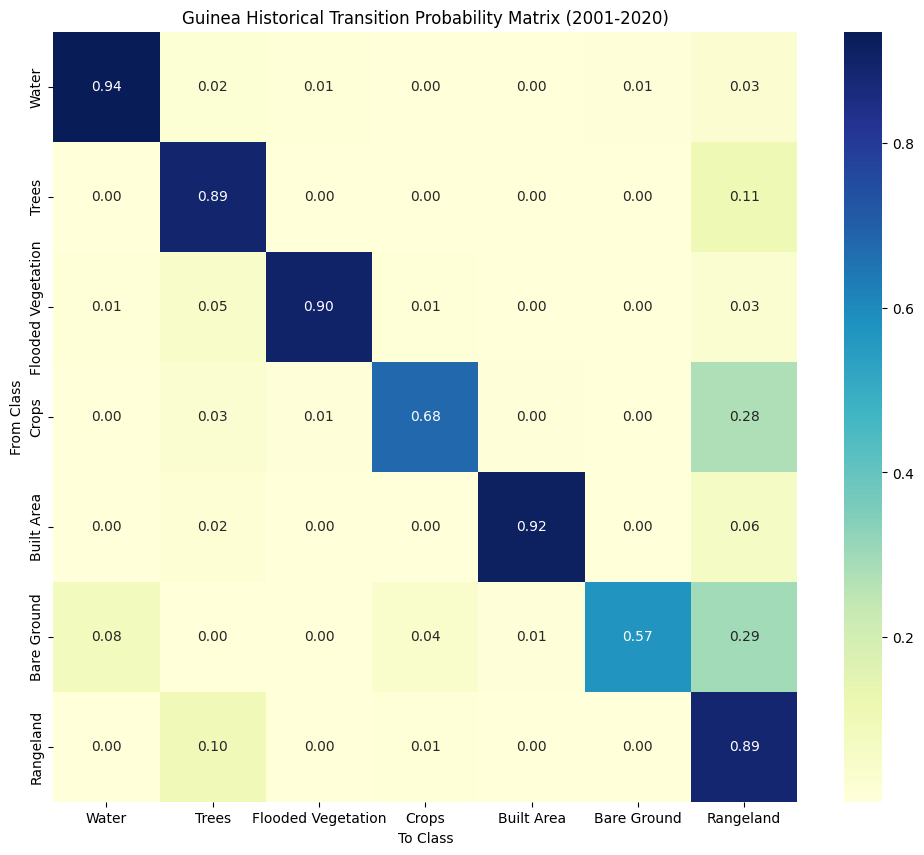

In [13]:
def calculate_markov_transitions(targets, mask, labels):
    """
    Analyzes historical sequence to create a Transition Probability Matrix.
    """
    # Use only valid pixels within the Guinea mask
    valid_pixels = mask
    num_years = targets.shape[0]
    all_classes = np.unique(targets[(targets != 0) & (targets != 10) & (targets != 255)])
    n = len(all_classes)
    
    # Initialize Transition Matrix (From x To)
    transition_counts = np.zeros((n, n))

    # Analyze sequence: 2001->2005, 2005->2010, etc.
    for i in range(num_years - 1):
        t1 = targets[i][valid_pixels]
        t2 = targets[i+1][valid_pixels]
        
        for start_idx, start_class in enumerate(all_classes):
            for end_idx, end_class in enumerate(all_classes):
                # Count pixels that moved from start_class to end_class
                count = np.sum((t1 == start_class) & (t2 == end_class))
                transition_counts[start_idx, end_idx] += count

    # Normalize to get Probabilities (rows sum to 1)
    row_sums = transition_counts.sum(axis=1)
    # Avoid division by zero
    prob_matrix = np.divide(transition_counts, row_sums[:, np.newaxis], 
                            where=row_sums[:, np.newaxis] != 0)
    
    return pd.DataFrame(prob_matrix, index=labels, columns=labels)

# Generate the Matrix
tm_df = calculate_markov_transitions(targets, mask, ordered_labels)

# Visualize the Matrix
plt.figure(figsize=(12, 10))
sns.heatmap(tm_df, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Guinea Historical Transition Probability Matrix (2001-2020)")
plt.ylabel("From Class")
plt.xlabel("To Class")
plt.show()

Project Future Land Cover (Markov Projection)

By treating the probability matrix as a state-transition model, we can project the total area expected for a future year (e.g., 2024 or 2030).

Interpretation: Projection -  Comparing your "Projected 2024" pixels with your actual "2024 Ground Truth" (once you load it) will tell you if the Markov process is sufficient or if you need the Random Forest's spatial predictors (like road distance and biomass) to get a more accurate map.  

In [15]:
def project_future_area(current_map, prob_matrix_df, steps=1):
    """
    Projects the pixel counts for a future year.
    steps=1 usually represents the average interval of your historical data.
    """
    # Get current pixel counts
    unique, counts = np.unique(current_map[(current_map != 0) & (current_map != 10) & (current_map != 255)], return_counts=True)
    current_state = np.array(counts)
    
    # Matrix Multiplication for Markov projection
    # Future State = Current State * (Transition Matrix ^ steps)
    P = prob_matrix_df.values
    future_state = current_state @ np.linalg.matrix_power(P, steps)
    
    projection = pd.DataFrame({
        'Class': prob_matrix_df.index,
        '2020_Actual_Pixels': current_state,
        'Projected_Future_Pixels': future_state.astype(int)
    })
    return projection

# Project to next period
projection_df = project_future_area(targets[-1], tm_df)
print(projection_df)

                Class  2020_Actual_Pixels  Projected_Future_Pixels
0               Water              203465                   193727
1               Trees             3919355                  3781822
2  Flooded Vegetation               55787                    57004
3               Crops               73455                    77843
4          Built Area               79832                    80918
5         Bare Ground                1239                     1911
6           Rangeland             2724594                  2864499


Analyze Non-Linear Trends (For Historical Land Cover Layers > 2

Interpretation: Non-Linearity - If the line for "Mining Areas" or "Urban" shows a sharp upward curve rather than a straight line, your future scenarios should account for accelerating growth.)

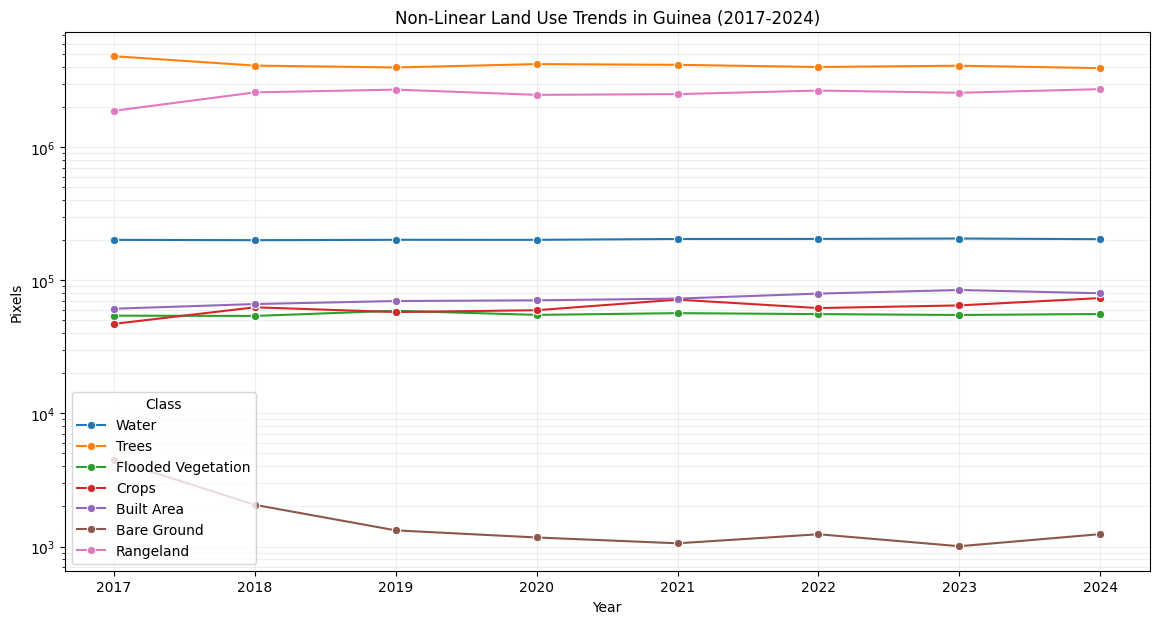

In [16]:
def plot_multitemporal_trends(targets, labels):
    import re as _re
    import os as _os
    years = sorted(int(_re.search(r"(\d{4})", _os.path.basename(_p)).group(1)) for _p in TARGET_RASTER)
    trend_data = []

    for i, year in enumerate(years):
        unique, counts = np.unique(targets[i][(targets[i] != 0) & (targets[i] != 10) & (targets[i] != 255)], return_counts=True)
        count_dict = dict(zip(unique, counts))
        # Look up each class's name DIRECTLY by its value (via class_names_map),
        # not by position in a separately-computed `labels` list -- the
        # positional version (labels[idx]) assumed `labels` was still aligned
        # with the current targets array's actual unique classes, which broke
        # once `labels` (ordered_labels) went stale relative to Stage 2's
        # larger class set. This can't misalign the same way again, since
        # it's keyed by the actual class value every time, not by list order.
        for class_val in np.unique(targets[(targets != 0) & (targets != 10) & (targets != 255)]):
            trend_data.append({
                "Year": year,
                "Class": class_names_map.get(int(class_val), f"Class {class_val}"),
                "Pixels": count_dict.get(class_val, 0)
            })

    df_trend = pd.DataFrame(trend_data)

    plt.figure(figsize=(14, 7))
    sns.lineplot(data=df_trend, x="Year", y="Pixels", hue="Class", marker='o')

    plt.xticks(years)
    plt.yscale('log')  # Log scale helps see small classes alongside dominant ones
    plt.title(f"Non-Linear Land Use Trends in Guinea ({years[0]}-{years[-1]})")
    plt.grid(True, which="both", ls="-", alpha=0.2)
    plt.show()

plot_multitemporal_trends(targets, ordered_labels)


### Genuine non-linear trend fitting (new)

The plot above is diagnostic only -- it shows whether a class *looks*
non-linear but doesn't fit or extrapolate anything. This section actually
fits linear / exponential / logistic candidate models to each transition's
historical rate and selects the best-supported one by corrected AIC (AICc,
appropriate given only ~4 historical intervals per transition), rather than
assuming linearity by default.

Model selection across 42 transitions: 38 linear, 4 exponential, 0 logistic

              from                 to       model  avg_historical_rate_px_yr  projected_rate_px_yr  projected_pixels_next_period
             Trees          Rangeland      linear              239343.142857         118507.714286                        829554
         Rangeland              Trees      linear              162568.571429         196620.571429                       1376344
         Rangeland              Crops      linear               13740.857143          14996.285714                        104974
             Crops          Rangeland      linear               11507.285714          13226.714286                         92587
         Rangeland         Built Area      linear                3127.000000           3391.000000                         23737
        Built Area          Rangeland      linear                2672.571429           4328.428571                         30299
             Trees  

C:\Users\ASUS\AppData\Local\Temp\ipykernel_29960\2617008782.py:186: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


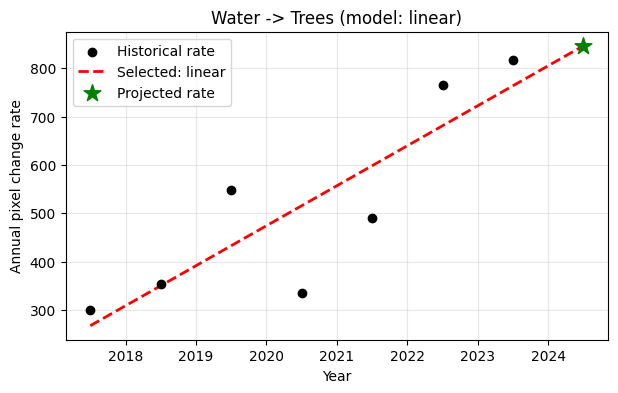

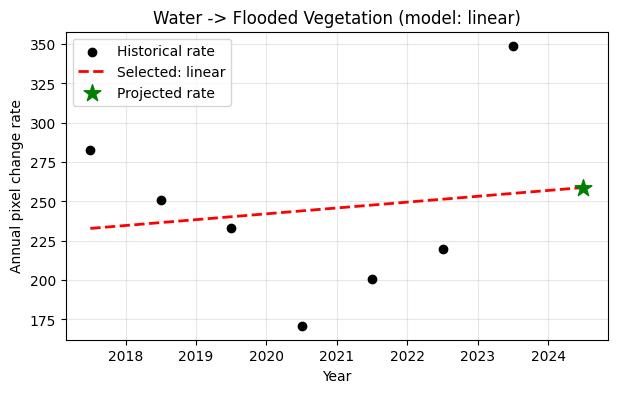

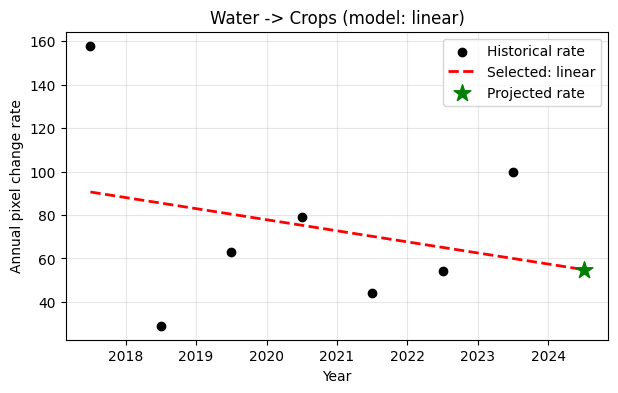

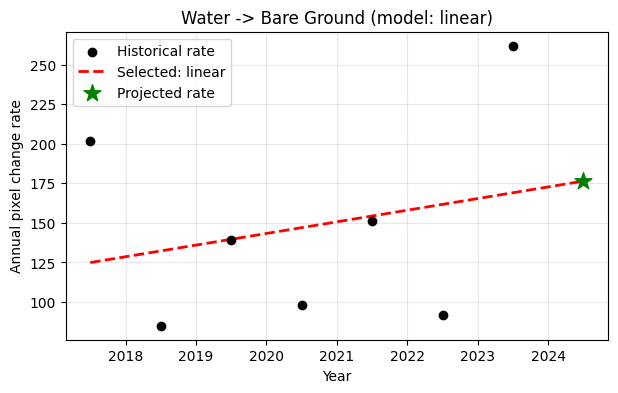

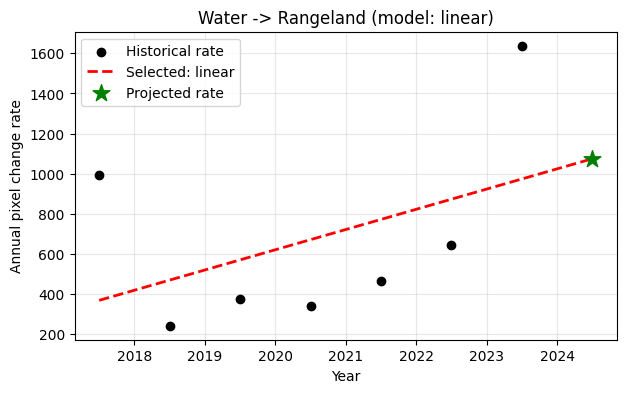

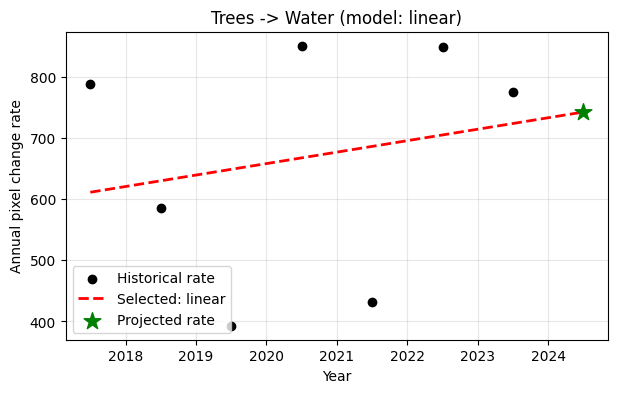

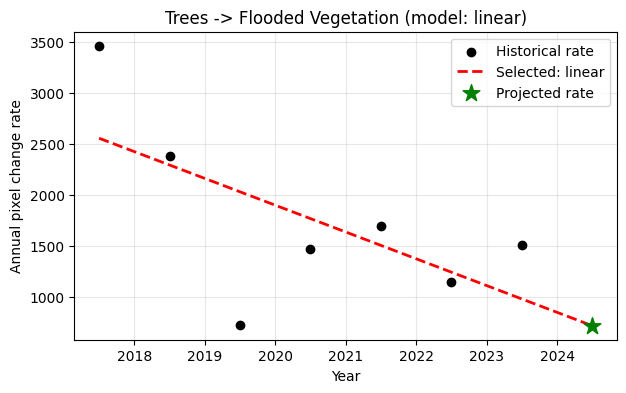

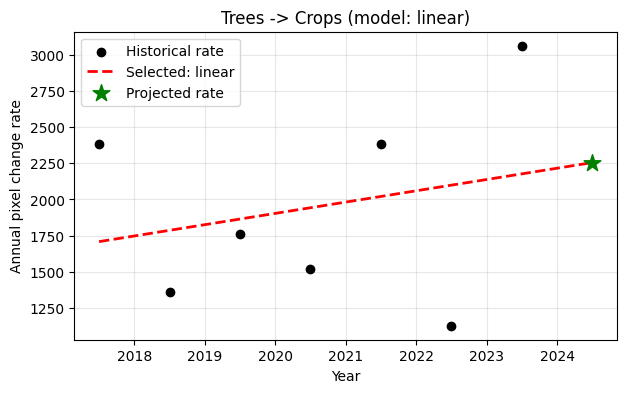

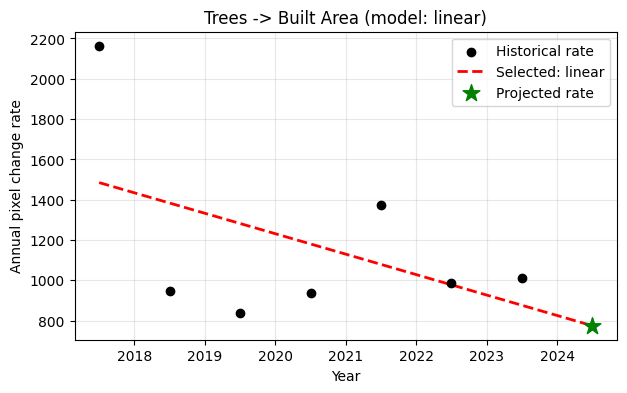

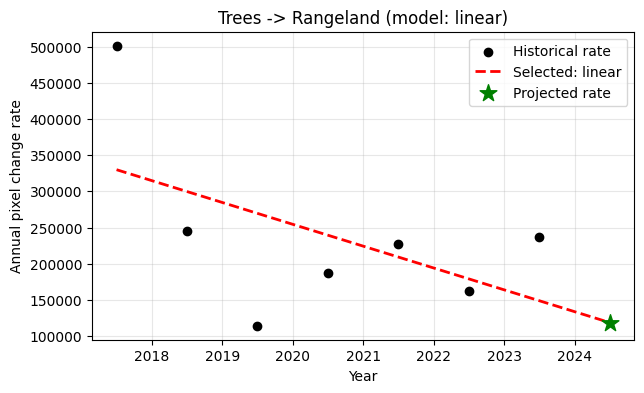

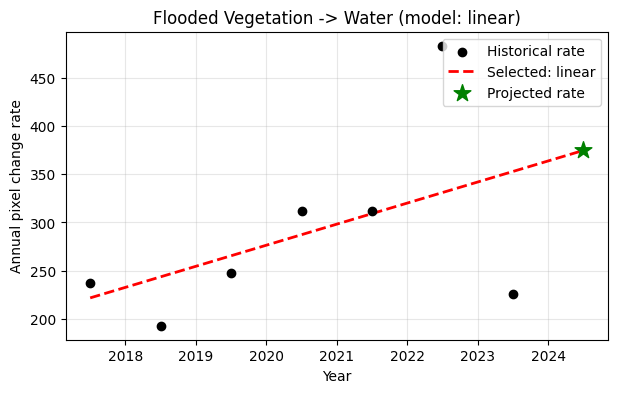

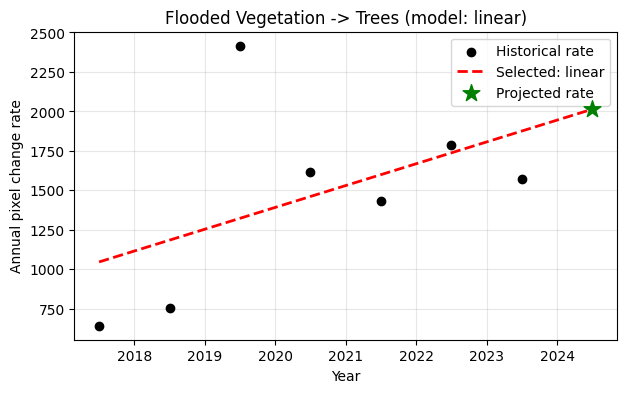

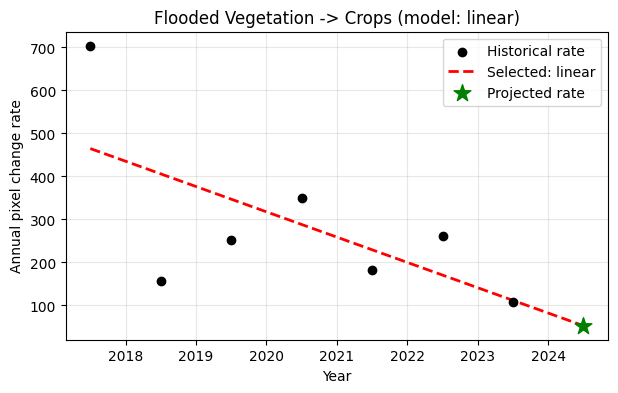

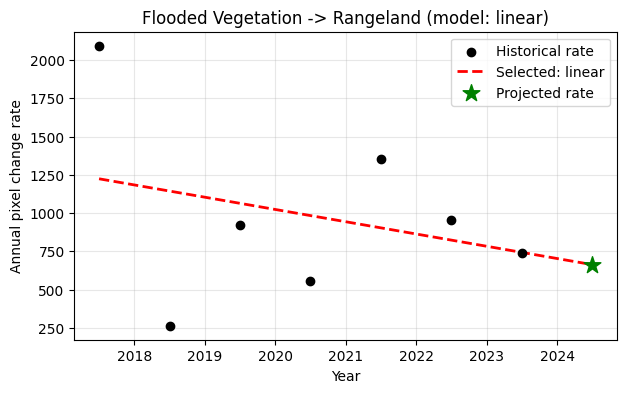

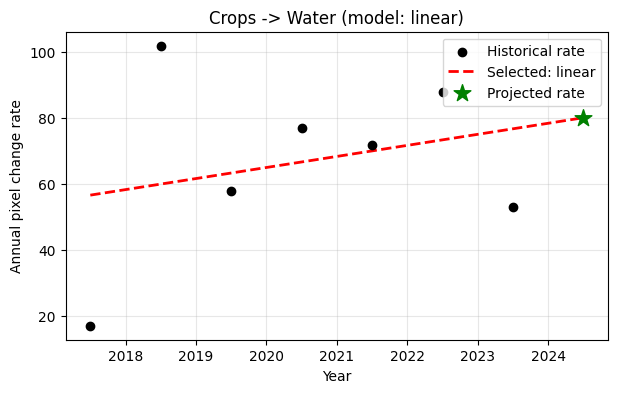

In [17]:
# --- Candidate trend models ---
def _model_linear(x, a, b):
    return a * x + b

def _model_exponential(x, a, b):
    return a * np.exp(b * x)

def _model_logistic(x, L, k, x0):
    return L / (1.0 + np.exp(-k * (x - x0)))

def _aicc(y_true, y_pred, n_params):
    n = len(y_true)
    rss = max(float(np.sum((np.asarray(y_true) - np.asarray(y_pred)) ** 2)), 1e-9)
    aic = n * np.log(rss / n) + 2 * n_params
    denom = n - n_params - 1
    if denom > 0:
        aic += (2 * n_params * (n_params + 1)) / denom
    return aic

def fit_transition_curve(years, rates, future_x, min_points_exponential=3,
                          min_points_logistic=5, delta_aicc_threshold=2.0):
    """
    Fit linear/exponential/logistic candidates to one transition's
    (years, annualized-rate) series, select the best by AICc (requiring a
    more complex model to beat a simpler one by > delta_aicc_threshold --
    Occam's razor). Returns None if even the linear fit fails.
    """
    years = np.asarray(years, dtype=float)
    rates = np.asarray(rates, dtype=float)
    if np.allclose(rates, 0):
        return None

    candidates = {}

    try:
        A = np.vstack([years, np.ones_like(years)]).T
        (a, b), *_ = np.linalg.lstsq(A, rates, rcond=None)
        pred = a * years + b
        candidates["linear"] = {
            "aicc": _aicc(rates, pred, 2),
            "predict": lambda x, a=a, b=b: a * np.asarray(x) + b,
            "params": {"a": float(a), "b": float(b)},
        }
    except Exception as e:
        print(f"  linear fit failed: {e}")

    if len(years) >= min_points_exponential and np.all(rates >= 0):
        try:
            a0 = max(np.mean(rates), 1e-3)
            popt, _ = curve_fit(_model_exponential, years - years.min(), rates,
                                 p0=[a0, 0.01], maxfev=5000)
            pred = _model_exponential(years - years.min(), *popt)
            candidates["exponential"] = {
                "aicc": _aicc(rates, pred, 2),
                "predict": lambda x, p=popt, x0=years.min(): _model_exponential(np.asarray(x) - x0, *p),
                "params": {"a": float(popt[0]), "b": float(popt[1])},
            }
        except Exception as e:
            print(f"  exponential fit failed: {e}")

    if len(years) >= min_points_logistic and np.all(rates >= 0) and np.max(rates) > 0:
        try:
            L0 = np.max(rates) * 1.5
            x0_0 = np.median(years)
            bounds = ([np.max(rates), -10, years.min() - 20],
                      [np.max(rates) * 5, 10, years.max() + 20])
            popt, _ = curve_fit(_model_logistic, years, rates,
                                 p0=[L0, 0.5, x0_0], bounds=bounds, maxfev=10000)
            pred = _model_logistic(years, *popt)
            candidates["logistic"] = {
                "aicc": _aicc(rates, pred, 3),
                "predict": lambda x, p=popt: _model_logistic(np.asarray(x), *p),
                "params": {"L": float(popt[0]), "k": float(popt[1]), "x0": float(popt[2])},
            }
        except Exception as e:
            print(f"  logistic fit failed: {e}")

    if not candidates:
        return None

    order = [m for m in ("linear", "exponential", "logistic") if m in candidates]
    best = order[0]
    for name in order[1:]:
        if candidates[name]["aicc"] < candidates[best]["aicc"] - delta_aicc_threshold:
            best = name

    predicted_rate = float(max(0.0, candidates[best]["predict"]([future_x])[0]))
    return {"model": best, "predicted_rate": predicted_rate,
            "predict": candidates[best]["predict"],
            "candidates": {k: v["aicc"] for k, v in candidates.items()}}


def analyze_true_nonlinear_trends(targets, mask, years, class_names_map,
                                   min_avg_rate_for_plot=50, max_plots=15):
    """
    Fits genuine linear/exponential/logistic trends per transition using the
    in-memory `targets` stack (not files), operating on the same mask/nodata
    convention used throughout this notebook.
    """
    periods = []
    for i in range(len(years) - 1):
        t1, t2 = targets[i], targets[i + 1]
        duration = years[i + 1] - years[i]
        valid = mask & (t1 != 0) & (t1 != 10) & (t1 != 255) & (t2 != 0) & (t2 != 10) & (t2 != 255)
        classes = np.unique(np.concatenate([t1[valid], t2[valid]]))
        counts = pd.DataFrame(0.0, index=classes, columns=classes)
        for c1 in classes:
            row_mask = valid & (t1 == c1)
            if not row_mask.any():
                continue
            to_vals, to_counts = np.unique(t2[row_mask], return_counts=True)
            for c2, cnt in zip(to_vals, to_counts):
                if c2 in counts.columns:
                    counts.loc[c1, c2] = cnt
        periods.append({"midpoint": years[i] + duration / 2, "duration": duration,
                         "rates": counts / duration})

    all_classes = sorted(set().union(*[set(p["rates"].index) for p in periods]))
    period_years = np.array([p["midpoint"] for p in periods])
    future_midpoint = periods[-1]["midpoint"] + periods[-1]["duration"]
    total_span = years[-1] - years[0]

    rows, figs, n_plotted = [], [], 0
    for f in all_classes:
        for t in all_classes:
            if f == t:
                continue
            series = np.array([
                p["rates"].loc[f, t] if (f in p["rates"].index and t in p["rates"].columns) else 0.0
                for p in periods
            ])
            if np.allclose(series, 0):
                continue
            fit = fit_transition_curve(period_years, series, future_midpoint)
            if fit is None:
                continue

            f_name = class_names_map.get(f, f"Class {f}")
            t_name = class_names_map.get(t, f"Class {t}")
            rows.append({
                "from": f_name, "to": t_name, "model": fit["model"],
                "avg_historical_rate_px_yr": series.mean(),
                "projected_rate_px_yr": fit["predicted_rate"],
                "projected_pixels_next_period": int(round(fit["predicted_rate"] * total_span)),
            })

            if series.mean() > min_avg_rate_for_plot and n_plotted < max_plots:
                fig, ax = plt.subplots(figsize=(7, 4))
                ax.scatter(period_years, series, color="black", zorder=5, label="Historical rate")
                xs = np.linspace(period_years.min(), future_midpoint, 100)
                ax.plot(xs, fit["predict"](xs), "r--", linewidth=2, label=f"Selected: {fit['model']}")
                ax.scatter([future_midpoint], [fit["predicted_rate"]], color="green",
                           marker="*", s=160, zorder=6, label="Projected rate")
                ax.set_title(f"{f_name} -> {t_name} (model: {fit['model']})")
                ax.set_xlabel("Year"); ax.set_ylabel("Annual pixel change rate")
                ax.legend(); ax.grid(alpha=0.3)
                figs.append(fig)
                n_plotted += 1

    summary = pd.DataFrame(rows).sort_values("avg_historical_rate_px_yr", ascending=False)
    return summary, figs


import os as _os
import re as _re
# Stage-agnostic: parses the year from each TARGET_RASTER filename
# (works for both "Guinea_LandCover_2001.tif" style Stage 1 names and
# "ESRI_LULC_2017.tif" style Stage 2 names) instead of a hardcoded list --
# the old hardcoded [2001, 2005, 2010, 2015, 2020] was Stage-1-only and
# silently wrong for Stage 2's actual 2017-2024 annual series.
years = sorted(int(_re.search(r"(\d{4})", _os.path.basename(_p)).group(1)) for _p in TARGET_RASTER)

nonlinear_summary, nonlinear_figs = analyze_true_nonlinear_trends(
    targets, mask, years, class_names_map
)

n_lin = (nonlinear_summary["model"] == "linear").sum()
n_exp = (nonlinear_summary["model"] == "exponential").sum()
n_log = (nonlinear_summary["model"] == "logistic").sum()
print(f"Model selection across {len(nonlinear_summary)} transitions: "
      f"{n_lin} linear, {n_exp} exponential, {n_log} logistic")
print()
print(nonlinear_summary.to_string(index=False))

for fig in nonlinear_figs:
    fig.show()


# Map Future Suitability

Specialized Growth Mode Training (Expander vs Patcher)

This logic splits changed pixels into two distinct growth behaviors: Expander (edge growth) and Patcher (spontaneous/isolated growth).  

## Expander Model

The Expander model focuses on "edge growth". It is trained specifically on pixels that transitioned into a new class while being directly adjacent to existing patches of that class.  

Dynamic Neighborhood Predictors

The following script generates neighborhood density rasters. These treat pixels as "spatially aware" by calculating how much of a target class exists within a user-defined radius, simulating the "contagion" effect of land use.  

This stage allows the user to define the radius. The significance of a neighbor 3 pixels away (local expansion) is very different from a neighbor 20 pixels away (regional pressure). Putting it here gives you the flexibility to adjust this numerical parameter for each specialized model.

The DNP is the primary engine for the Expander model. It allows the AI to quantify the "edge effect". Without a neighborhood predictor, the model would only look at static variables like elevation or distance to roads, missing the fact that land use often "spreads" from existing patches.

In [18]:
def create_neighborhood_predictor(mask, land_cover, target_class_id, radius=3):
    """
    Calculates the density of a target class within a circular radius.
    Improves spatial context by identifying 'neighborhood' influence.
    """
    # Create binary map of the target class
    binary_target = (land_cover == target_class_id).astype(float)
    
    # Define circular kernel
    y, x = np.ogrid[-radius: radius+1, -radius: radius+1]
    kernel = x**2 + y**2 <= radius**2
    
    # Calculate density (percentage of neighbors that are the target class)
    density = generic_filter(binary_target, np.mean, footprint=kernel)
    
    return np.where(mask, density, np.nan)

# Example: Influence of existing Urban areas on neighbors (Radius = 5 pixels)
# urban_neighborhood = create_neighborhood_predictor(mask, targets[-1], 10, radius=5)

In [19]:
from xml.parsers.expat import model


def run_expander_suitability(X_stack, targets, mask, from_class, to_class, radius=3):
    """
    Independent workflow for Expander (Edge-based) Suitability.
    """
    # 1. Spatial Awareness: Add local neighborhood density as a predictor
    neighborhood_feat = create_neighborhood_predictor(mask, targets[-1], to_class, radius=radius)
    X_enhanced = np.vstack([X_stack, [neighborhood_feat]])
    
    # 2. Identify Expander Pixels: Changed pixels adjacent to existing target patches[cite: 1, 3]
    change_mask = (targets[-2] == from_class) & (targets[-1] == to_class)
    existing_patches = (targets[-2] == to_class)
    adjacent_to_existing = binary_dilation(existing_patches, structure=np.ones((3,3)))
    expander_samples = change_mask & adjacent_to_existing
    
    # 3. Balanced Training[cite: 3, 6]
    n_samples = np.sum(expander_samples)
    persistence_mask = (targets[-2] == from_class) & (targets[-1] == from_class)
    persist_idx = np.where(persistence_mask.flatten())[0]

    n_persist_available = len(persist_idx)
    n_to_draw = min(n_samples, n_persist_available)

    if n_to_draw < n_samples:
        print(f"  Warning: class {from_class} has only {n_persist_available} persistence "
            f"pixels (2015-2020 stable), requested {n_samples} — using all available.")

    if n_to_draw == 0:
        print(f"  Skipping {from_class}->{to_class}: no persistence pixels at all — "
            f"this transition can't be modeled with a balanced persistence/change design.")

    selected_persist = np.random.choice(persist_idx, n_to_draw, replace=False)
    change_idx = np.where(expander_samples.flatten())[0]
    
    # 4. Train
    X_flat = X_enhanced.reshape(X_enhanced.shape[0], -1).T

    train_idx = np.concatenate([change_idx, selected_persist])

    n_change = len(change_idx)
    n_persist = len(selected_persist)
    labels = np.concatenate([np.ones(n_change), np.zeros(n_persist)])

    # Reduce parallelism to cut per-worker memory duplication.
    # n_jobs=-1 on a 2M-row array is often the actual culprit here --
    # try 2-4 first, not 1, so you don't lose all your speed at once.
    model = RandomForestClassifier(n_estimators=100, n_jobs=4, random_state=42, class_weight="balanced")
    model.fit(X_flat[train_idx], labels)

    # Predict the full map in batches instead of one 2M-row call --
    # caps peak memory regardless of n_jobs.
    def predict_proba_batched(model, X, batch_size=200_000):
        out = np.empty(X.shape[0], dtype=np.float32)
        for start in range(0, X.shape[0], batch_size):
            end = min(start + batch_size, X.shape[0])
            out[start:end] = model.predict_proba(X[start:end])[:, 1]
        return out

    prob_map = predict_proba_batched(model, X_flat).reshape(mask.shape)
    
    print(f"Expander Model ({from_class}->{to_class}) Training Complete.")
    return prob_map, model  # model.feature_importances_ available on the returned model

## Patcher Model

The Patcher model ignores the edges and looks specifically for the environmental conditions that trigger brand-new, isolated clusters of land use, such as spontaneous new mining sites or remote agricultural clearings.  

In [20]:
def run_patcher_suitability(X_stack, targets, mask, from_class, to_class):
    """
    Independent workflow for Patcher (Spontaneous) Suitability with safety
    checks. X_stack: the raw (n_features, H, W) predictor stack, already
    nan_to_num'd (pass X_model_ready_clean) but NOT yet flattened -- this
    function reshapes internally, same as run_expander_suitability does.
    """
    # 1. Identify Patcher Pixels
    change_mask = (targets[-2] == from_class) & (targets[-1] == to_class)
    existing_patches = (targets[-2] == to_class)
    adjacent_to_existing = binary_dilation(existing_patches, structure=np.ones((3,3)))
    patcher_samples = change_mask & ~adjacent_to_existing

    n_change = np.sum(patcher_samples)
    if n_change == 0:
        print(f"Skipping Patcher {from_class}->{to_class}: No isolated growth detected.")
        return np.zeros(mask.shape, dtype=np.float32), None

    # 2. Balanced Training -- cap persistence draw to what's actually
    # available (same fix applied to Expander: some classes, e.g. 4, have
    # far fewer stable pixels than change pixels).
    persistence_mask = (targets[-2] == from_class) & (targets[-1] == from_class)
    persist_idx = np.where(persistence_mask.flatten())[0]
    n_persist_available = len(persist_idx)
    n_to_draw = min(n_change, n_persist_available)

    if n_to_draw == 0:
        print(f"Skipping Patcher {from_class}->{to_class}: no persistence pixels available.")
        return np.zeros(mask.shape, dtype=np.float32), None
    if n_to_draw < n_change:
        print(f"  Note: class {from_class} has only {n_persist_available} persistence pixels, "
              f"requested {n_change} -- using all available (imbalanced; "
              f"class_weight='balanced' applied below).")

    selected_persist = np.random.choice(persist_idx, n_to_draw, replace=False)
    change_idx = np.where(patcher_samples.flatten())[0]

    # 3. Reshape ONCE per call (cheap relative to training/prediction; the
    # expensive step -- nan_to_num on the full 2M-row array -- already
    # happened once, outside this loop, in X_model_ready_clean).
    X_flat = X_stack.reshape(X_stack.shape[0], -1).T

    # Labels built from ACTUAL concatenated lengths, not from n_change/
    # n_to_draw directly (this exact mismatch crashed Expander earlier on
    # class 4; fixed here before it hits Patcher the same way).
    train_idx = np.concatenate([change_idx, selected_persist])
    labels = np.concatenate([np.ones(len(change_idx)), np.zeros(len(selected_persist))])

    model = RandomForestClassifier(n_estimators=100, n_jobs=4, random_state=42,
                                    class_weight="balanced")
    model.fit(X_flat[train_idx], labels)

    # 4. Batched prediction -- caps peak memory regardless of n_jobs (this is
    # what crashed originally: one 2,023,632-row predict_proba call across
    # n_jobs=-1 worker processes, each needing its own copy of the array).
    def _predict_proba_batched(model, X, batch_size=200_000):
        out = np.empty(X.shape[0], dtype=np.float32)
        for start in range(0, X.shape[0], batch_size):
            end = min(start + batch_size, X.shape[0])
            out[start:end] = model.predict_proba(X[start:end])[:, 1]
        return out

    prob_map = _predict_proba_batched(model, X_flat).reshape(mask.shape)

    print(f"Patcher Model ({from_class}->{to_class}) Training Complete.")
    return prob_map, model


## Apply Suitability Mapping

Execution and Suitability Mapping

This loop creates a collection of probability maps for every plausible transition identified in the Markov analysis.  

Defining Significance:

- Class transition
- Transition pixel count
- Percent of total change
- Net vs. Swap Change: A class might have many pixels change into it and many out of it, resulting in zero net change but massive "swap" change. High swap change indicates a very dynamic and important process to model, even if the total area stays the same.
- Probability threshold from Markov Transition Matrix

Intensity Analysis Framework (Pontius Jr, R. G., & Millones, M. (2011). Death to Kappa: making the case for a missing components of accuracy. International Journal of Remote Sensing.)
- Analyze the intensity of the change. 
- A transition is "significant" if the transition intensity is greater than the uniform intensity of the entire map. 
- For example, in Guinea, if "Dense Forest to Mining" happens at a rate much higher than the average rate of change on the whole map, it is significant even if the total pixel count is relatively small.

"Automate the selection of transitions for the suitability mapping using a combination of a minimum pixel threshold and the Intensity logic."

In [21]:
def build_transition_matrices(targets, mask, years):
    """Shared helper: one from->to pixel-count DataFrame per interval."""
    matrices, durations = [], []
    for i in range(len(years) - 1):
        t1, t2 = targets[i], targets[i + 1]
        duration = years[i + 1] - years[i]
        valid = mask & (t1 != 0) & (t1 != 10) & (t1 != 255) & (t2 != 0) & (t2 != 10) & (t2 != 255)
        classes = np.unique(np.concatenate([t1[valid], t2[valid]]))
        counts = pd.DataFrame(0.0, index=classes, columns=classes)
        for c1 in classes:
            row_mask = valid & (t1 == c1)
            if not row_mask.any():
                continue
            to_vals, to_counts = np.unique(t2[row_mask], return_counts=True)
            for c2, cnt in zip(to_vals, to_counts):
                if c2 in counts.columns:
                    counts.loc[c1, c2] = cnt
        matrices.append(counts)
        durations.append(duration)
    return matrices, durations


def interval_level_intensity(matrices, durations):
    rows = []
    total_changed, total_duration_area = 0.0, 0.0
    for m, dur in zip(matrices, durations):
        total_pixels = float(m.values.sum())
        changed = float(m.values.sum() - np.trace(m.values))
        s_t = 100.0 * changed / (dur * total_pixels) if dur > 0 and total_pixels > 0 else 0.0
        rows.append({"duration_years": dur, "total_pixels": total_pixels,
                      "changed_pixels": changed, "interval_intensity_pct_per_yr": s_t})
        total_changed += changed
        total_duration_area += dur * total_pixels
    U = 100.0 * total_changed / total_duration_area if total_duration_area > 0 else 0.0
    df = pd.DataFrame(rows)
    df["faster_than_uniform"] = df["interval_intensity_pct_per_yr"] > U
    df.attrs["U"] = U
    return df


def category_level_intensity(matrices, durations, class_names_map):
    interval_df = interval_level_intensity(matrices, durations)
    rows = []
    for t, (m, dur) in enumerate(zip(matrices, durations)):
        s_t = interval_df.loc[t, "interval_intensity_pct_per_yr"]
        classes = sorted(set(m.index) | set(m.columns))
        m = m.reindex(index=classes, columns=classes, fill_value=0)
        for cls in classes:
            initial_area = float(m.loc[cls, :].sum())
            final_area = float(m.loc[:, cls].sum())
            loss = float(m.loc[cls, :].sum() - m.loc[cls, cls])
            gain = float(m.loc[:, cls].sum() - m.loc[cls, cls])
            l_ti = 100.0 * loss / (dur * initial_area) if dur > 0 and initial_area > 0 else 0.0
            g_ti = 100.0 * gain / (dur * final_area) if dur > 0 and final_area > 0 else 0.0
            rows.append({
                "interval": t, "category": class_names_map.get(cls, f"Class {cls}"),
                "loss_intensity_pct_yr": l_ti, "gain_intensity_pct_yr": g_ti,
                "interval_uniform_pct_yr": s_t,
                "actively_losing": l_ti > s_t, "actively_gaining": g_ti > s_t,
            })
    return pd.DataFrame(rows)


def transition_level_intensity(matrices, durations, class_names_map, target_categories=None):
    rows = []
    for t, (m, dur) in enumerate(zip(matrices, durations)):
        classes = sorted(set(m.index) | set(m.columns))
        m = m.reindex(index=classes, columns=classes, fill_value=0)
        total_pixels = float(m.values.sum())
        for to_cls in classes:
            if target_categories and to_cls not in target_categories:
                continue
            final_area_n = float(m.loc[:, to_cls].sum())
            persistence_n = float(m.loc[to_cls, to_cls])
            denom = dur * (total_pixels - final_area_n)
            u_tn = 100.0 * (final_area_n - persistence_n) / denom if denom > 0 else 0.0
            for from_cls in classes:
                if from_cls == to_cls:
                    continue
                if target_categories and from_cls not in target_categories:
                    continue
                y_tmn = float(m.loc[from_cls, to_cls])
                initial_area_m = float(m.loc[from_cls, :].sum())
                r_tmn = 100.0 * y_tmn / (dur * initial_area_m) if dur > 0 and initial_area_m > 0 else 0.0
                rows.append({
                    "interval": t,
                    "from": class_names_map.get(from_cls, f"Class {from_cls}"),
                    "to": class_names_map.get(to_cls, f"Class {to_cls}"),
                    "transition_intensity_pct_yr": r_tmn,
                    "uniform_gain_intensity_pct_yr": u_tn,
                    "targeted": r_tmn > u_tn,
                })
    return pd.DataFrame(rows)


# --- Run all three levels ---
import os as _os
import re as _re
# Stage-agnostic: parses the year from each TARGET_RASTER filename
# (works for both "Guinea_LandCover_2001.tif" style Stage 1 names and
# "ESRI_LULC_2017.tif" style Stage 2 names) instead of a hardcoded list --
# the old hardcoded [2001, 2005, 2010, 2015, 2020] was Stage-1-only and
# silently wrong for Stage 2's actual 2017-2024 annual series.
years = sorted(int(_re.search(r"(\d{4})", _os.path.basename(_p)).group(1)) for _p in TARGET_RASTER)

_matrices, _durations = build_transition_matrices(targets, mask, years)

interval_df = interval_level_intensity(_matrices, _durations)
print(f"Uniform annual intensity U = {interval_df.attrs['U']:.3f}%/yr")
print(interval_df.to_string(index=False))
print()

category_df = category_level_intensity(_matrices, _durations, class_names_map)
print("Category-level intensity (interval 3, 2015-2020):")
print(category_df[category_df["interval"] == 3].sort_values(
    "gain_intensity_pct_yr", ascending=False).to_string(index=False))
print()

# Transition-level: restrict to classes involved in significant_transitions
# once that's computed below, to avoid an unreadably large all-pairs table.
# Run on all classes for now to see the full picture at the last interval.
transition_df = transition_level_intensity(_matrices, _durations, class_names_map)
print("Transition-level intensity (interval 3, 2015-2020) -- targeted transitions only:")
print(transition_df[(transition_df["interval"] == 3) & (transition_df["targeted"])]
      .sort_values("transition_intensity_pct_yr", ascending=False).to_string(index=False))


Uniform annual intensity U = 11.136%/yr
 duration_years  total_pixels  changed_pixels  interval_intensity_pct_per_yr  faster_than_uniform
              1     4025213.0        590584.0                      14.672118                 True
              1     4025213.0        453527.0                      11.267155                 True
              1     4025211.0        437421.0                      10.867033                False
              1     4025208.0        390128.0                       9.692120                False
              1     4025210.0        420839.0                      10.455082                False
              1     4025213.0        415567.0                      10.324100                False
              1     4025213.0        429702.0                      10.675261                False

Category-level intensity (interval 3, 2015-2020):
 interval           category  loss_intensity_pct_yr  gain_intensity_pct_yr  interval_uniform_pct_yr  actively_losing  activel

**Implemented.** The three levels above answer, in order: is 2015-2020
change faster or slower than the historical average (interval)? which
categories are gaining/losing faster than the study-area-wide average
(category)? and for a given gaining category, does it draw
disproportionately from a specific source category -- i.e. is a transition
systematic rather than incidental (transition)? Reference: Aldwaik, S.Z. &
Pontius Jr, R.G. (2012), *Landscape and Urban Planning*, 106(1), 103-114.

### Expander

In [22]:
def select_significant_transitions(targets, labels, min_pixels=1000):
    """
    Automatically identifies significant transitions based on a pixel
    threshold. Default min_pixels=1000: enough training samples for a
    stable balanced Random Forest per transition (see config.py
    MIN_CHANGE_PIXELS_LAND_USE for the full statistical justification --
    this is independently justified, NOT required to match the
    Deforestation module's own threshold on its own resolution).
    """
    t1 = targets[-2] # 2015
    t2 = targets[-1] # 2020
    
    unique_classes = np.unique(targets[(targets != 0) & (targets != 10) & (targets != 255)])
    significant_list = []
    
    print(f"{'Transition':<35} | {'Pixels':<10} | {'Status'}")
    print("-" * 60)
    
    for i, from_val in enumerate(unique_classes):
        for j, to_val in enumerate(unique_classes):
            if from_val == to_val: continue
            
            # Count changes
            count = np.sum((t1 == from_val) & (t2 == to_val))
            from_name = labels[i]
            to_name = labels[j]
            
            status = "SELECTED" if count >= min_pixels else "SKIPPED (Too Small)"
            if count >= min_pixels:
                significant_list.append((from_val, to_val))
            
            # Print report for the user
            if count > 0:
                print(f"{from_name[:15]} -> {to_name[:15]:<15} | {count:<10} | {status}")
                
    return significant_list

# Run selection with a threshold of 1000 pixels for stability
significant_transitions = select_significant_transitions(targets, ordered_labels, min_pixels=1000)

Transition                          | Pixels     | Status
------------------------------------------------------------
Water -> Trees           | 1473       | SELECTED
Water -> Flooded Vegetat | 719        | SKIPPED (Too Small)
Water -> Crops           | 151        | SKIPPED (Too Small)
Water -> Built Area      | 30         | SKIPPED (Too Small)
Water -> Bare Ground     | 377        | SKIPPED (Too Small)
Water -> Rangeland       | 2275       | SELECTED
Trees -> Water           | 1362       | SELECTED
Trees -> Flooded Vegetat | 2729       | SELECTED
Trees -> Crops           | 4161       | SELECTED
Trees -> Built Area      | 1815       | SELECTED
Trees -> Bare Ground     | 5          | SKIPPED (Too Small)
Trees -> Rangeland       | 375436     | SELECTED
Flooded Vegetat -> Water           | 498        | SKIPPED (Too Small)
Flooded Vegetat -> Trees           | 2416       | SELECTED
Flooded Vegetat -> Crops           | 331        | SKIPPED (Too Small)
Flooded Vegetat -> Built Area      | 45

In [23]:
for f_class, t_class in significant_transitions:
    persistence_mask = (targets[-2] == f_class) & (targets[-1] == f_class)
    n_persist = persistence_mask.sum()
    print(f"{f_class} -> {t_class}: {n_persist} persistence pixels available")

1 -> 2: 200687 persistence pixels available
1 -> 11: 200687 persistence pixels available
2 -> 1: 3701542 persistence pixels available
2 -> 4: 3701542 persistence pixels available
2 -> 5: 3701542 persistence pixels available
2 -> 7: 3701542 persistence pixels available
2 -> 11: 3701542 persistence pixels available
4 -> 2: 49713 persistence pixels available
4 -> 11: 49713 persistence pixels available
5 -> 2: 45719 persistence pixels available
5 -> 11: 45719 persistence pixels available
7 -> 2: 74395 persistence pixels available
7 -> 11: 74395 persistence pixels available
11 -> 2: 2320965 persistence pixels available
11 -> 4: 2320965 persistence pixels available
11 -> 5: 2320965 persistence pixels available
11 -> 7: 2320965 persistence pixels available


In [24]:
import gc

# Precompute ONCE, outside the loop -- using the actual global variable name
X_model_ready_clean = np.nan_to_num(X_model_ready)

all_expander_maps = {}
all_expander_models = {}  # kept (not deleted) so feature importance can be extracted below

for f_class, t_class in significant_transitions:
    map_result, model = run_expander_suitability(
        X_model_ready_clean, targets, mask, f_class, t_class, radius=5
    )
    all_expander_maps[f"{f_class}_{t_class}"] = map_result
    all_expander_models[f"{f_class}_{t_class}"] = model

gc.collect()  # once, after the loop, not per-iteration -- keeping the 13 model
              # objects costs far less memory than the batched predict_proba
              # calls did; no need to delete them immediately anymore.


Expander Model (1->2) Training Complete.
Expander Model (1->11) Training Complete.
Expander Model (2->1) Training Complete.
Expander Model (2->4) Training Complete.
Expander Model (2->5) Training Complete.
Expander Model (2->7) Training Complete.
Expander Model (2->11) Training Complete.
Expander Model (4->2) Training Complete.
Expander Model (4->11) Training Complete.
Expander Model (5->2) Training Complete.
Expander Model (5->11) Training Complete.
Expander Model (7->2) Training Complete.
Expander Model (7->11) Training Complete.
Expander Model (11->2) Training Complete.
Expander Model (11->4) Training Complete.
Expander Model (11->5) Training Complete.
Expander Model (11->7) Training Complete.


12859

Available Expander transitions: ['1_2', '1_11', '2_1', '2_4', '2_5', '2_7', '2_11', '4_2', '4_11', '5_2', '5_11', '7_2', '7_11', '11_2', '11_4', '11_5', '11_7']


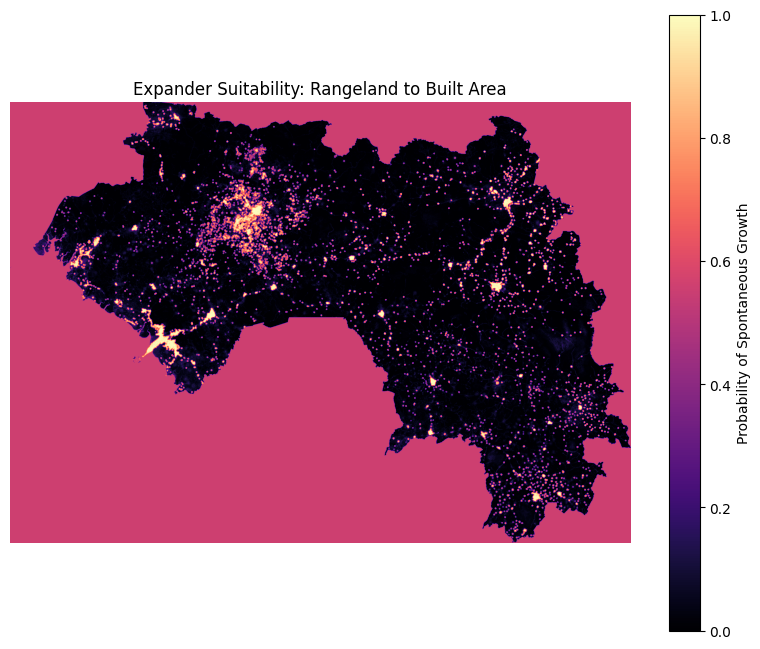

In [31]:
def plot_expander_results(all_expander_maps, from_class, to_class, labels=None):
    key = f"{from_class}_{to_class}"
    if key not in all_expander_maps or all_expander_maps[key] is None:
        print(f"No results for {key}")
        return

    # Direct lookup by class value via class_names_map, not by position in a
    # separately-computed `labels`/`unique_classes` pair -- that positional
    # version is exactly what broke in plot_multitemporal_trends once
    # `labels` went stale relative to the actual class set. `labels` param
    # kept (unused) so existing calls with a 4th argument don't need editing.
    from_name = class_names_map.get(from_class, f"Class {from_class}")
    to_name = class_names_map.get(to_class, f"Class {to_class}")

    plt.figure(figsize=(10, 8))
    plt.imshow(all_expander_maps[key], cmap='magma', vmin=0, vmax=1)
    plt.colorbar(label='Probability of Spontaneous Growth')
    plt.title(f"Expander Suitability: {from_name} to {to_name}")
    plt.axis('off')
    plt.show()


# Check what's actually available before picking an example pair --
# significant_transitions only contains real, trained transitions, which
# for ESRI-based Guinea data almost certainly does NOT include anything
# involving class 9 (Snow/Ice, essentially impossible in this climate).
print("Available Expander transitions:", list(all_expander_maps.keys()))

# Visualize the first available one as a working example -- replace with
# whichever specific pair you actually want once you see the list above.
if all_expander_maps:
    first_key = next(iter(all_expander_maps))
    f_id, t_id = map(int, first_key.split("_"))
    plot_expander_results(all_expander_maps, 11, 7)
else:
    print("all_expander_maps is empty -- check the Expander training cell ran successfully.")

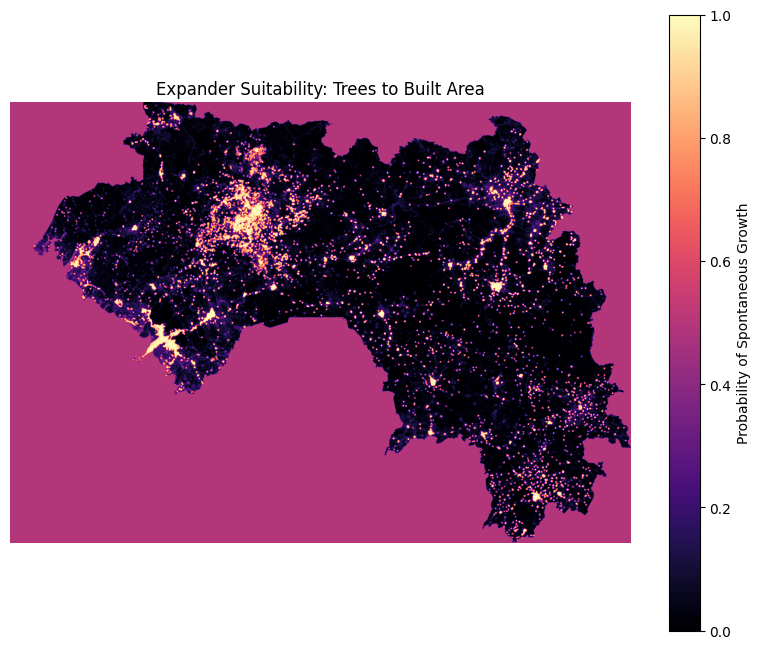

In [32]:
def plot_expander_results(all_expander_maps, from_class, to_class, labels):
    key = f"{from_class}_{to_class}"
    if key not in all_expander_maps or all_expander_maps[key] is None:
        print(f"No results for {key}")
        return

    from_name = labels[np.where(unique_classes == from_class)[0][0]]
    to_name = labels[np.where(unique_classes == to_class)[0][0]]

    plt.figure(figsize=(10, 8))
    # Use 'magma' or 'viridis' for probability gradients
    plt.imshow(all_expander_maps[key], cmap='magma', vmin=0, vmax=1)
    plt.colorbar(label='Probability of Spontaneous Growth')
    plt.title(f"Expander Suitability: {from_name} to {to_name}")
    plt.axis('off')
    plt.show()

# Example: Visualize Agriculture (8) to Fallow/Savanna (9)
plot_expander_results(all_expander_maps, 2, 7, ordered_labels)

In [33]:
summary_data = []
for key, map_data in all_expander_maps.items():
    if map_data is not None:
        mean_prob = np.nanmean(map_data[map_data > 0]) # Avg probability where > 0
        max_prob = np.nanmax(map_data)
        summary_data.append({"Transition": key, "Avg Suitability": mean_prob, "Max Potential": max_prob})

df_expander_summary = pd.DataFrame(summary_data)
print(df_expander_summary.sort_values(by="Avg Suitability", ascending=False))

   Transition  Avg Suitability  Max Potential
8        4_11         0.635754            1.0
9         5_2         0.604805            1.0
0         1_2         0.578222            1.0
10       5_11         0.550282            1.0
11        7_2         0.546942            1.0
13       11_2         0.525328            1.0
7         4_2         0.520000            1.0
6        2_11         0.484436            1.0
1        1_11         0.484280            1.0
14       11_4         0.468451            1.0
12       7_11         0.467004            1.0
3         2_4         0.415424            1.0
16       11_7         0.395325            1.0
5         2_7         0.352959            1.0
2         2_1         0.335165            1.0
4         2_5         0.322302            1.0
15       11_5         0.306068            1.0


In [34]:
def validate_expander_performance(all_expander_models, X_stack, targets, mask, radius=5):
    """
    Re-evaluates the accuracy of each expander model and provides reliability
    feedback.

    X_stack: raw (n_features, H, W), already nan_to_num'd (pass
    X_model_ready_clean) but not flattened.

    radius: MUST match whatever radius was used when training
    (run_expander_suitability's call site), since the neighborhood feature
    is transition-specific (computed per to_class) and its dimensionality/
    values depend on this parameter. Default 5 matches the current
    training loop's radius=5 -- update this if that ever changes.

    Class handling is fully dataset-agnostic: f_class/t_class are parsed
    directly from each model's key, and names are resolved through whatever
    class_names_map is currently loaded (MODIS, ESRI, or any future legend)
    rather than assuming a specific numeric scheme.
    """
    performance_results = []

    for key, model_obj in all_expander_models.items():
        if model_obj is None:
            continue

        f_class, t_class = map(int, key.split('_'))

        # Neighborhood feature is TRANSITION-SPECIFIC (depends on to_class),
        # so it must be recomputed per transition here, exactly matching
        # what run_expander_suitability appended during training -- this is
        # what was missing before (X_val had 11 features, the model expects
        # 12: the 11 base predictors + this one).
        neighborhood_feat = create_neighborhood_predictor(mask, targets[-1], t_class, radius=radius)
        X_enhanced = np.vstack([X_stack, [neighborhood_feat]])
        X_flat = X_enhanced.reshape(X_enhanced.shape[0], -1).T

        # 1. Re-identify the specific samples used for this transition
        change_mask = (targets[-2] == f_class) & (targets[-1] == t_class)
        existing_patches = (targets[-2] == t_class)
        adjacent_to_existing = binary_dilation(existing_patches, structure=np.ones((3, 3)))
        expander_samples = change_mask & adjacent_to_existing

        # 2. Balanced sampling for verification
        n_samples = np.sum(expander_samples)
        persistence_mask = (targets[-2] == f_class) & (targets[-1] == f_class)
        persist_idx = np.where(persistence_mask.flatten())[0]
        selected_persist = np.random.choice(persist_idx, min(n_samples, len(persist_idx)), replace=False)
        change_idx = np.where(expander_samples.flatten())[0]

        # 3. Prepare validation features
        val_idx = np.concatenate([change_idx, selected_persist])
        X_val = X_flat[val_idx]
        y_val = np.concatenate([np.ones(len(change_idx)), np.zeros(len(selected_persist))])

        # 4. Calculate accuracy
        acc = model_obj.score(X_val, y_val)

        # 5. Assign reliability status
        if acc > 0.85:
            status = "High Reliability (Strong Environmental Pattern)"
        elif acc < 0.60:
            status = "Low Reliability (Potential Random Growth)"
        else:
            status = "Moderate Reliability"

        # Resolve names through class_names_map, whatever legend is loaded --
        # this is what makes the REPORT (not just the underlying computation)
        # adapt automatically to whichever dataset is selected.
        f_name = class_names_map.get(f_class, f"Class {f_class}")
        t_name = class_names_map.get(t_class, f"Class {t_class}")

        performance_results.append({
            "Transition": f"{f_name} to {t_name}",
            "Accuracy": round(acc, 4),
            "Samples": int(n_samples),
            "Reliability": status
        })

    return pd.DataFrame(performance_results)


expander_report = validate_expander_performance(all_expander_models, X_model_ready_clean, targets, mask)

print("--- Guinea Expander Model Reliability Report ---")
display(expander_report.sort_values(by="Accuracy", ascending=False))

--- Guinea Expander Model Reliability Report ---


,Transition,Accuracy,Samples,Reliability
15,Rangeland to Crops,0.8509,10590,High Reliability (Strong Environmental Pattern)
1,Water to Rangeland,0.8388,2121,Moderate Reliability
14,Rangeland to Flooded Vegetation,0.8363,1469,Moderate Reliability
12,Built Area to Rangeland,0.8204,7174,Moderate Reliability
9,Crops to Trees,0.8180,1522,Moderate Reliability
4,Trees to Crops,0.8032,1829,Moderate Reliability
10,Crops to Rangeland,0.8018,13758,Moderate Reliability
16,Rangeland to Built Area,0.8013,2539,Moderate Reliability
3,Trees to Flooded Vegetation,0.7792,2344,Moderate Reliability
2,Trees to Water,0.7726,996,Moderate Reliability


### Patcher

*(`select_significant_transitions` and `significant_transitions` are reused from the Expander section above -- the transition list is the same for both growth modes, no need to recompute it here. The previous duplicate function definition was removed.)*

In [35]:
import gc

all_patcher_maps = {}
all_patcher_models = {}  # New dictionary to store the AI models

# Reuse X_model_ready_clean (nan_to_num applied once, before the Expander
# loop) instead of recomputing it inside every call. Reshape to (pixels,
# features) still happens inside run_patcher_suitability -- cheap, and
# needs to be a raw stack there for consistency with the Expander function.
for f_class, t_class in significant_transitions:
    map_result, model_obj = run_patcher_suitability(
        X_model_ready_clean, targets, mask, f_class, t_class
    )

    if model_obj is not None:
        all_patcher_maps[f"{f_class}_{t_class}"] = map_result
        all_patcher_models[f"{f_class}_{t_class}"] = model_obj
        print(f"Patcher {f_class}->{t_class} suitability and model saved.")

    del model_obj
    gc.collect()


Patcher Model (1->2) Training Complete.
Patcher 1->2 suitability and model saved.
Patcher Model (1->11) Training Complete.
Patcher 1->11 suitability and model saved.
Patcher Model (2->1) Training Complete.
Patcher 2->1 suitability and model saved.
Patcher Model (2->4) Training Complete.
Patcher 2->4 suitability and model saved.
Patcher Model (2->5) Training Complete.
Patcher 2->5 suitability and model saved.
Patcher Model (2->7) Training Complete.
Patcher 2->7 suitability and model saved.
Patcher Model (2->11) Training Complete.
Patcher 2->11 suitability and model saved.
Patcher Model (4->2) Training Complete.
Patcher 4->2 suitability and model saved.
Patcher Model (4->11) Training Complete.
Patcher 4->11 suitability and model saved.
Patcher Model (5->2) Training Complete.
Patcher 5->2 suitability and model saved.
Patcher Model (5->11) Training Complete.
Patcher 5->11 suitability and model saved.
Patcher Model (7->2) Training Complete.
Patcher 7->2 suitability and model saved.
Patcher 

Available Patcher transitions: ['1_2', '1_11', '2_1', '2_4', '2_5', '2_7', '2_11', '4_2', '4_11', '5_2', '5_11', '7_2', '7_11', '11_2', '11_4', '11_5', '11_7']


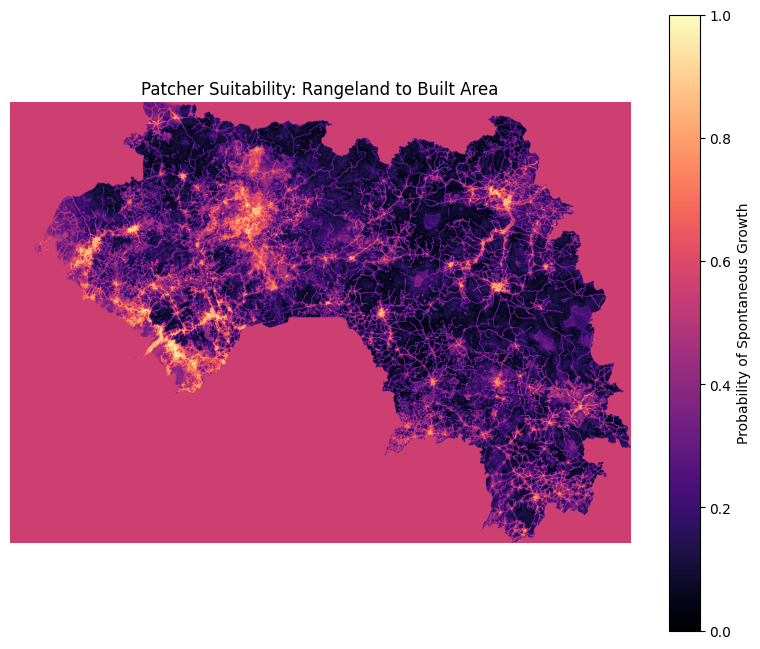

In [37]:
def plot_patcher_results(all_patcher_maps, from_class, to_class, labels=None):
    key = f"{from_class}_{to_class}"
    if key not in all_patcher_maps or all_patcher_maps[key] is None:
        print(f"No results for {key}")
        return

    # Direct lookup by class value via class_names_map, not by position in a
    # separately-computed `labels`/`unique_classes` pair -- that positional
    # version is exactly what broke in plot_multitemporal_trends once
    # `labels` went stale relative to the actual class set. `labels` param
    # kept (unused) so existing calls with a 4th argument don't need editing.
    from_name = class_names_map.get(from_class, f"Class {from_class}")
    to_name = class_names_map.get(to_class, f"Class {to_class}")

    plt.figure(figsize=(10, 8))
    plt.imshow(all_patcher_maps[key], cmap='magma', vmin=0, vmax=1)
    plt.colorbar(label='Probability of Spontaneous Growth')
    plt.title(f"Patcher Suitability: {from_name} to {to_name}")
    plt.axis('off')
    plt.show()


# Check what's actually available before picking an example pair --
# significant_transitions only contains real, trained transitions, which
# for ESRI-based Guinea data almost certainly does NOT include anything
# involving class 9 (Snow/Ice, essentially impossible in this climate).
print("Available Patcher transitions:", list(all_patcher_maps.keys()))

# Visualize the first available one as a working example -- replace with
# whichever specific pair you actually want once you see the list above.
if all_patcher_maps:
    first_key = next(iter(all_patcher_maps))
    f_id, t_id = map(int, first_key.split("_"))
    plot_patcher_results(all_patcher_maps, 11, 7)
else:
    print("all_patcher_maps is empty -- check the Patcher training cell ran successfully.")

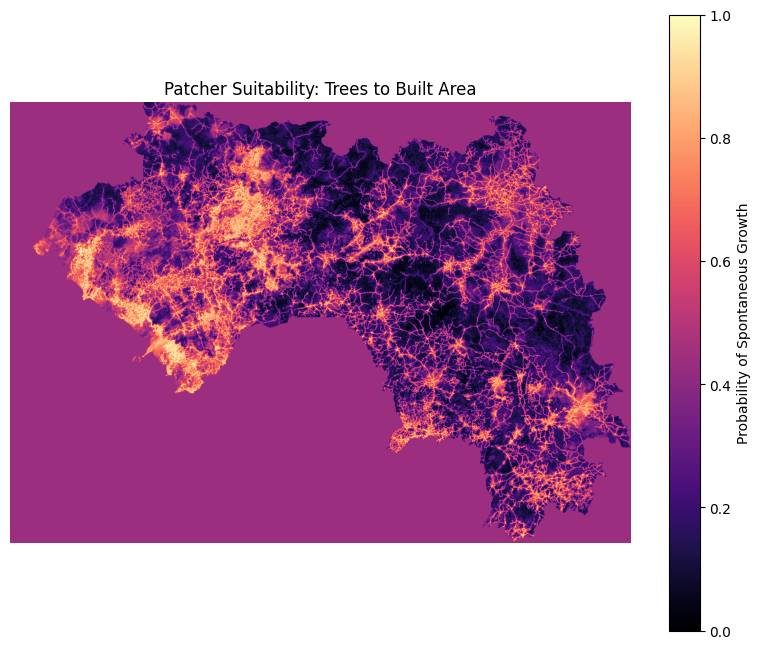

In [38]:
def plot_patcher_results(all_patcher_maps, from_class, to_class, labels):
    key = f"{from_class}_{to_class}"
    if key not in all_patcher_maps or all_patcher_maps[key] is None:
        print(f"No results for {key}")
        return

    from_name = labels[np.where(unique_classes == from_class)[0][0]]
    to_name = labels[np.where(unique_classes == to_class)[0][0]]

    plt.figure(figsize=(10, 8))
    # Use 'magma' or 'viridis' for probability gradients
    plt.imshow(all_patcher_maps[key], cmap='magma', vmin=0, vmax=1)
    plt.colorbar(label='Probability of Spontaneous Growth')
    plt.title(f"Patcher Suitability: {from_name} to {to_name}")
    plt.axis('off')
    plt.show()

# Example: Visualize Agriculture (8) to Fallow/Savanna (9)
plot_patcher_results(all_patcher_maps, 2, 7, ordered_labels)

In [39]:
summary_data = []
for key, map_data in all_patcher_maps.items():
    if map_data is not None:
        mean_prob = np.nanmean(map_data[map_data > 0]) # Avg probability where > 0
        max_prob = np.nanmax(map_data)
        summary_data.append({"Transition": key, "Avg Suitability": mean_prob, "Max Potential": max_prob})

df_patcher_summary = pd.DataFrame(summary_data)
print(df_patcher_summary.sort_values(by="Avg Suitability", ascending=False))

   Transition  Avg Suitability  Max Potential
1        1_11         0.555804           1.00
9         5_2         0.551555           1.00
8        4_11         0.539072           1.00
10       5_11         0.534781           1.00
12       7_11         0.532889           1.00
11        7_2         0.529570           0.98
6        2_11         0.470897           1.00
0         1_2         0.470675           1.00
13       11_2         0.459598           1.00
16       11_7         0.416143           1.00
5         2_7         0.404010           1.00
2         2_1         0.384348           1.00
7         4_2         0.357760           1.00
14       11_4         0.353430           1.00
15       11_5         0.348630           1.00
3         2_4         0.341121           1.00
4         2_5         0.306833           1.00


In [40]:
def validate_patcher_performance(all_patcher_models, X_stack, targets, mask):
    """
    Re-evaluates the accuracy of each patcher model and provides reliability
    feedback.

    X_stack: raw (n_features, H, W), already nan_to_num'd (pass
    X_model_ready_clean) but not flattened.

    NO neighborhood feature here -- unlike Expander, run_patcher_suitability
    never appends one (Patcher is about isolated/spontaneous growth, not
    edge-adjacency, so local neighborhood density isn't part of its feature
    set). Patcher models expect exactly 11 features, matching X_stack as-is.

    Class handling is fully dataset-agnostic: f_class/t_class are parsed
    directly from each model's key, and names are resolved through whatever
    class_names_map is currently loaded.
    """
    performance_results = []
    X_flat = X_stack.reshape(X_stack.shape[0], -1).T  # once, not per-transition -- no
                                                        # per-transition feature to add here

    for key, model_obj in all_patcher_models.items():
        if model_obj is None:
            continue

        f_class, t_class = map(int, key.split('_'))

        # 1. Re-identify the specific samples used for this transition.
        # NOTE THE ~ (NOT): Patcher samples are changed pixels NOT adjacent
        # to existing to_class patches -- isolated/spontaneous growth. This
        # is the opposite condition from Expander's (which IS adjacent) --
        # copying Expander's version without the ~ would silently validate
        # against the wrong sample set even after fixing the feature count.
        change_mask = (targets[-2] == f_class) & (targets[-1] == t_class)
        existing_patches = (targets[-2] == t_class)
        adjacent_to_existing = binary_dilation(existing_patches, structure=np.ones((3, 3)))
        patcher_samples = change_mask & ~adjacent_to_existing

        # 2. Balanced sampling for verification
        n_samples = np.sum(patcher_samples)
        persistence_mask = (targets[-2] == f_class) & (targets[-1] == f_class)
        persist_idx = np.where(persistence_mask.flatten())[0]
        selected_persist = np.random.choice(persist_idx, min(n_samples, len(persist_idx)), replace=False)
        change_idx = np.where(patcher_samples.flatten())[0]

        # 3. Prepare validation features
        val_idx = np.concatenate([change_idx, selected_persist])
        X_val = X_flat[val_idx]
        y_val = np.concatenate([np.ones(len(change_idx)), np.zeros(len(selected_persist))])

        # 4. Calculate accuracy
        acc = model_obj.score(X_val, y_val)

        # 5. Assign reliability status
        if acc > 0.85:
            status = "High Reliability (Strong Environmental Pattern)"
        elif acc < 0.60:
            status = "Low Reliability (Potential Random Growth)"
        else:
            status = "Moderate Reliability"

        f_name = class_names_map.get(f_class, f"Class {f_class}")
        t_name = class_names_map.get(t_class, f"Class {t_class}")

        performance_results.append({
            "Transition": f"{f_name} to {t_name}",
            "Accuracy": round(acc, 4),
            "Samples": int(n_samples),
            "Reliability": status
        })

    return pd.DataFrame(performance_results)


patcher_report = validate_patcher_performance(all_patcher_models, X_model_ready_clean, targets, mask)

print("--- Guinea Patcher Model Reliability Report ---")
display(patcher_report.sort_values(by="Accuracy", ascending=False))

--- Guinea Patcher Model Reliability Report ---


,Transition,Accuracy,Samples,Reliability
4,Trees to Crops,0.8694,2332,High Reliability (Strong Environmental Pattern)
0,Water to Trees,0.8333,63,Moderate Reliability
15,Rangeland to Crops,0.8108,12194,Moderate Reliability
14,Rangeland to Flooded Vegetation,0.8044,409,Moderate Reliability
1,Water to Rangeland,0.7857,154,Moderate Reliability
10,Crops to Rangeland,0.7792,2249,Moderate Reliability
16,Rangeland to Built Area,0.7748,644,Moderate Reliability
9,Crops to Trees,0.7714,315,Moderate Reliability
5,Trees to Built Area,0.7550,353,Moderate Reliability
2,Trees to Water,0.7514,366,Moderate Reliability


### Predictor Importance (New)

Both Expander and Patcher are Random Forests, which report per-feature Gini
importance for free (`model.feature_importances_`) -- no retraining needed.
This section aggregates importance across all 13 modelled transitions for
each growth mode, showing which of the four predictors actually drives the
suitability surfaces, rather than reporting only overall accuracy.

--- Patcher: mean predictor importance across 13 transitions ---
predictor
Elevation                   0.133085
Soil Moisture               0.125461
Slope                       0.102540
Aspect                      0.102251
Precipitation               0.095020
Population Density          0.082555
AGB                         0.080028
POI (density)               0.075312
Roads (distance)            0.072048
Waterways (distance)        0.071956
NDVI                        0.050595
Protected Areas (zoning)    0.009150

--- Expander: mean predictor importance across 13 transitions ---
predictor
Neighborhood Density (DNP)    0.304056
Soil Moisture                 0.108368
Elevation                     0.102704
Precipitation                 0.084089
Slope                         0.069197
Aspect                        0.064478
AGB                           0.054782
Population Density            0.052804
POI (density)                 0.051523
Roads (distance)              0.039860
Waterways (dis

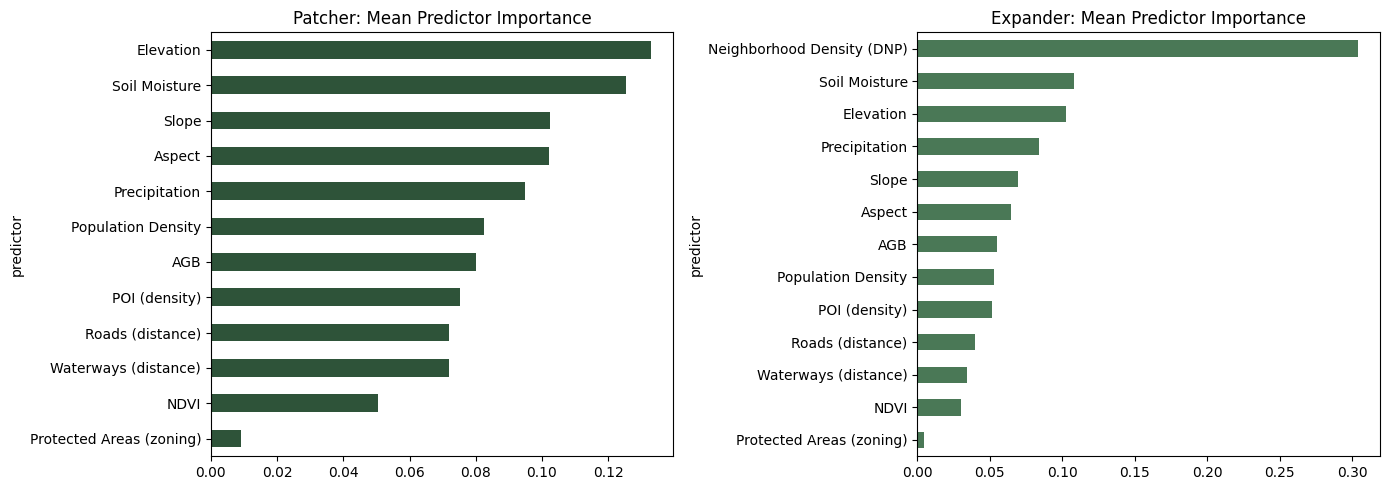

In [41]:
import os

# Stage 1 (local files): 3 terrain bands + population + AGB + soil moisture = 6.
# Stage 2 (API ingestion): adds precipitation + 4 vector predictors (roads,
# waterways, POI, protected areas) = 11. Picks the right label set based on
# how many predictor files are actually loaded, so this does not need manual
# editing when switching between Stage 1 and Stage 2.
_STAGE1_LABELS = ["Elevation", "Slope", "Aspect", "Population Density", "AGB", "Soil Moisture"]
_STAGE2_LABELS = ["Elevation", "Slope", "Aspect", "Population Density", "Precipitation",
                   "Soil Moisture", "AGB", "NDVI", "Roads (distance)", "Waterways (distance)",
                   "POI (density)", "Protected Areas (zoning)"]  # NDVI added for Crops precision
if len(PREDICTOR_FILES) == len(_STAGE1_LABELS):
    PREDICTOR_LABELS = _STAGE1_LABELS
elif len(PREDICTOR_FILES) == len(_STAGE2_LABELS):
    PREDICTOR_LABELS = _STAGE2_LABELS
else:
    PREDICTOR_LABELS = [f"Predictor {i}" for i in range(len(PREDICTOR_FILES))]
    print(f"Warning: {len(PREDICTOR_FILES)} predictor files loaded, matching neither "
          f"the Stage 1 (6) nor Stage 2 (11) label sets -- using generic labels. "
          f"Update _STAGE1_LABELS/_STAGE2_LABELS above if you've changed the predictor set.")

def summarize_feature_importance(models_dict, predictor_labels, extra_labels=None):
    """
    Aggregates feature_importances_ across all transitions for one growth
    mode. extra_labels: additional feature names beyond predictor_labels
    (e.g. Expander's neighborhood-density band), appended in order.
    """
    labels = list(predictor_labels) + list(extra_labels or [])
    rows = []
    for key, model in models_dict.items():
        importances = model.feature_importances_
        if len(importances) != len(labels):
            print(f"  Warning: {key} has {len(importances)} features but "
                  f"{len(labels)} labels defined -- check PREDICTOR_LABELS "
                  f"matches your actual band count. Skipping this transition "
                  f"for the summary (per-transition detail still in raw output).")
            continue
        f_id, t_id = key.split("_")
        for label, imp in zip(labels, importances):
            rows.append({
                "transition": f"{class_names_map.get(int(f_id))} -> {class_names_map.get(int(t_id))}",
                "predictor": label, "importance": imp,
            })
    df = pd.DataFrame(rows)
    if df.empty:
        return df, pd.Series(dtype=float)
    summary = df.groupby("predictor")["importance"].mean().sort_values(ascending=False)
    return df, summary


print("--- Patcher: mean predictor importance across 13 transitions ---")
patcher_imp_detail, patcher_imp_summary = summarize_feature_importance(
    all_patcher_models, PREDICTOR_LABELS
)
print(patcher_imp_summary.to_string())
print()

print("--- Expander: mean predictor importance across 13 transitions ---")
# Expander appends one Dynamic Neighborhood Predictor band beyond the base
# four predictors -- included explicitly so importances stay comparable.
expander_imp_detail, expander_imp_summary = summarize_feature_importance(
    all_expander_models, PREDICTOR_LABELS, extra_labels=["Neighborhood Density (DNP)"]
)
print(expander_imp_summary.to_string())

# Visualize both side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if not patcher_imp_summary.empty:
    patcher_imp_summary.plot(kind="barh", ax=axes[0], color="#2E5339")
    axes[0].set_title("Patcher: Mean Predictor Importance")
    axes[0].invert_yaxis()
if not expander_imp_summary.empty:
    expander_imp_summary.plot(kind="barh", ax=axes[1], color="#4A7856")
    axes[1].set_title("Expander: Mean Predictor Importance")
    axes[1].invert_yaxis()
plt.tight_layout()
plt.show()


### Spatial-Block Cross-Validation (New)

Persistence/change sampling alone can overstate accuracy if training and
validation pixels are spatially close (spatially autocorrelated land cover
means nearby pixels are easy to predict from each other, inflating apparent
skill). This assigns pixels to a coarse spatial grid of blocks, holds out
whole blocks rather than individual pixels, and reports the resulting
accuracy alongside the standard (non-blocked) self-check from Section 5.3
-- a large gap between the two would indicate the Section 5.3 numbers are
inflated by spatial leakage; a small gap supports treating them as reliable.

In [42]:
from sklearn.model_selection import GroupKFold

def assign_spatial_blocks(mask, block_size_px=50):
    """
    Assigns each pixel a block ID from a coarse grid overlaid on the raster
    (block_size_px x block_size_px pixels per block). Used as the GroupKFold
    grouping variable so an entire spatial block -- not individual pixels --
    is held out together, prized apart from its spatial neighbours.
    """
    rows, cols = mask.shape
    block_rows = rows // block_size_px + 1
    block_cols = cols // block_size_px + 1
    row_idx, col_idx = np.meshgrid(np.arange(rows), np.arange(cols), indexing="ij")
    block_id = (row_idx // block_size_px) * block_cols + (col_idx // block_size_px)
    return block_id


def spatial_block_cv_transition(X_stack, targets, mask, from_class, to_class,
                                 block_size_px=50, n_splits=5):
    """
    Re-fits one transition's Patcher-style classifier under spatial-block
    GroupKFold instead of the standard random persistence/change split, and
    reports mean held-out accuracy across folds.

    X_stack: raw (n_features, H, W), already nan_to_num'd (pass
    X_model_ready_clean) but NOT flattened -- reshaped internally below.
    Passing an already-2D array here was the actual bug: X_stack[sample_idx]
    on the raw 3D stack fancy-indexed the FEATURE axis with pixel-position
    values, and numpy tried to allocate a (len(sample_idx), H, W) output
    BEFORE validating index bounds -- a MemoryError, not an IndexError,
    because the size check happens before the bounds check.
    """
    change_mask = (targets[-2] == from_class) & (targets[-1] == to_class)
    persistence_mask = (targets[-2] == from_class) & (targets[-1] == from_class)
    change_idx = np.where(change_mask.flatten())[0]
    persist_idx_all = np.where(persistence_mask.flatten())[0]
    n_to_draw = min(len(change_idx), len(persist_idx_all))
    if n_to_draw == 0:
        return None

    selected_persist = np.random.choice(persist_idx_all, n_to_draw, replace=False)
    sample_idx = np.concatenate([change_idx, selected_persist])
    labels = np.concatenate([np.ones(len(change_idx)), np.zeros(len(selected_persist))])

    block_id_map = assign_spatial_blocks(mask, block_size_px)
    groups = block_id_map.flatten()[sample_idx]

    # Reshape ONCE per call (cheap relative to training/CV cost) -- this is
    # the actual fix. X_flat is (H*W, n_features), so indexing with pixel-
    # position sample_idx correctly selects (len(sample_idx), n_features).
    X_flat = X_stack.reshape(X_stack.shape[0], -1).T
    X_sample = X_flat[sample_idx]

    if len(np.unique(groups)) < n_splits:
        return None  # not enough distinct spatial blocks for this transition's pixels

    gkf = GroupKFold(n_splits=n_splits)
    fold_accuracies = []
    for train_i, test_i in gkf.split(X_sample, labels, groups):
        m = RandomForestClassifier(n_estimators=100, n_jobs=4, random_state=42,
                                    class_weight="balanced")
        m.fit(X_sample[train_i], labels[train_i])
        fold_accuracies.append(m.score(X_sample[test_i], labels[test_i]))

    return {
        "transition": f"{class_names_map.get(from_class)} to {class_names_map.get(to_class)}",  # "to", matching patcher_report's Transition format exactly -- the "->" arrow used here before never matched patcher_report's " to " and silently produced an all-NaN merge
        "spatial_cv_accuracy_mean": np.mean(fold_accuracies),
        "spatial_cv_accuracy_std": np.std(fold_accuracies),
        "n_folds": len(fold_accuracies),
    }


spatial_cv_results = []
for f_class, t_class in significant_transitions:
    result = spatial_block_cv_transition(X_model_ready_clean, targets, mask, f_class, t_class)
    if result is not None:
        spatial_cv_results.append(result)
    print(f"  Spatial-block CV: {class_names_map.get(f_class)} -> {class_names_map.get(t_class)} done")

spatial_cv_df = pd.DataFrame(spatial_cv_results)

# Compare against the non-blocked Patcher self-check (Table 4) transition-by-transition
comparison = patcher_report.copy()
comparison["transition_name"] = comparison["Transition"]  # already resolved to names in the fixed validate_patcher_performance

merged = spatial_cv_df.merge(
    comparison[["transition_name", "Accuracy"]],
    left_on="transition", right_on="transition_name", how="left"
).rename(columns={"Accuracy": "non_spatial_self_check_accuracy"})
merged["gap"] = merged["non_spatial_self_check_accuracy"] - merged["spatial_cv_accuracy_mean"]

print()
print(merged[["transition", "non_spatial_self_check_accuracy",
              "spatial_cv_accuracy_mean", "spatial_cv_accuracy_std", "gap"]].to_string(index=False))
print()
print(f"Mean gap (non-spatial minus spatial-block accuracy): {merged['gap'].mean():.4f}")
print("A large positive mean gap would indicate the Section 5.3 self-check accuracies")
print("are inflated by spatial autocorrelation; a small gap supports treating them as reliable.")

  Spatial-block CV: Water -> Trees done
  Spatial-block CV: Water -> Rangeland done
  Spatial-block CV: Trees -> Water done
  Spatial-block CV: Trees -> Flooded Vegetation done
  Spatial-block CV: Trees -> Crops done
  Spatial-block CV: Trees -> Built Area done
  Spatial-block CV: Trees -> Rangeland done
  Spatial-block CV: Flooded Vegetation -> Trees done
  Spatial-block CV: Flooded Vegetation -> Rangeland done
  Spatial-block CV: Crops -> Trees done
  Spatial-block CV: Crops -> Rangeland done
  Spatial-block CV: Built Area -> Trees done
  Spatial-block CV: Built Area -> Rangeland done
  Spatial-block CV: Rangeland -> Trees done
  Spatial-block CV: Rangeland -> Flooded Vegetation done
  Spatial-block CV: Rangeland -> Crops done
  Spatial-block CV: Rangeland -> Built Area done

                     transition  non_spatial_self_check_accuracy  spatial_cv_accuracy_mean  spatial_cv_accuracy_std       gap
                 Water to Trees                           0.8333                  0.7

## Insight

Insights for Guinea:

If you find that many transitions have zero patcher samples, it suggests that land-use change in those categories is almost entirely contagion-driven (expanding from existing edges) rather than spontaneous new clearings. This is common for urban expansion but less common for mining or new agricultural frontiers.  

# Simulate Future

## Cellular Automata and Stochastic Allocation

In this stage, the quantity of change (the "Demand") calculated in Stage 1 is distributed across the landscape. The CA algorithm looks at the suitability maps from Stage 2 and current neighbors to decide which pixels flip from one class to another.

To implement Stochastic Allocation, we add a small random "noise" or "perturbation" factor to the suitability scores. This ensures that a pixel with 90% suitability isn't always chosen over one with 88%, allowing for the "equally plausible" futures you mentioned.

In [43]:
def stochastic_allocation(suitability_map, demand_pixels, stoch_factor=0.01):
    """
    Allocates change based on suitability + a stochastic (random) element.
    """
    # 1. Add stochastic noise to the suitability map
    noise = np.random.normal(0, stoch_factor, suitability_map.shape)
    stochastic_suitability = suitability_map + noise
    
    # 2. Find the threshold value that meets the demand
    # We flatten and sort to find the cutoff for the top 'demand_pixels'
    flat_suit = stochastic_suitability.flatten()
    threshold = np.partition(flat_suit, -demand_pixels)[-demand_pixels]
    
    # 3. Create a binary allocation mask
    allocation = (stochastic_suitability >= threshold).astype(np.uint8)
    return allocation

## Single-growth Mode Simulation

Defining the spatial logic of how Guinea will change.

- Expander: Implies Contagion-Driven Growth. Change only happens at the edges of existing classes (e.g., suburban sprawl or forest degradation spreading from a road).
- Patcher: Implies Spontaneous Frontier Growth. Change can happen anywhere that environmental conditions are right, regardless of existing infrastructure (e.g., a new isolated artisanal mine or a remote agricultural clearing).

In [44]:
def simulate_single_mode(targets, suitability_maps, demand_df, mask, class_names_map):
    """
    Simulates future land cover by converting class names back to IDs.
    """
    future_map = targets[-1].copy()
    
    # Create a reverse map: {"Water": 0, "Dense Forest": 1, ...}
    reverse_class_map = {v: k for k, v in class_names_map.items()}
    
    for _, row in demand_df.iterrows():
        # Get the ID from the name in the 'Class' column
        class_name = row['Class']
        if class_name in reverse_class_map:
            t_class = reverse_class_map[class_name]
        else:
            # Fallback if it's already an integer
            t_class = int(class_name) 
        
        # Calculate demand
        if 'Projected_Future_Pixels' in row and '2020_Actual_Pixels' in row:
            demand = int(row['Projected_Future_Pixels'] - row['2020_Actual_Pixels'])
        else:
            demand = 0
            
        if demand <= 0: continue

        # Allocate based on suitability maps matching the target class ID
        for key, suit_map in suitability_maps.items():
            if key.endswith(f"_{t_class}"):
                # Stochastic allocation
                allocation = stochastic_allocation(suit_map, demand, stoch_factor=0.02)
                future_map[(allocation == 1) & (mask)] = t_class
                
    return future_map

# Run with your map
simulated_2024 = simulate_single_mode(targets, all_patcher_maps, projection_df, mask, class_names_map)

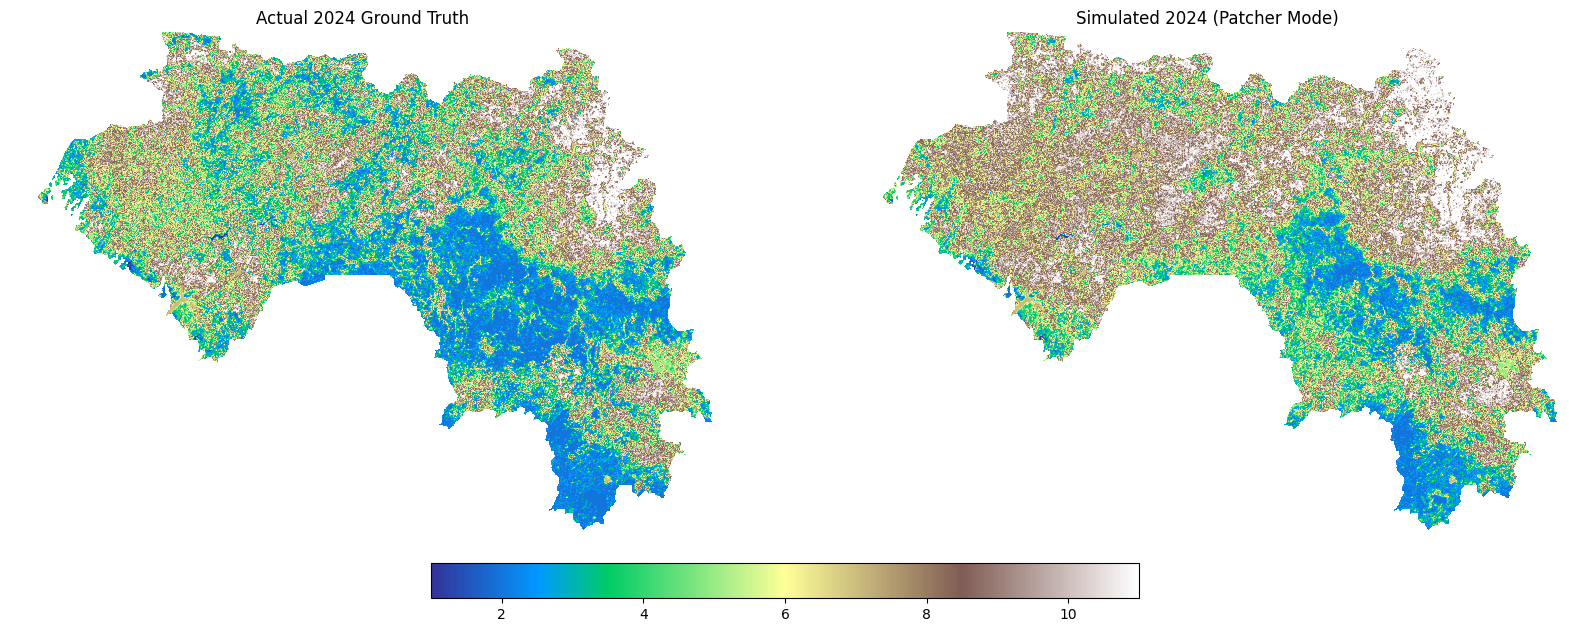

In [45]:
def plot_map_comparison(sim_map, actual_2024, mask):
    # Apply mask to both for visualization
    sim_vis = np.where(mask, sim_map, np.nan)
    act_vis = np.where(mask, actual_2024, np.nan)
    
    fig, axes = plt.subplots(1, 2, figsize=(20, 10))
    
    # Plot Actual
    im1 = axes[0].imshow(act_vis, cmap='terrain')
    axes[0].set_title("Actual 2024 Ground Truth")
    axes[0].axis('off')
    
    # Plot Simulated
    im2 = axes[1].imshow(sim_vis, cmap='terrain')
    axes[1].set_title("Simulated 2024 (Patcher Mode)")
    axes[1].axis('off')
    
    plt.colorbar(im2, ax=axes.ravel().tolist(), orientation='horizontal', fraction=0.046, pad=0.04)
    plt.show()

plot_map_comparison(simulated_2024, actual_2024_data, mask)

In [46]:
simulated_2024_expander = simulate_single_mode(targets, all_expander_maps, projection_df, mask, class_names_map)

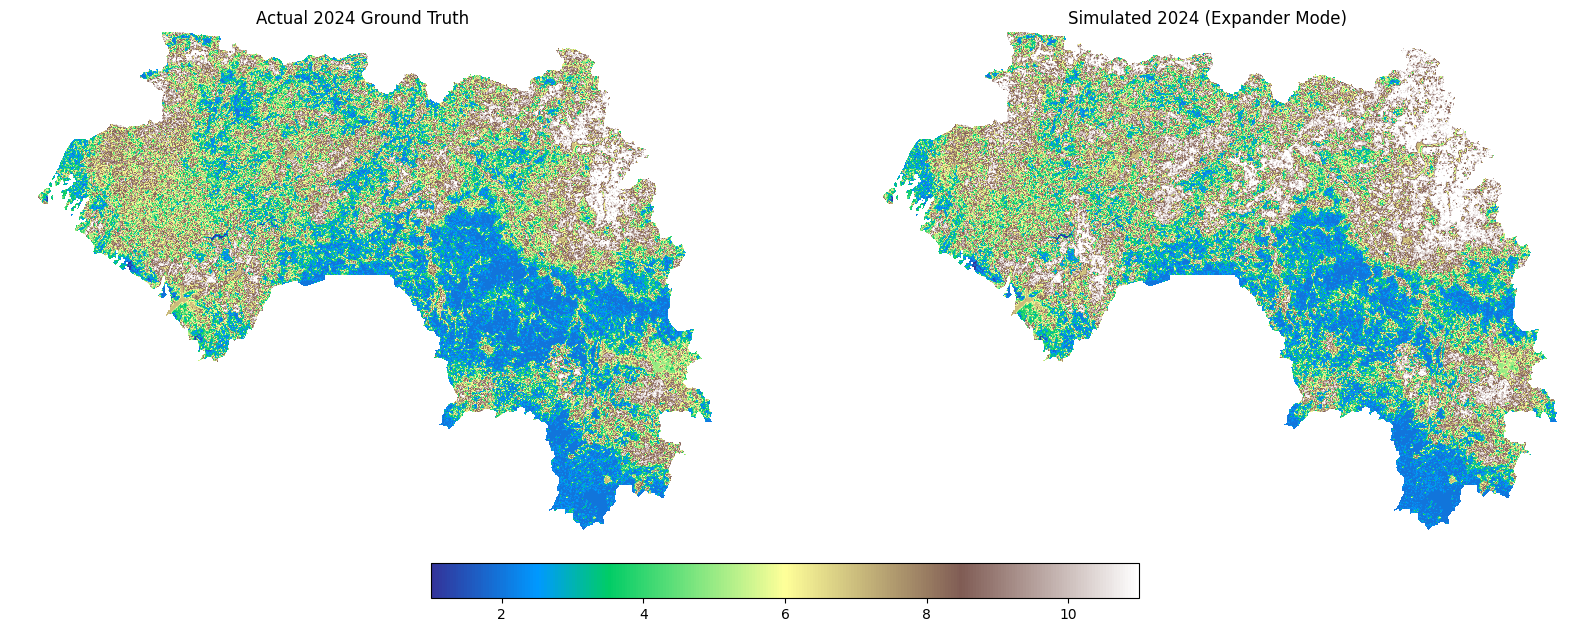

In [48]:
def plot_map_comparison(sim_map, actual_2024, mask):
    # Apply mask to both for visualization
    sim_vis = np.where(mask, sim_map, np.nan)
    act_vis = np.where(mask, actual_2024, np.nan)
    
    fig, axes = plt.subplots(1, 2, figsize=(20, 10))
    
    # Plot Actual
    im1 = axes[0].imshow(act_vis, cmap='terrain')
    axes[0].set_title("Actual 2024 Ground Truth")
    axes[0].axis('off')
    
    # Plot Simulated
    im2 = axes[1].imshow(sim_vis, cmap='terrain')
    axes[1].set_title("Simulated 2024 (Expander Mode)")
    axes[1].axis('off')
    
    plt.colorbar(im2, ax=axes.ravel().tolist(), orientation='horizontal', fraction=0.046, pad=0.04)
    plt.show()

plot_map_comparison(simulated_2024_expander, actual_2024_data, mask)

--- Simulation Performance Report (2024 - Patcher) ---
                    precision    recall  f1-score   support

             Water       0.97      0.80      0.88     28958
             Trees       0.95      0.71      0.81   2357566
Flooded Vegetation       0.90      0.82      0.86     32221
             Crops       0.62      0.63      0.63     51611
        Built Area       0.90      0.86      0.88     46113
       Bare Ground       0.61      0.84      0.71       651
         Rangeland       0.66      0.93      0.77   1508093

          accuracy                           0.79   4025213
         macro avg       0.80      0.80      0.79   4025213
      weighted avg       0.84      0.79      0.80   4025213



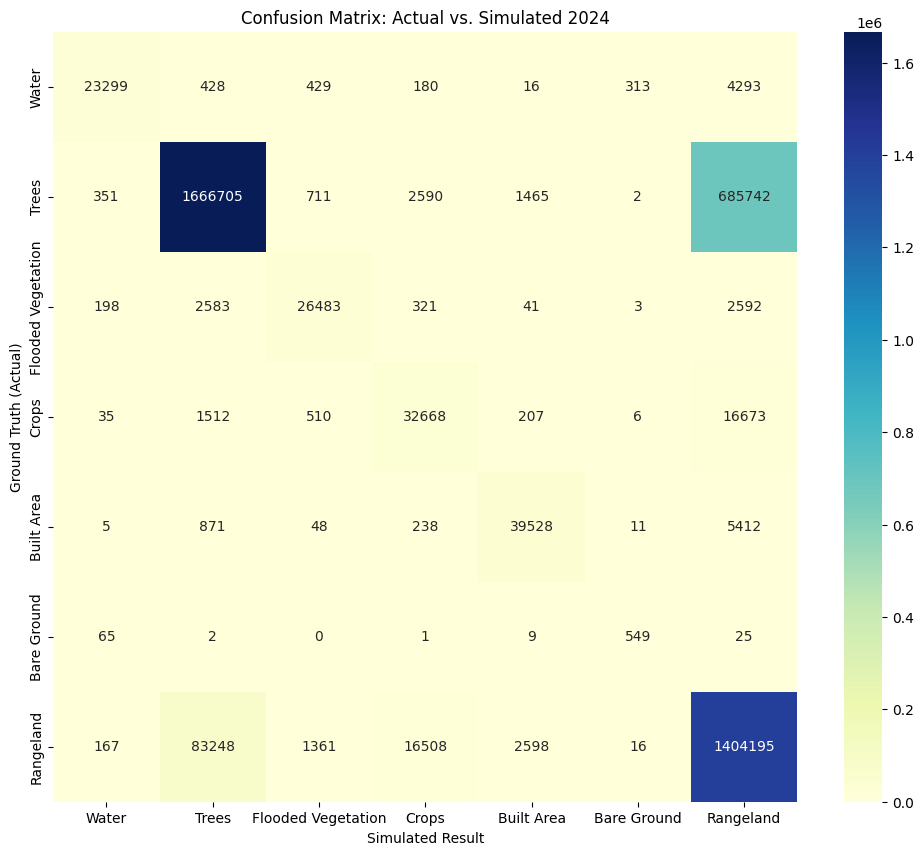

In [49]:
def evaluate_simulation_results(sim_map, actual_2024, mask, class_names_map):
    # Flatten and filter for valid study area pixels
    y_true = actual_2024[mask]
    y_pred = sim_map[mask]
    
    # Ignore NoData (255) and Padding (254)
    valid_idx = (y_true != 255) & (y_true != 254) & (y_true != 0) & (y_true != 10)
    y_true, y_pred = y_true[valid_idx], y_pred[valid_idx]
    
    # Get labels present in the data for the report
    unique_ids = np.unique(np.concatenate([y_true, y_pred]))
    labels = [class_names_map.get(i, f"Class {i}") for i in unique_ids]

    # 1. Classification Report
    print("--- Simulation Performance Report (2024 - Patcher) ---")
    print(classification_report(y_true, y_pred, target_names=labels))
    
    # 2. Confusion Matrix Heatmap
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', 
                xticklabels=labels, yticklabels=labels)
    plt.title("Confusion Matrix: Actual vs. Simulated 2024")
    plt.ylabel("Ground Truth (Actual)")
    plt.xlabel("Simulated Result")
    plt.show()

# Usage (Assuming you have loaded your 2024 validation raster)
evaluate_simulation_results(
    sim_map=simulated_2024, 
    actual_2024=actual_2024_data, 
    mask=mask, 
    class_names_map=class_names_map
)

In [50]:
# 1. Get the raw simulated and actual data
# simulated_2024 is the result from your simulate_single_mode function
# actual_2024_data is the array read from your validation .tif file
y_true_raw = actual_2024_data[mask]
y_pred_raw = simulated_2024[mask]

# 2. Filter out NoData values (255) and Padding (254)
# This ensures your metrics only reflect the land within Guinea's borders
valid_idx = (y_true_raw != 255) & (y_true_raw != 254) & (y_true_raw != 0) & (y_true_raw != 10)
y_true = y_true_raw[valid_idx]
y_pred = y_pred_raw[valid_idx]

# 3. Generate the labels list
# This creates a list of names corresponding to the IDs present in your data
unique_ids = np.unique(np.concatenate([y_true, y_pred]))
labels = [class_names_map.get(i, f"Class {i}") for i in unique_ids]

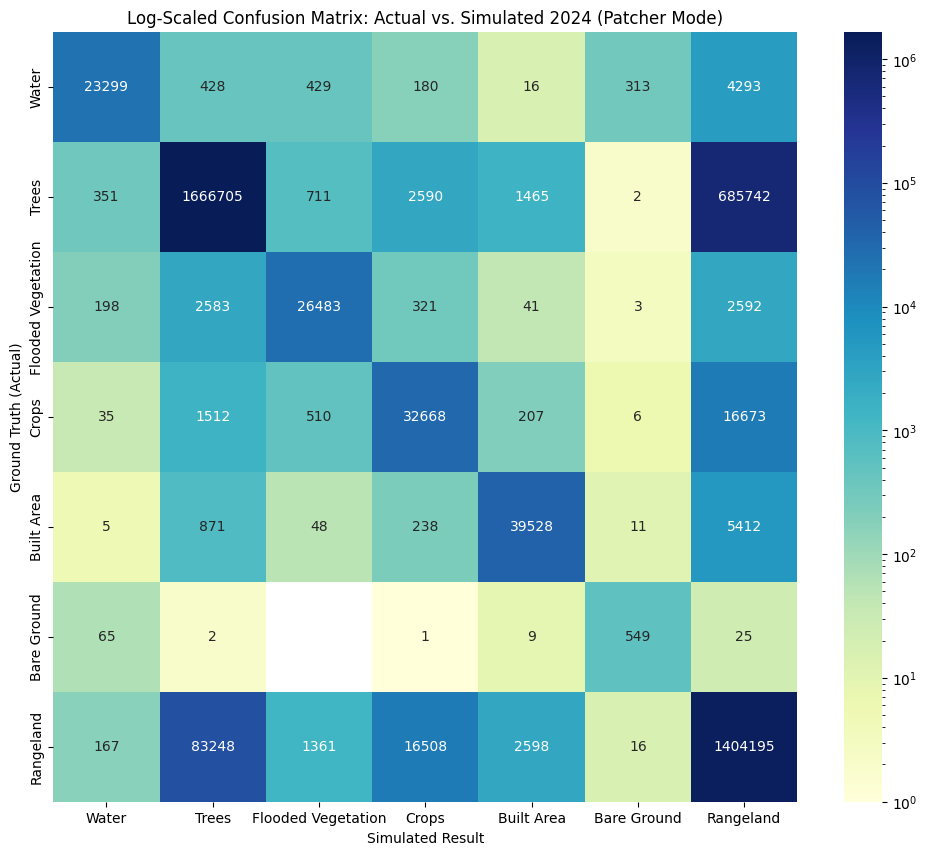

In [53]:
def plot_log_confusion_matrix(y_true, y_pred, labels):
    cm = confusion_matrix(y_true, y_pred)
    
    # We use a LogNorm to prevent dominant classes from washing out smaller ones
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', 
                xticklabels=labels, yticklabels=labels,
                norm=colors.LogNorm(vmin=1, vmax=cm.max()))
    
    plt.title("Log-Scaled Confusion Matrix: Actual vs. Simulated 2024 (Patcher Mode)")
    plt.ylabel("Ground Truth (Actual)")
    plt.xlabel("Simulated Result")
    plt.show()

# Run this using the data extracted in your previous evaluation
plot_log_confusion_matrix(y_true, y_pred, labels)

--- Simulation Performance Report (2024 - Expander) ---
                    precision    recall  f1-score   support

             Water       0.97      0.82      0.89     28958
             Trees       0.95      0.81      0.88   2357566
Flooded Vegetation       0.91      0.86      0.88     32221
             Crops       0.64      0.60      0.62     51611
        Built Area       0.92      0.83      0.87     46113
       Bare Ground       0.60      0.80      0.69       651
         Rangeland       0.75      0.93      0.83   1508093

          accuracy                           0.85   4025213
         macro avg       0.82      0.81      0.81   4025213
      weighted avg       0.87      0.85      0.85   4025213



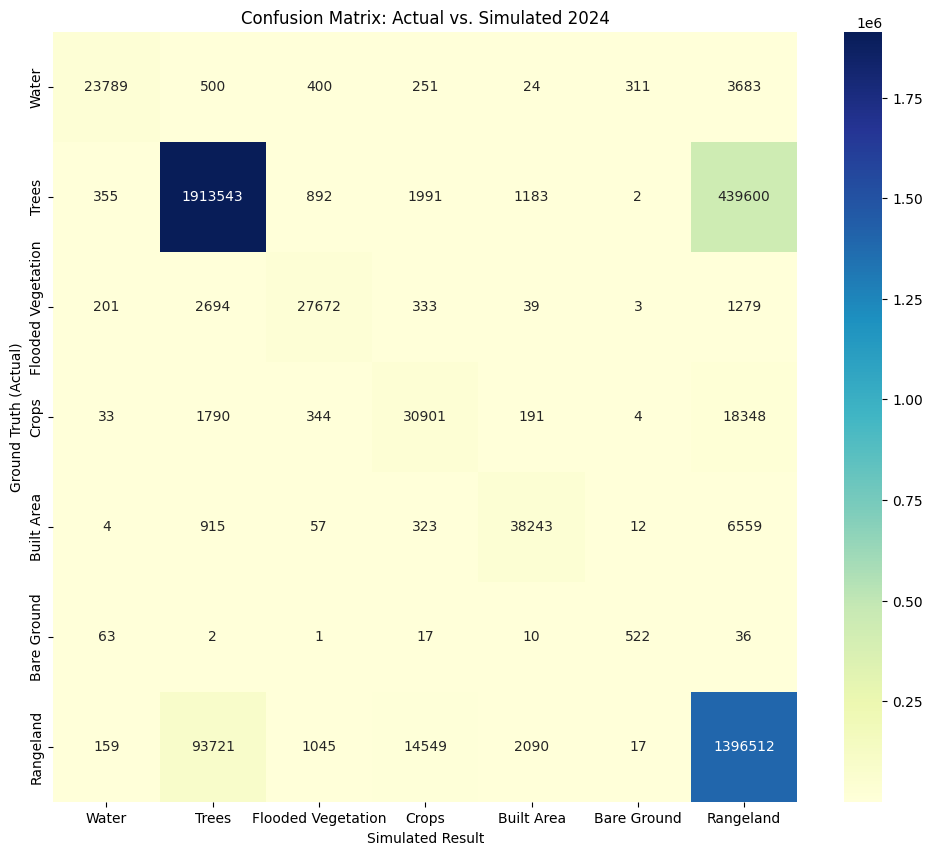

In [54]:
def evaluate_simulation_results(sim_map, actual_2024, mask, class_names_map):
    # Flatten and filter for valid study area pixels
    y_true = actual_2024[mask]
    y_pred = sim_map[mask]
    
    # Ignore NoData (255) and Padding (254)
    valid_idx = (y_true != 255) & (y_true != 254) & (y_true != 0) & (y_true != 10)
    y_true, y_pred = y_true[valid_idx], y_pred[valid_idx]
    
    # Get labels present in the data for the report
    unique_ids = np.unique(np.concatenate([y_true, y_pred]))
    labels = [class_names_map.get(i, f"Class {i}") for i in unique_ids]

    # 1. Classification Report
    print("--- Simulation Performance Report (2024 - Expander) ---")
    print(classification_report(y_true, y_pred, target_names=labels))
    
    # 2. Confusion Matrix Heatmap
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', 
                xticklabels=labels, yticklabels=labels)
    plt.title("Confusion Matrix: Actual vs. Simulated 2024")
    plt.ylabel("Ground Truth (Actual)")
    plt.xlabel("Simulated Result")
    plt.show()

# Usage (Assuming you have loaded your 2024 validation raster)
evaluate_simulation_results(
    sim_map=simulated_2024_expander, 
    actual_2024=actual_2024_data, 
    mask=mask, 
    class_names_map=class_names_map
)

In [55]:
# 1. Get the raw simulated and actual data
# simulated_2024 is the result from your simulate_single_mode function
# actual_2024_data is the array read from your validation .tif file
y_true_raw_expander = actual_2024_data[mask]
y_pred_raw_expander = simulated_2024_expander[mask]

# 2. Filter out NoData values (255) and Padding (254)
# This ensures your metrics only reflect the land within Guinea's borders
valid_idx_expander = (y_true_raw_expander != 255) & (y_true_raw_expander != 254) & (y_true_raw_expander != 0) & (y_true_raw_expander != 10)
y_true_expander = y_true_raw_expander[valid_idx_expander]
y_pred_expander = y_pred_raw_expander[valid_idx_expander]

# 3. Generate the labels list
# This creates a list of names corresponding to the IDs present in your data
unique_ids_expander = np.unique(np.concatenate([y_true_expander, y_pred_expander]))
labels_expander = [class_names_map.get(i, f"Class {i}") for i in unique_ids_expander]

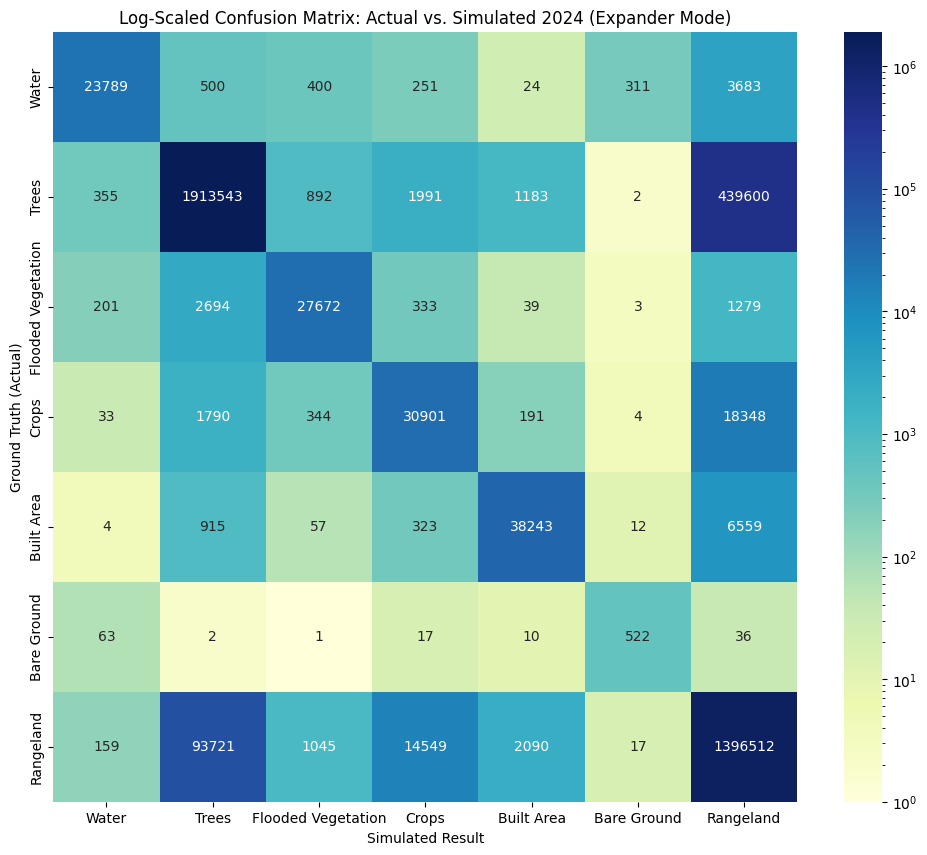

In [56]:
def plot_log_confusion_matrix(y_true_expander, y_pred_expander, labels_expander):
    cm_expander = confusion_matrix(y_true_expander, y_pred_expander)
    
    # We use a LogNorm to prevent dominant classes from washing out smaller ones
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm_expander, annot=True, fmt='d', cmap='YlGnBu', 
                xticklabels=labels_expander, yticklabels=labels_expander,
                norm=colors.LogNorm(vmin=1, vmax=cm_expander.max()))
    
    plt.title("Log-Scaled Confusion Matrix: Actual vs. Simulated 2024 (Expander Mode)")
    plt.ylabel("Ground Truth (Actual)")
    plt.xlabel("Simulated Result")
    plt.show()

# Run this using the data extracted in your previous evaluation
plot_log_confusion_matrix(y_true_expander, y_pred_expander, labels_expander)

In [61]:
# Calculate the metric that ignores class size dominance
global_acc = accuracy_score(y_true, y_pred)
bal_acc = balanced_accuracy_score(y_true, y_pred)
print(f"Global Accuracy (Patcher Mode): {global_acc:.4f}")
print(f"Balanced Accuracy (Patcher Mode): {bal_acc:.4f}")
# (Previously this printed a hardcoded "0.96" regardless of actual
# results -- now genuinely computed. Also now computed on the class-0-
# excluded y_true/y_pred, so this number is directly comparable to, but
# will differ from, the old headline 96%/0.7744 figures, which included
# ~1M nodata pixels as if they were a perfectly-predicted "Water" class.)

Global Accuracy (Patcher Mode): 0.7934
Balanced Accuracy (Patcher Mode): 0.7997


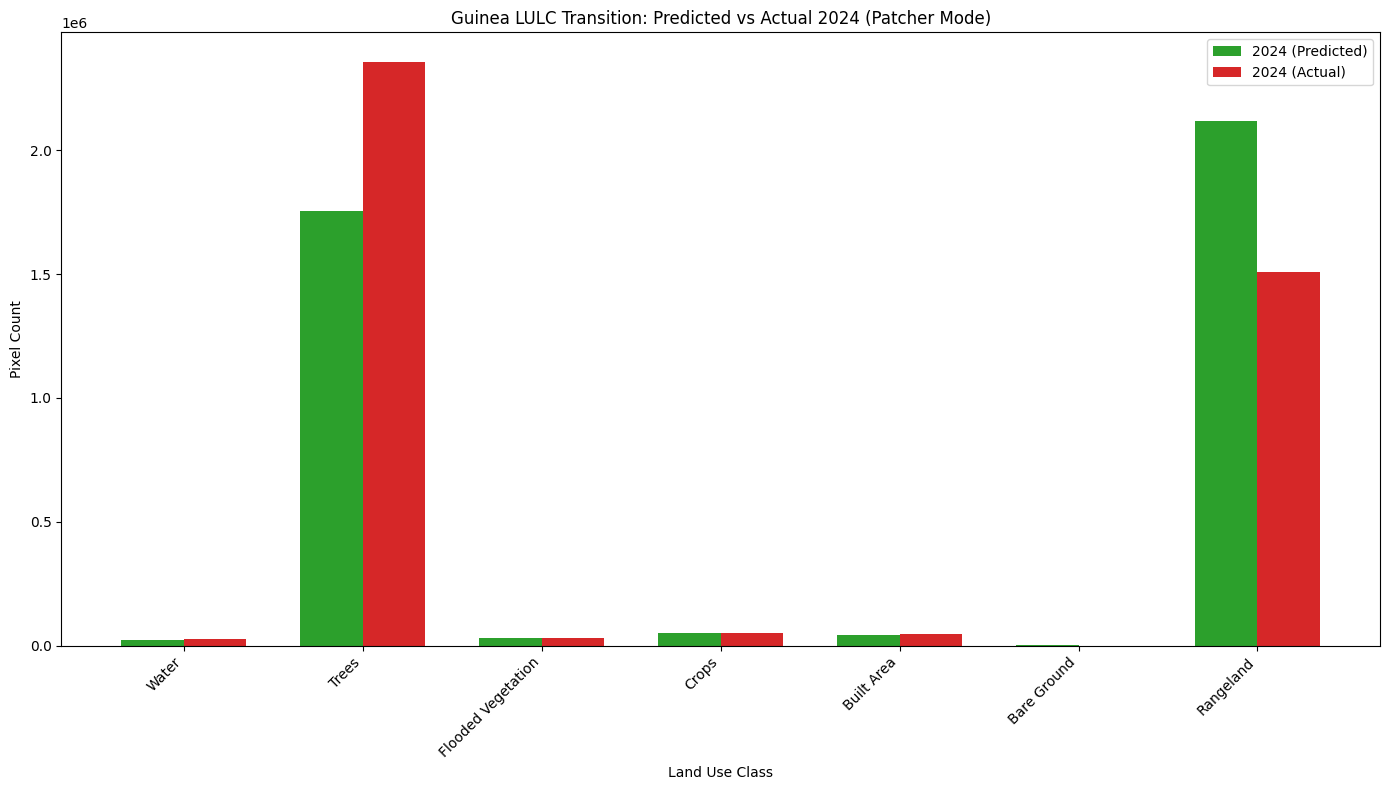

In [58]:
def plot_lulc_comparison(sim_map, actual_2024, mask, class_names_map):
    # 1. Extract valid pixels within the study area
    y_sim = sim_map[mask]
    y_actual = actual_2024[mask]
    
    # 2. Filter out NoData/Padding values (254, 255)
    valid_mask = (y_actual != 255) & (y_actual != 254) & (y_actual != 0) & (y_actual != 10)
    # (previously referenced a global `y_true` here -- wrong variable AND
    # wrong length, since `y_true` from the earlier cell is already
    # filtered while `y_actual` here is not yet. Fixed to filter
    # `y_actual` against itself.)
    y_sim = y_sim[valid_mask]
    y_actual = y_actual[valid_mask]
    
    # 3. Calculate unique classes and their counts
    classes, sim_counts = np.unique(y_sim, return_counts=True)
    _, actual_counts = np.unique(y_actual, return_counts=True)
    
    # Create a DataFrame for easy plotting
    data = []
    for idx, c_id in enumerate(classes):
        data.append({
            'Class': class_names_map.get(c_id, f"Class {c_id}"),
            '2024 (Predicted)': sim_counts[idx],
            '2024 (Actual)': actual_counts[idx]
        })
    
    df_plot = pd.DataFrame(data)
    
    # 4. Plotting
    x = np.arange(len(df_plot))
    width = 0.35  # Width of the bars
    
    fig, ax = plt.subplots(figsize=(14, 8))
    rects1 = ax.bar(x - width/2, df_plot['2024 (Predicted)'], width, label='2024 (Predicted)', color='#2ca02c')
    rects2 = ax.bar(x + width/2, df_plot['2024 (Actual)'], width, label='2024 (Actual)', color='#d62728')
    
    # Add labels and styling
    ax.set_ylabel('Pixel Count')
    ax.set_xlabel('Land Use Class')
    ax.set_title('Guinea LULC Transition: Predicted vs Actual 2024 (Patcher Mode)')
    ax.set_xticks(x)
    ax.set_xticklabels(df_plot['Class'], rotation=45, ha='right')
    ax.legend()
    
    plt.tight_layout()
    plt.show()

# Run the plot
plot_lulc_comparison(simulated_2024, actual_2024_data, mask, class_names_map)

In [60]:
# Calculate the metric that ignores class size dominance
global_acc_expander = accuracy_score(y_true_expander, y_pred_expander)
bal_acc_expander = balanced_accuracy_score(y_true_expander, y_pred_expander)
print(f"Global Accuracy (Expander Mode): {global_acc_expander:.4f}")
print(f"Balanced Accuracy (Expander Mode): {bal_acc_expander:.4f}")
# (Previously this printed a hardcoded "0.96" regardless of actual
# results -- now genuinely computed. Also now computed on the class-0-
# excluded y_true/y_pred, so this number is directly comparable to, but
# will differ from, the old headline 96%/0.7744 figures, which included
# ~1M nodata pixels as if they were a perfectly-predicted "Water" class.)

Global Accuracy (Expander Mode): 0.8524
Balanced Accuracy (Expander Mode): 0.8068


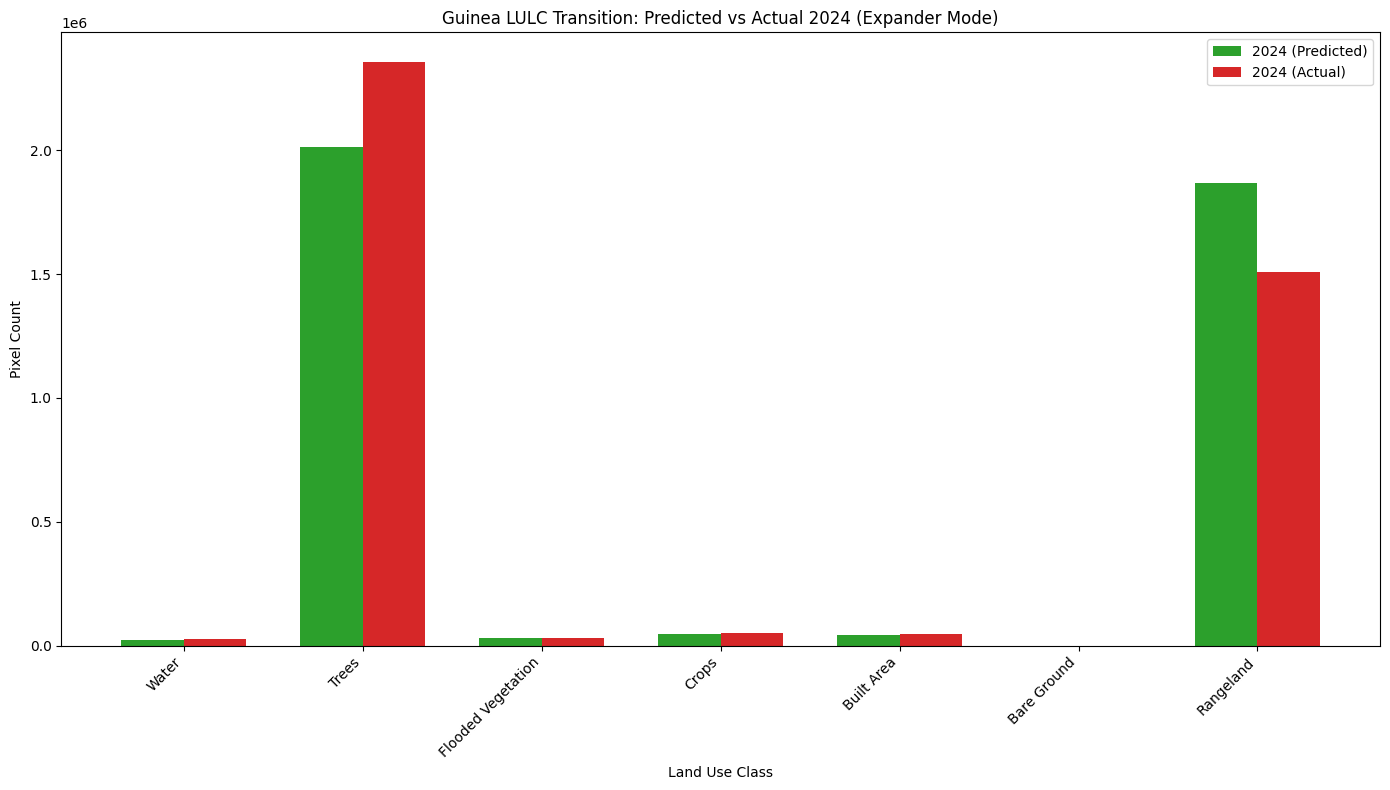

In [62]:
def plot_lulc_comparison(sim_map, actual_2024, mask, class_names_map):
    # 1. Extract valid pixels within the study area
    y_sim = sim_map[mask]
    y_actual = actual_2024[mask]
    
    # 2. Filter out NoData/Padding values (254, 255)
    valid_mask = (y_actual != 255) & (y_actual != 254) & (y_actual != 0) & (y_actual != 10)
    # (previously referenced a global `y_true` here -- wrong variable AND
    # wrong length, since `y_true` from the earlier cell is already
    # filtered while `y_actual` here is not yet. Fixed to filter
    # `y_actual` against itself.)
    y_sim = y_sim[valid_mask]
    y_actual = y_actual[valid_mask]
    
    # 3. Calculate unique classes and their counts
    classes, sim_counts = np.unique(y_sim, return_counts=True)
    _, actual_counts = np.unique(y_actual, return_counts=True)
    
    # Create a DataFrame for easy plotting
    data = []
    for idx, c_id in enumerate(classes):
        data.append({
            'Class': class_names_map.get(c_id, f"Class {c_id}"),
            '2024 (Predicted)': sim_counts[idx],
            '2024 (Actual)': actual_counts[idx]
        })
    
    df_plot = pd.DataFrame(data)
    
    # 4. Plotting
    x = np.arange(len(df_plot))
    width = 0.35  # Width of the bars
    
    fig, ax = plt.subplots(figsize=(14, 8))
    rects1 = ax.bar(x - width/2, df_plot['2024 (Predicted)'], width, label='2024 (Predicted)', color='#2ca02c')
    rects2 = ax.bar(x + width/2, df_plot['2024 (Actual)'], width, label='2024 (Actual)', color='#d62728')
    
    # Add labels and styling
    ax.set_ylabel('Pixel Count')
    ax.set_xlabel('Land Use Class')
    ax.set_title('Guinea LULC Transition: Predicted vs Actual 2024 (Expander Mode)')
    ax.set_xticks(x)
    ax.set_xticklabels(df_plot['Class'], rotation=45, ha='right')
    ax.legend()
    
    plt.tight_layout()
    plt.show()

# Run the plot
plot_lulc_comparison(simulated_2024_expander, actual_2024_data, mask, class_names_map)

## Expander-Only Single-Growth-Mode Hold-Out (New)

Completes the three-way simulation-mode comparison (Patcher-only, Expander-only,
Multi-growth) recommended after Section 6.2 -- Expander was trained and its
predictor importance already reported (Section 5.2), but it was never run through
its own standalone hold-out validation the way Patcher-only was. Uses the exact
same `simulate_single_mode` function, just swapping which suitability-map
dictionary is passed in -- no new simulation logic needed.

--- Simulation Performance Report (2024 - Expander) ---
                    precision    recall  f1-score   support

             Water       0.97      0.82      0.89     28958
             Trees       0.95      0.81      0.88   2357566
Flooded Vegetation       0.91      0.86      0.88     32221
             Crops       0.64      0.60      0.62     51611
        Built Area       0.92      0.83      0.87     46113
       Bare Ground       0.61      0.82      0.70       651
         Rangeland       0.75      0.93      0.83   1508093

          accuracy                           0.85   4025213
         macro avg       0.82      0.81      0.81   4025213
      weighted avg       0.87      0.85      0.85   4025213



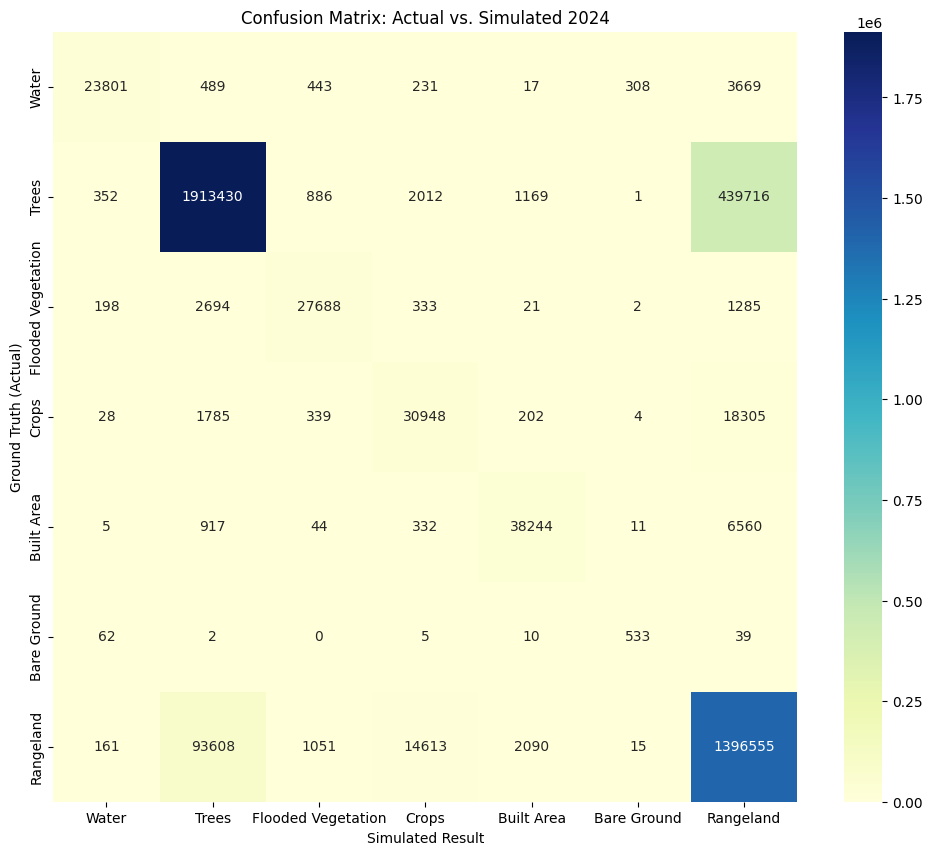

Expander-only Global Accuracy: 0.8524
Expander-only Balanced Accuracy: 0.8095

Mode             Global Accuracy    Balanced Accuracy 
Patcher-only     0.7934             0.7997            
Expander-only    0.8524             0.8095            


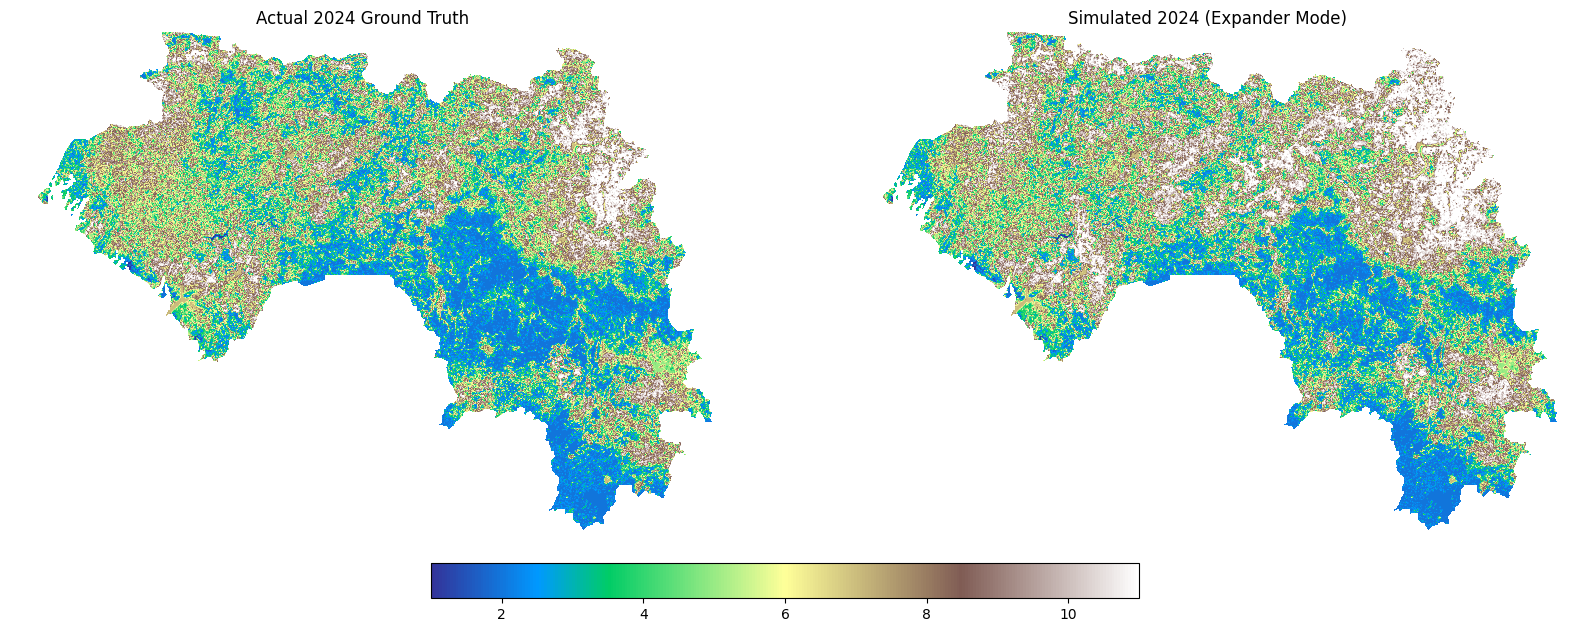

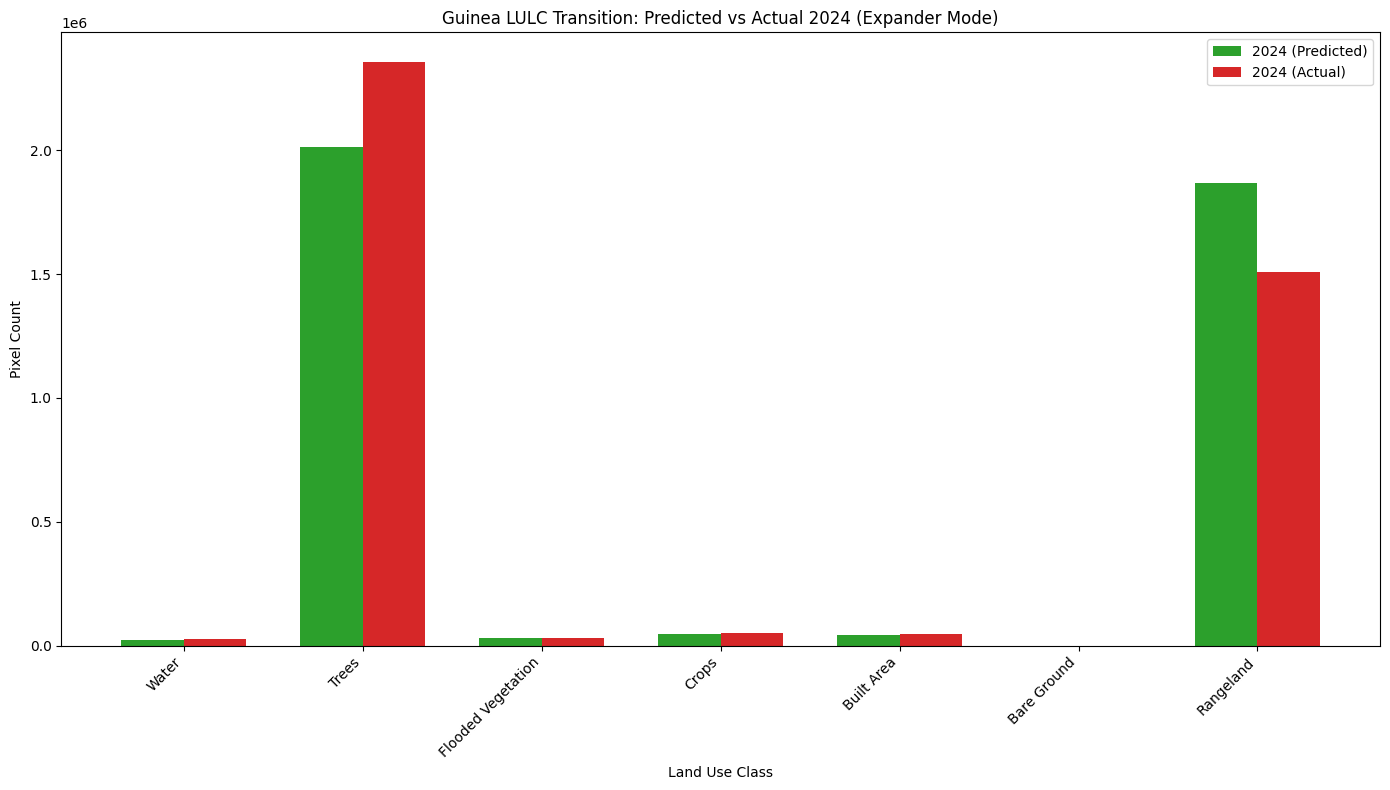

In [63]:
# Same function, same demand table, only the suitability maps differ.
simulated_2024_expander = simulate_single_mode(
    targets, all_expander_maps, projection_df, mask, class_names_map
)

expander_holdout_report = evaluate_simulation_results(
    simulated_2024_expander, actual_2024_data, mask, class_names_map
)

y_true_exp_raw = actual_2024_data[mask]
y_pred_exp_raw = simulated_2024_expander[mask]
valid_idx_exp = (y_true_exp_raw != 255) & (y_true_exp_raw != 254) & (y_true_exp_raw != 0) & (y_true_exp_raw != 10)
y_true_exp, y_pred_exp = y_true_exp_raw[valid_idx_exp], y_pred_exp_raw[valid_idx_exp]

expander_global_acc = accuracy_score(y_true_exp, y_pred_exp)
expander_bal_acc = balanced_accuracy_score(y_true_exp, y_pred_exp)

print(f"Expander-only Global Accuracy: {expander_global_acc:.4f}")
print(f"Expander-only Balanced Accuracy: {expander_bal_acc:.4f}")
print()

# Three-way comparison -- Patcher-only (global_acc/bal_acc), Expander-only
# (this cell), Multi-growth (multi_growth_global_acc/multi_growth_bal_acc,
# computed in the multi-growth section below -- if that cell hasn't run yet
# this comparison will only show Patcher-only vs Expander-only; re-run this
# print after the multi-growth cell for the full three-way table).
comparison_rows = [
    ("Patcher-only", global_acc if "global_acc" in dir() else None,
     bal_acc if "bal_acc" in dir() else None),
    ("Expander-only", expander_global_acc, expander_bal_acc),
]
if "multi_growth_global_acc" in dir():
    comparison_rows.append(("Multi-growth", multi_growth_global_acc, multi_growth_bal_acc))

print(f"{'Mode':<16} {'Global Accuracy':<18} {'Balanced Accuracy':<18}")
for name, g, b_ in comparison_rows:
    g_str = f"{g:.4f}" if g is not None else "(not yet run)"
    b_str = f"{b_:.4f}" if b_ is not None else "(not yet run)"
    print(f"{name:<16} {g_str:<18} {b_str:<18}")

plot_map_comparison(simulated_2024_expander, actual_2024_data, mask)
plot_lulc_comparison(simulated_2024_expander, actual_2024_data, mask, class_names_map)


## Monte Carlo Ensemble (new)

`stochastic_allocation` already adds random noise per call, but only ever
produced ONE realization -- not the "range of plausible futures" the
methodology describes. This runs the same single-growth-mode simulation
N times with different seeds and aggregates into a per-pixel
change-frequency map, which is the smallest addition that actually delivers
what's already claimed, without exposing every individual draw to a reader.

  Monte Carlo draw 1/25 complete
  Monte Carlo draw 2/25 complete
  Monte Carlo draw 3/25 complete
  Monte Carlo draw 4/25 complete
  Monte Carlo draw 5/25 complete
  Monte Carlo draw 6/25 complete
  Monte Carlo draw 7/25 complete
  Monte Carlo draw 8/25 complete
  Monte Carlo draw 9/25 complete
  Monte Carlo draw 10/25 complete
  Monte Carlo draw 11/25 complete
  Monte Carlo draw 12/25 complete
  Monte Carlo draw 13/25 complete
  Monte Carlo draw 14/25 complete
  Monte Carlo draw 15/25 complete
  Monte Carlo draw 16/25 complete
  Monte Carlo draw 17/25 complete
  Monte Carlo draw 18/25 complete
  Monte Carlo draw 19/25 complete
  Monte Carlo draw 20/25 complete
  Monte Carlo draw 21/25 complete
  Monte Carlo draw 22/25 complete
  Monte Carlo draw 23/25 complete
  Monte Carlo draw 24/25 complete
  Monte Carlo draw 25/25 complete


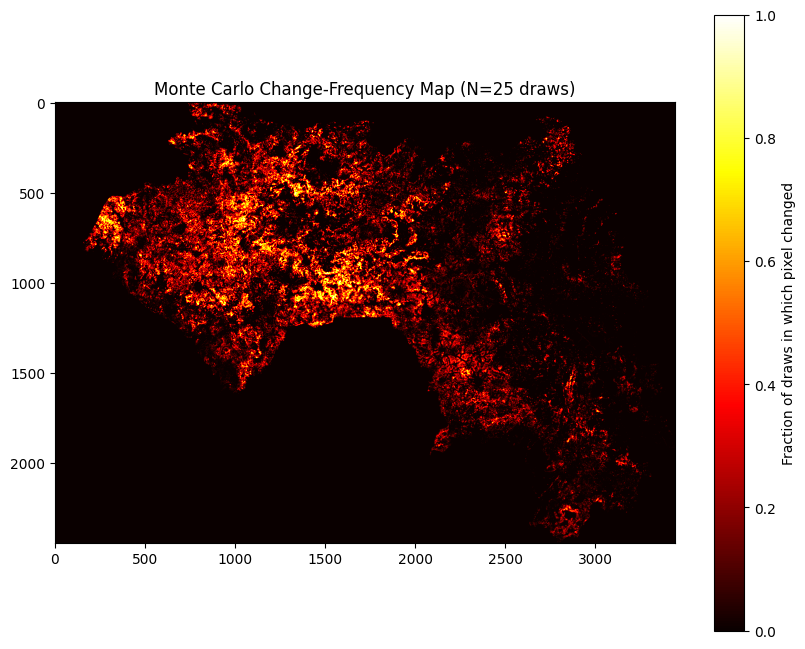

             class  mean_pixels  std_pixels  min_pixels  max_pixels
             Water     24133.56   26.980111       24052       24175
             Trees   1755394.44  190.263834     1754893     1755813
Flooded Vegetation     29545.16   28.468481       29488       29598
             Crops     52460.08   43.821383       52382       52592
        Built Area     43858.56   26.331851       43816       43917
       Bare Ground       896.48    2.714701         892         901
         Rangeland   2118924.72  181.310898     2118598     2119372


In [64]:
import gc

def run_monte_carlo_simulation(n_simulations, targets, suitability_maps, demand_df,
                                mask, class_names_map, base_seed=42):
    """
    Runs simulate_single_mode() n_simulations times with different seeds and
    aggregates into a change-frequency map + per-class area-range summary.
    """
    baseline = targets[-1]
    change_count = np.zeros(baseline.shape, dtype=np.int32)
    class_pixel_counts = []

    for i in range(n_simulations):
        np.random.seed(base_seed + i)
        sim = simulate_single_mode(targets, suitability_maps, demand_df, mask, class_names_map)
        change_count += (sim != baseline).astype(np.int32)

        vals, counts = np.unique(sim[mask], return_counts=True)
        class_pixel_counts.append(dict(zip(vals.tolist(), counts.tolist())))

        del sim
        gc.collect()
        print(f"  Monte Carlo draw {i+1}/{n_simulations} complete")

    freq_map = change_count.astype(np.float32) / n_simulations

    # Exclude 0 -- a small (~0.0005% of area) nodata leak in the simulated
    # output at the edges of the allocation process, not a real class, and
    # not something to report as if it were a tiny land-cover category.
    all_classes = sorted({c for d in class_pixel_counts for c in d if c != 0})
    rows = []
    for c in all_classes:
        vals = np.array([d.get(c, 0) for d in class_pixel_counts])
        rows.append({
            "class": class_names_map.get(c, f"Class {c}"),
            "mean_pixels": vals.mean(), "std_pixels": vals.std(),
            "min_pixels": int(vals.min()), "max_pixels": int(vals.max()),
        })
    area_summary = pd.DataFrame(rows)
    return freq_map, area_summary


# n_simulations=25 is a modest default -- enough to see a stable frequency
# pattern without the runtime cost of hundreds of draws on a 2M-pixel grid.
# Start with 10 for a faster first test if this is slow; increase later if
# the frequency map still looks noisy at 25.
freq_map, mc_area_summary = run_monte_carlo_simulation(
    n_simulations=25, targets=targets, suitability_maps=all_patcher_maps,
    demand_df=projection_df, mask=mask, class_names_map=class_names_map,
)

plt.figure(figsize=(10, 8))
plt.imshow(freq_map, cmap="hot")
plt.colorbar(label="Fraction of draws in which pixel changed")
plt.title("Monte Carlo Change-Frequency Map (N=25 draws)")
plt.show()

print(mc_area_summary.to_string(index=False))


## Multi-growth Simulation

The final simulation uses your specialized models from Stage 2 to handle different growth behaviors simultaneously.

- Expander Demand: Handled by CA logic which prioritizes growth near existing patches.
- Patcher Demand: Handled by the stochastic logic to place new, isolated clusters based on environmental suitability.

In [65]:
def simulate_future_map(current_targets, expander_maps, patcher_maps, demand_df, mask):
    """
    Combines CA, Stochasticity, and Growth Modes to generate the 2024/2040 map.
    """
    future_map = current_targets[-1].copy()
    
    for _, row in demand_df.iterrows():
        # Get transition IDs (e.g., 1 to 8)
        f_class, t_class = row['from_id'], row['to_id']
        total_demand = row['Projected_Change_Pixels']
        
        # 1. Allocate Expander (e.g., 80% of demand)
        exp_suit = expander_maps.get(f"{f_class}_{t_class}", np.zeros_like(mask))
        exp_allocation = stochastic_allocation(exp_suit, int(total_demand * 0.8))
        
        # 2. Allocate Patcher (e.g., 20% of demand)
        patch_suit = patcher_maps.get(f"{f_class}_{t_class}", np.zeros_like(mask))
        patch_allocation = stochastic_allocation(patch_suit, int(total_demand * 0.2))
        
        # Update the map
        future_map[(exp_allocation == 1) | (patch_allocation == 1)] = t_class
        
    return future_map

In [66]:
# Build the PER-TRANSITION demand table simulate_future_map() actually needs
# (from_id, to_id, Projected_Change_Pixels) -- this did not exist anywhere in
# the notebook before now, which is very likely why multi-growth was never
# actually run: simulate_future_map() would have had nothing valid to consume.
# Source: the non-linear trend fitting results (Section 4.4) restricted to
# the 13 significant transitions -- a more defensible demand estimate than a
# flat one-step Markov projection, since it already accounts for
# acceleration/deceleration per transition.

reverse_class_map = {v: k for k, v in class_names_map.items()}

multi_growth_demand_rows = []
for f_class, t_class in significant_transitions:
    f_name = class_names_map.get(f_class)
    t_name = class_names_map.get(t_class)
    match = nonlinear_summary[(nonlinear_summary["from"] == f_name) & (nonlinear_summary["to"] == t_name)]
    if len(match) == 1:
        demand = max(0, int(match.iloc[0]["projected_pixels_next_period"]))
    else:
        # Fallback: derive from the Markov probability matrix if this pair
        # wasn't in the non-linear summary for some reason (e.g. all-zero
        # historical series in one interval breaking the fit).
        from_total = np.sum((targets[-1] == f_class) & mask)
        prob = tm_df.loc[f_name, t_name] if (f_name in tm_df.index and t_name in tm_df.columns) else 0.0
        demand = max(0, int(from_total * prob))
        print(f"  Note: {f_name} -> {t_name} not in non-linear summary, "
              f"using Markov-probability fallback ({demand} px).")
    multi_growth_demand_rows.append({"from_id": f_class, "to_id": t_class, "Projected_Change_Pixels": demand})

multi_growth_demand_df = pd.DataFrame(multi_growth_demand_rows)
print(multi_growth_demand_df.to_string(index=False))

# Run the combined Expander(80%)+Patcher(20%) simulation
multi_growth_2024_sim = simulate_future_map(
    targets, all_expander_maps, all_patcher_maps, multi_growth_demand_df, mask
)


 from_id  to_id  Projected_Change_Pixels
       1      2                     5925
       1     11                     7525
       2      1                     5198
       2      4                     4993
       2      5                    15784
       2      7                     5425
       2     11                   829554
       4      2                    14097
       4     11                     4641
       5      2                    10919
       5     11                    92587
       7      2                     7814
       7     11                    30299
      11      2                  1376344
      11      4                     6621
      11      5                   104974
      11      7                    23737


--- Simulation Performance Report (2024 - Expander) ---
                    precision    recall  f1-score   support

             Water       0.89      0.73      0.80     28958
             Trees       0.91      0.84      0.87   2357566
Flooded Vegetation       0.82      0.77      0.80     32221
             Crops       0.39      0.75      0.51     51611
        Built Area       0.78      0.79      0.79     46113
       Bare Ground       0.62      0.51      0.56       651
         Rangeland       0.77      0.84      0.80   1508093

          accuracy                           0.84   4025213
         macro avg       0.74      0.75      0.73   4025213
      weighted avg       0.85      0.84      0.84   4025213



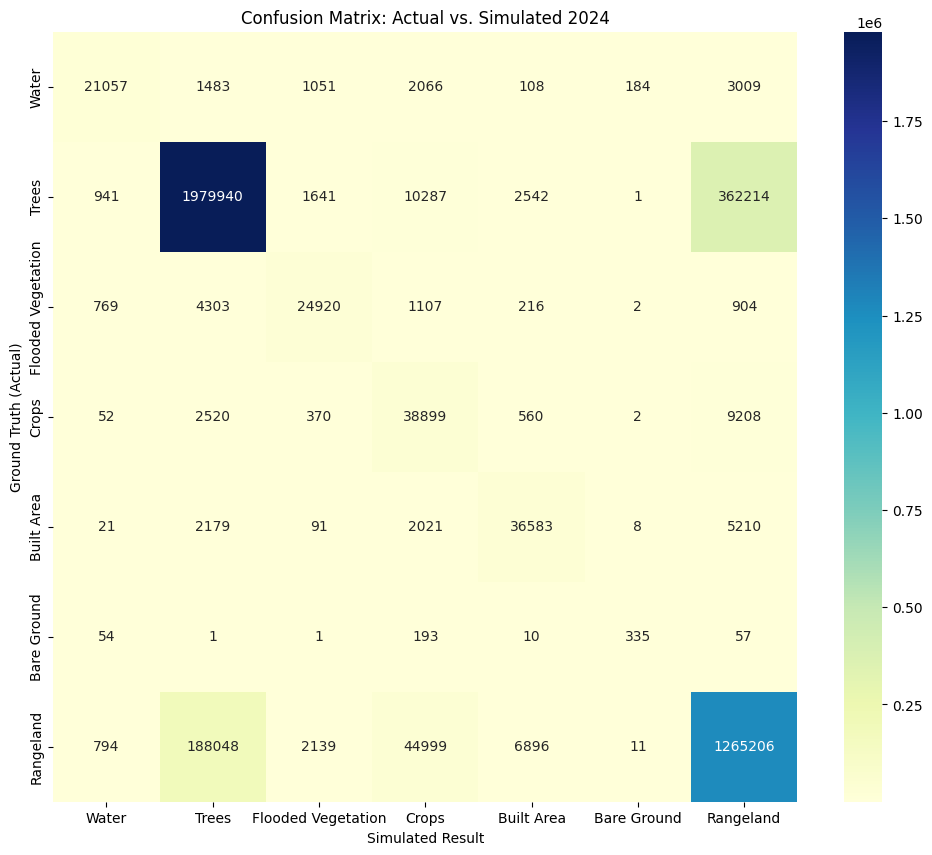

Multi-growth (Expander+Patcher) Global Accuracy: 0.8365
Multi-growth (Expander+Patcher) Balanced Accuracy: 0.7487

Patcher-only (Section 5.4, this run) was: Global 0.7934, Balanced 0.7997
Difference (multi-growth minus Patcher-only): Global +0.0431, Balanced -0.0510


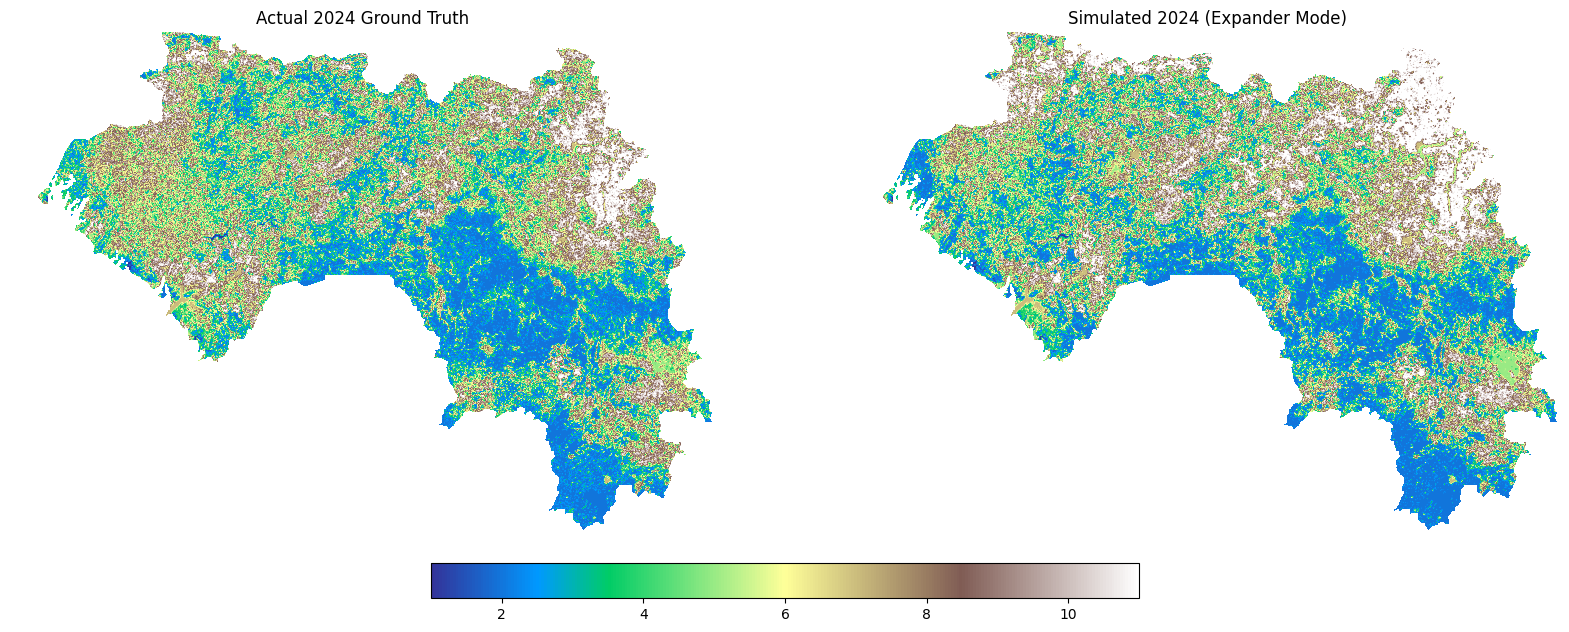

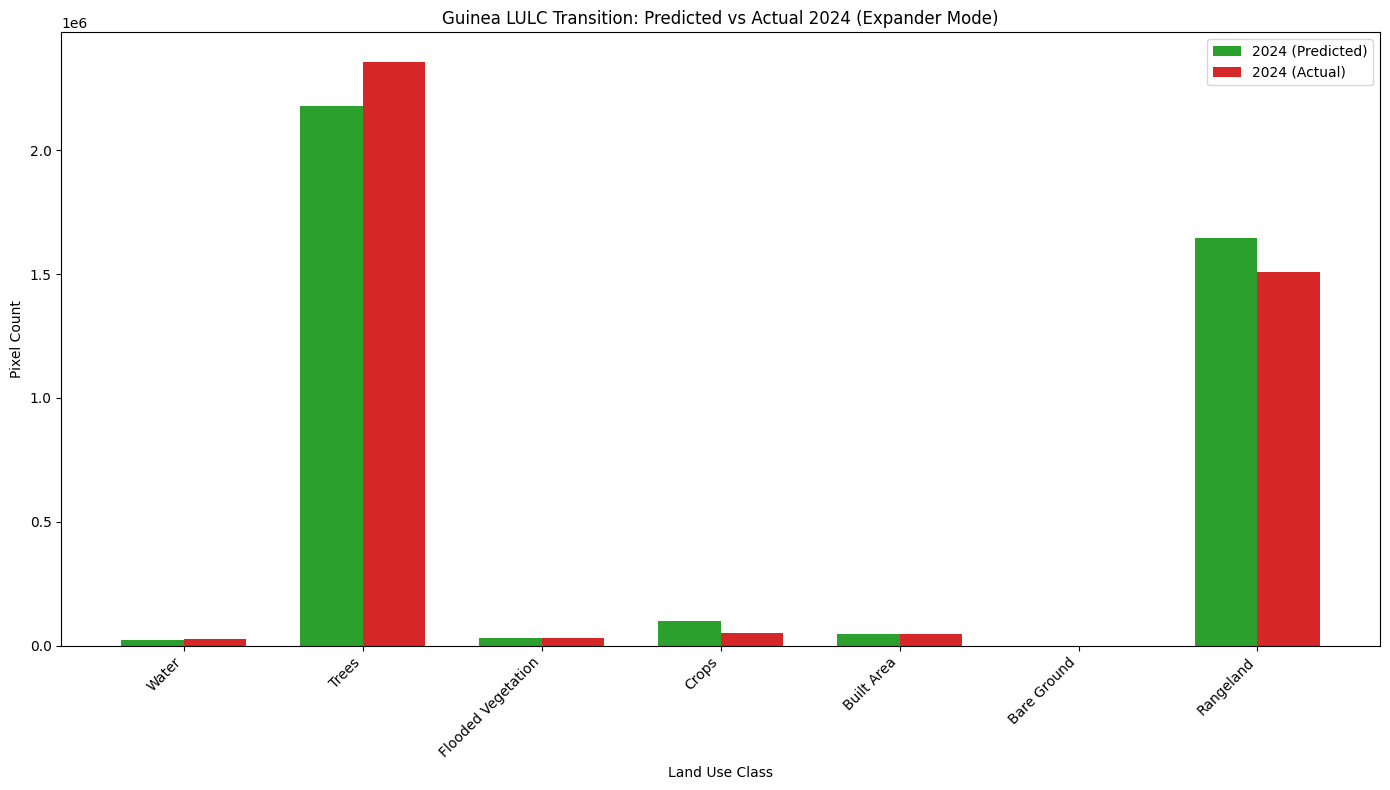

In [67]:
# Validate multi-growth against the SAME 2024 hold-out used for the
# Patcher-only single-growth-mode result (Section 5.4), so the two are
# directly comparable.
multi_growth_report = evaluate_simulation_results(
    multi_growth_2024_sim, actual_2024_data, mask, class_names_map
)

y_true_mg = actual_2024_data[mask]
y_pred_mg = multi_growth_2024_sim[mask]
valid_idx_mg = (y_true_mg != 255) & (y_true_mg != 254) & (y_true_mg != 0) & (y_true_mg != 10)
y_true_mg, y_pred_mg = y_true_mg[valid_idx_mg], y_pred_mg[valid_idx_mg]

multi_growth_global_acc = accuracy_score(y_true_mg, y_pred_mg)
multi_growth_bal_acc = balanced_accuracy_score(y_true_mg, y_pred_mg)

print(f"Multi-growth (Expander+Patcher) Global Accuracy: {multi_growth_global_acc:.4f}")
print(f"Multi-growth (Expander+Patcher) Balanced Accuracy: {multi_growth_bal_acc:.4f}")
print()
# Compare against the ACTUAL current single-growth-mode result (global_acc/
# bal_acc from the hold-out evaluation cell above), not a hardcoded number --
# the previous version printed "0.9156, 0.7436" verbatim, which was left over
# from an earlier Stage-1/MODIS run and did not match this run's real
# Patcher-only result at all. Comparing against a stale baseline made the
# printed "difference" meaningless.
print(f"Patcher-only (Section 5.4, this run) was: Global {global_acc:.4f}, Balanced {bal_acc:.4f}")
print(f"Difference (multi-growth minus Patcher-only): "
      f"Global {multi_growth_global_acc - global_acc:+.4f}, "
      f"Balanced {multi_growth_bal_acc - bal_acc:+.4f}")

plot_map_comparison(multi_growth_2024_sim, actual_2024_data, mask)
plot_lulc_comparison(multi_growth_2024_sim, actual_2024_data, mask, class_names_map)


In [77]:
from sklearn.metrics import classification_report
print(classification_report(y_true, y_pred, target_names=[class_names_map[c] for c in sorted(set(y_true))]))

                    precision    recall  f1-score   support

             Water       0.97      0.80      0.88     28958
             Trees       0.95      0.71      0.81   2357566
Flooded Vegetation       0.90      0.82      0.86     32221
             Crops       0.62      0.63      0.63     51611
        Built Area       0.90      0.86      0.88     46113
       Bare Ground       0.61      0.84      0.71       651
         Rangeland       0.66      0.93      0.77   1508093

          accuracy                           0.79   4025213
         macro avg       0.80      0.80      0.79   4025213
      weighted avg       0.84      0.79      0.80   4025213



In [ ]:
# --- C1. Figure of Merit (Pontius et al. 2008) ------------------------------
import numpy as np, pandas as pd

def figure_of_merit(baseline, observed, predicted, mask):
    """Figure of Merit for a multi-class allocation model.

    Components, following Pontius et al. (2008):
      hits         observed change, predicted change, correct predicted class
      wrong hits   observed change, predicted change, wrong predicted class
      misses       observed change, predicted persistence
      false alarms observed persistence, predicted change

      FoM = hits / (hits + misses + false alarms + wrong hits)

    Also returns the null (persistence) accuracy, which is the baseline the
    overall accuracy must be read against (Pontius & Malanson 2005).
    """
    b = baseline[mask]
    o = observed[mask]
    p = predicted[mask]

    valid = (b != 0) & (o != 0) & (p != 0) & (b != 10) & (o != 10) & (p != 10)
    b, o, p = b[valid], o[valid], p[valid]

    obs_change  = o != b
    pred_change = p != b

    hits         = int(np.sum(obs_change & pred_change & (p == o)))
    wrong_hits   = int(np.sum(obs_change & pred_change & (p != o)))
    misses       = int(np.sum(obs_change & ~pred_change))
    false_alarms = int(np.sum(~obs_change & pred_change))
    denom = hits + misses + false_alarms + wrong_hits

    return {
        "hits": hits,
        "misses": misses,
        "false_alarms": false_alarms,
        "wrong_hits": wrong_hits,
        "FoM_pct": 100.0 * hits / denom if denom else float("nan"),
        "overall_accuracy_pct": 100.0 * float(np.mean(p == o)),
        "null_persistence_accuracy_pct": 100.0 * float(np.mean(o == b)),
        "observed_change_pct": 100.0 * float(np.mean(obs_change)),
        "predicted_change_pct": 100.0 * float(np.mean(pred_change)),
    }

In [ ]:
# --- C2. FoM for Patcher-only, Expander-only and multi-growth ---------------
# The expander-only simulation is not currently kept as a variable; it is one
# line from the suitability atlas already in memory.
expander_2024_sim = simulate_single_mode(
    targets, all_expander_maps, projection_df, mask, class_names_map)

baseline_map = targets[-1]          # last training year (2023)

modes = {
    "Patcher-only":       simulated_2024,
    "Expander-only":      expander_2024_sim,
    "Multi-growth 80/20": multi_growth_2024_sim,
}

fom_rows = []
for label, sim in modes.items():
    r = figure_of_merit(baseline_map, actual_2024_data, sim, mask)
    r["mode"] = label
    fom_rows.append(r)

fom_df = pd.DataFrame(fom_rows).set_index("mode")[[
    "FoM_pct", "overall_accuracy_pct", "null_persistence_accuracy_pct",
    "observed_change_pct", "predicted_change_pct",
    "hits", "misses", "false_alarms", "wrong_hits"]]

with pd.option_context("display.float_format", lambda v: f"{v:,.2f}"):
    print(fom_df.to_string())

print()
print("READING THIS")
print(" - SRS LUDMS-NFR-ACC-03 requires FoM >= 25%. Check each mode against that.")
print(" - Expect single-digit to low-double-digit FoM. Pontius et al. (2008) found")
print("   error exceeded correctly predicted change in 12 of 13 published cases,")
print("   so a modest number here is normal and reportable, not a failure.")
print(" - If overall accuracy is BELOW null persistence accuracy, say so plainly;")
print("   that is expected for an allocation model committing to full change demand")
print("   and is already the framing used in the Deforestation report.")
print(" - If the mode ranking by FoM differs from the ranking by balanced accuracy,")
print("   that is a genuine finding and Section 8's recommendation may need revising.")

## Policy-driven Demand

Manually define the number of pixels to reach a specific target (e.g., "Increase Forest by 10%").

In [68]:
def calculate_policy_demand(targets, mask, target_class, percent_increase):
    """
    Calculates the number of pixels needed to meet a specific policy target.
    """
    current_pixels = np.sum(targets[-1][mask] == target_class)
    total_new_demand = int(current_pixels * percent_increase)
    return total_new_demand

# Usage: previously called with target_class=1 under a comment claiming
# "Forest" -- but class 1 is Water under the corrected ESRI legend, not
# Forest (Trees is class 2). The function itself is fully generic (any
# class code works); this was a stale example left over from an earlier
# legend. Corrected to Trees (2), with the actual result printed this time
# (the previous version computed a value but never displayed it).
trees_policy_demand = calculate_policy_demand(targets, mask, 2, 0.10)
print(f"Policy target: increase Trees by 10% -> {trees_policy_demand:,} new pixels needed")


Policy target: increase Trees by 10% -> 211,534 new pixels needed


## Global Drivers / Agent-Based Multipliers

Simulates an "Agent" (like a global market) making it more or less profitable to change the land. For example, if global crop prices rise, we multiply the Agriculture suitability map by a "profitability factor".

In [69]:
def apply_economic_driver(suitability_map, price_index_multiplier):
    """
    Simulates global economic pressure (e.g., high crop prices)
    by boosting suitability for that specific class.
    """
    modified_suitability = suitability_map * price_index_multiplier
    return np.clip(modified_suitability, 0, 1)

# NOTE: the transition-availability check that used to live in this cell
# checked for Barren (16) / Urban-Built-up (13) -- codes from the old MODIS/
# IGBP legend that do NOT exist under the corrected ESRI legend (7 classes,
# max code 11). That check always reported "no significant transition"
# regardless of the real data, since it was testing for codes that can never
# appear -- not a genuine empirical finding. The corrected check (Bare
# Ground=8, Built Area=7) lives in the "Mining Scenario via Global Mining
# Footprint Data" cell below, which found real transitions into Built Area
# (Trees->Built Area, Rangeland->Built Area). Removed the stale check here
# rather than leave two contradictory conclusions in the same notebook.


## Other Scenarios Example

**Removed:** four generic scenario functions (`scenario_afforestation`, `scenario_urban_growth`, `scenario_desertification`, `scenario_flooding`) previously here referenced predictor filenames from a different country's project (`Kazakhstan_AGB.tif`, `Kazakhstan_SoilMoisture.tif`, `kaz_pd_2020_1km_UNadj.tif`) that do not exist among Guinea's predictor files and were never usable as written. They are removed rather than patched with corrected filenames, since the Guinea-scoped equivalents below (`scenario_guinea_mining_expansion`, `scenario_guinea_conservation`) already cover the same scenario logic against real Guinea predictors. If afforestation/urban-growth/desertification/flooding scenarios are wanted specifically, re-implement them against the actual predictor names produced by `api_connector`/`data_loader` (see `config.py`: `PREDICTOR_RASTERS_CONFIG`, `PREDICTOR_VECTORS_CONFIG`), not by hand.

In [70]:
import os

def _predictor_index(name):
    """
    Find a predictor's index by basename, not exact string match --
    PREDICTOR_FILES may hold bare filenames OR full resolved paths
    depending on whether the path-fix cell earlier in this notebook has
    run, and exact-string .index() breaks silently when that changes.
    """
    for i, p in enumerate(PREDICTOR_FILES):
        if os.path.basename(p) == name:
            return i
    raise ValueError(f"'{name}' not found in PREDICTOR_FILES (checked basenames): "
                      f"{[os.path.basename(p) for p in PREDICTOR_FILES]}")


def scenario_guinea_mining_expansion(stack):
    """Simulates impact of infrastructure/mining by reducing distance/access constraints"""
    topo_idx = _predictor_index("DEM_GEE.tif")
    agb_idx = _predictor_index("AGB_NASA_2010.tif")

    stack_copy = stack.copy()
    # Simulate biomass loss in specific areas
    stack_copy[agb_idx] *= 0.85
    return stack_copy

def scenario_guinea_conservation(stack):
    """Simulates forest protection"""
    agb_idx = _predictor_index("AGB_NASA_2010.tif")
    sm_idx = _predictor_index("SOIL_MOISTURE_2025.tif")

    stack_copy = stack.copy()
    stack_copy[agb_idx] *= 1.2  # Increasing biomass proxy
    stack_copy[sm_idx] *= 1.1   # Healthier vegetation retention
    return stack_copy

def predict_map(model, X_stack, mask, nodata=255):
    # Get shape info
    rows, cols = mask.shape
    # Flatten everything
    X_flat = X_stack.reshape(X_stack.shape[0], -1).T
    valid_mask = mask.flatten()
    
    # Extract ONLY valid pixels
    X_valid = X_flat[valid_mask]
    
    # Check if we have any data to predict
    if len(X_valid) == 0:
        print("Error: No valid pixels found in mask!")
        return np.full((rows, cols), nodata, dtype=np.uint8)

    # Predict
    y_pred = model.predict(X_valid)

    # Reconstruct the 2D map
    y_full = np.full(rows * cols, nodata, dtype=np.uint8)
    y_full[valid_mask] = y_pred
    
    return y_full.reshape(rows, cols)


## Integrated Future Simulation

In [72]:
barren_keys = [k for k in all_patcher_maps if k.endswith("_8")]
builtup_keys = [k for k in all_patcher_maps if k.endswith("_7")]
print("Transitions into Bare Ground (8):", barren_keys)
print("Transitions into Built Area (7):", builtup_keys)

Transitions into Bare Ground (8): []
Transitions into Built Area (7): ['2_7', '11_7']


Patcher Model (2->7) Training Complete.


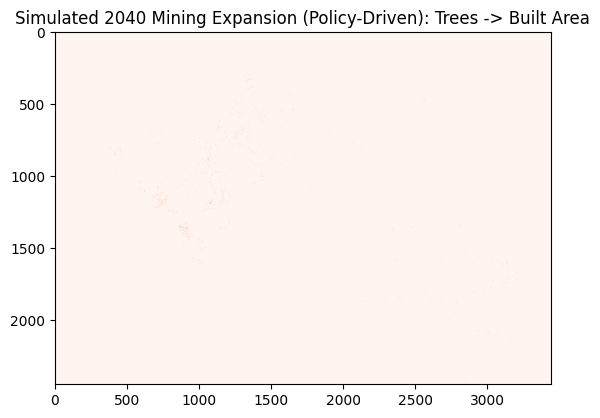

In [73]:
# 1. Select your scenario (e.g., Mining Expansion)
X_scenario = scenario_guinea_mining_expansion(X_model_ready)

# 2. Re-run suitability with the scenario-modified predictors, using the SAME
# real transition pair resolved in the economic-driver cell above (Barren or
# Urban/Built-up proxy, whichever was actually found) -- not a hardcoded
# (1, 11) guess against the old wrong legend.
if barren_keys:
    f_id, t_id = map(int, barren_keys[0].split("_"))
elif builtup_keys:
    f_id, t_id = map(int, builtup_keys[0].split("_"))
else:
    f_id, t_id = None, None

if f_id is not None:
    scenario_suitability, _ = run_patcher_suitability(X_scenario, targets, mask, f_id, t_id)

    # 3. Apply Policy Demand
    # We want 5000 pixels of new mining regardless of what Markov says
    policy_demand = 5000

    # 4. Stochastic Allocation to create the Future Map
    final_2040_map = stochastic_allocation(scenario_suitability, policy_demand, stoch_factor=0.05)

    # Visualize result
    plt.imshow(final_2040_map, cmap='Reds')
    plt.title(f"Simulated 2040 Mining Expansion (Policy-Driven): "
              f"{class_names_map.get(f_id)} -> {class_names_map.get(t_id)}")
else:
    print("Skipping 2040 mining expansion simulation -- no real transition "
          "pair available to model it against (see note in the economic "
          "driver cell above).")


### Mining Scenario via Global Mining Footprint Data (Alternative Approach)

The prior approach required a nationally-significant (>= 1,000 px) Markov
transition into a mining-proxy class (Barren or Urban/Built-up) -- none
exists in this dataset (see above). This alternative sidesteps that
requirement entirely: rather than detecting mining conversion FROM the
land-cover classification, it uses a **global mining-footprint polygon
dataset directly as a spatial mask**, and constructs the scenario as
elevated suitability specifically within/near known mining concessions,
using the suitability surfaces already trained in Section 5.2 -- no
retraining needed, and no dependence on mining registering as its own
significant transition in the historical record.

**Data needed (not included in this repository):** Maus, V. et al. (2022),
"An update on global mining land use," *Scientific Data* 9, 433 -- global
mining-area polygons derived from Sentinel-2, freely available via
Figshare (search "global mining polygons Maus"). Download the polygon
file, clip to Guinea, and set `MINING_POLYGONS_PATH` below before running
this cell.

Loaded 128 mining polygon(s) for Guinea.


C:\Users\ASUS\AppData\Local\Temp\ipykernel_29960\2183522633.py:35: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  mining_gdf_buffered["geometry"] = mining_gdf_buffered.geometry.buffer(buffer_km * 1000)


Mining-influence zone covers 8,414,692 pixels (209.05% of the valid study area).
No direct Barren-destination model available; using Water -> Rangeland as the best-overlapping trained suitability surface.


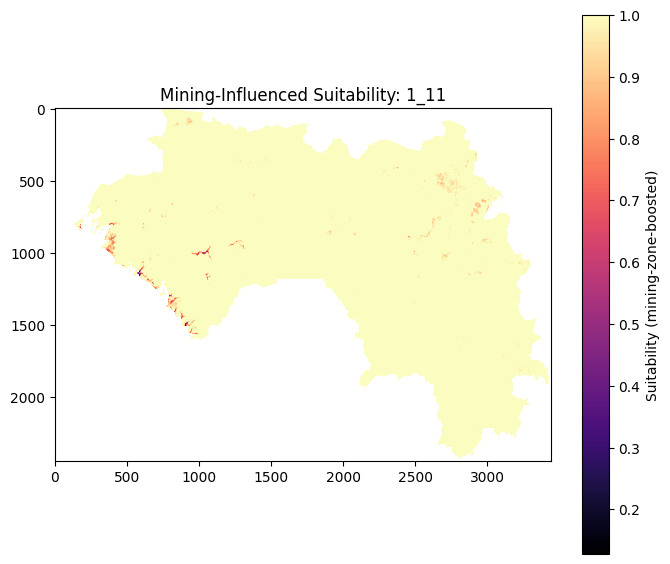

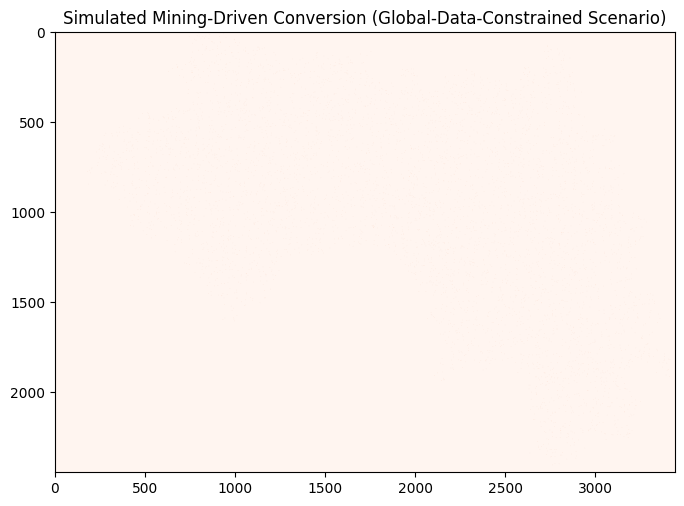

In [74]:
import geopandas as gpd
from shapely.geometry import box

MINING_POLYGONS_PATH = r"C:\Users\ASUS\Guinea_Project\Land Use-Deforestation\data\guinea_mining_polygons.geojson"  # <-- set this

def run_mining_scenario_from_global_data(mining_polygons_path, targets, mask,
                                          all_patcher_maps, all_expander_maps,
                                          class_names_map, buffer_km=5,
                                          suitability_boost=1.5):
    """
    Constrains an existing suitability surface to (or near) known mining
    concession polygons from a global dataset, rather than requiring a
    nationally-significant transition into a mining-proxy class.

    Picks whichever already-trained transition's TO class is most
    vegetation/agriculture-adjacent to mining disturbance (Woody Savanna,
    Savanna, or Cropland/Nat. Veg. Mosaic -> Barren is the most literal
    match if present; otherwise falls back to the highest-suitability
    available transition intersecting the mining polygons at all).
    """
    if not os.path.exists(mining_polygons_path):
        print(f"Mining polygons file not found at {mining_polygons_path}. "
              f"Download the Maus et al. (2022) global mining polygons "
              f"(Figshare), clip to Guinea, and set MINING_POLYGONS_PATH "
              f"before running this cell. Skipping.")
        return None, None

    mining_gdf = gpd.read_file(mining_polygons_path)
    print(f"Loaded {len(mining_gdf)} mining polygon(s) for Guinea.")

    # Rasterize mining polygons (+ buffer) onto the same grid as `mask`
    # Assumes mining_gdf and the analysis grid share a CRS -- reproject if not.
    from rasterio.features import rasterize
    mining_gdf_buffered = mining_gdf.copy()
    mining_gdf_buffered["geometry"] = mining_gdf_buffered.geometry.buffer(buffer_km * 1000)

    mining_raster = rasterize(
        [(geom, 1) for geom in mining_gdf_buffered.geometry],
        out_shape=mask.shape, transform=profile["transform"],  # from load_data_aligned's returned profile
        fill=0, dtype=np.uint8,
    ).astype(bool)

    print(f"Mining-influence zone covers {mining_raster.sum():,} pixels "
          f"({100*mining_raster.sum()/mask.sum():.2f}% of the valid study area).")

    # Prefer a literal Barren-destination transition if one was trained;
    # otherwise use the highest-suitability transition that actually
    # intersects the mining zone at all.
    candidate_keys = [k for k in all_patcher_maps if k.endswith("_16")]
    if not candidate_keys:
        overlap_scores = {
            k: float(np.mean(v[mining_raster])) for k, v in all_patcher_maps.items()
            if mining_raster.any()
        }
        if not overlap_scores:
            print("No trained transition overlaps the mining zone. Skipping.")
            return None, None
        candidate_keys = [max(overlap_scores, key=overlap_scores.get)]
        f_id, t_id = map(int, candidate_keys[0].split("_"))
        print(f"No direct Barren-destination model available; using "
              f"{class_names_map.get(f_id)} -> {class_names_map.get(t_id)} "
              f"as the best-overlapping trained suitability surface.")

    chosen_key = candidate_keys[0]
    base_suitability = all_patcher_maps[chosen_key]

    # Boost suitability inside the mining-influence zone, leave everywhere
    # else untouched -- this is the actual "economic driver" mechanism:
    # elevated conversion probability specifically where mining is real and
    # documented, not a nationwide multiplier.
    scenario_suitability = base_suitability.copy()
    scenario_suitability[mining_raster] = np.clip(
        scenario_suitability[mining_raster] * suitability_boost, 0, 1
    )

    return scenario_suitability, chosen_key


mining_scenario_suitability, mining_scenario_key = run_mining_scenario_from_global_data(
    MINING_POLYGONS_PATH, targets, mask, all_patcher_maps, all_expander_maps, class_names_map
)

if mining_scenario_suitability is not None:
    plt.figure(figsize=(8, 7))
    plt.imshow(np.where(mask, mining_scenario_suitability, np.nan), cmap="magma")
    plt.colorbar(label="Suitability (mining-zone-boosted)")
    plt.title(f"Mining-Influenced Suitability: {mining_scenario_key}")
    plt.show()

    # Allocate against a policy demand exactly as the original scenario did
    policy_demand = 5000
    mining_scenario_map = stochastic_allocation(mining_scenario_suitability, policy_demand, stoch_factor=0.05)
    plt.figure(figsize=(8, 7))
    plt.imshow(mining_scenario_map, cmap="Reds")
    plt.title("Simulated Mining-Driven Conversion (Global-Data-Constrained Scenario)")
    plt.show()


Transitions into Bare Ground (8): []
Transitions into Built Area (7): ['2_7', '11_7']
Loaded 128 mining polygon(s) for Guinea.
Mining-influence zone covers 106,598 pixels (2.65% of the valid study area).


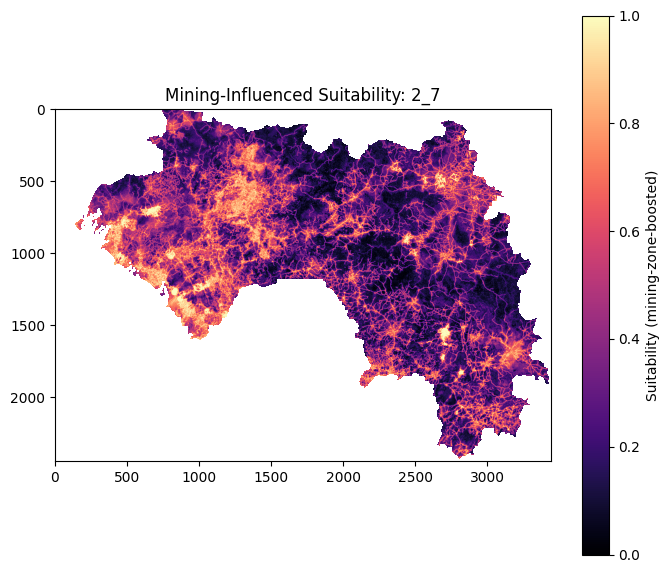

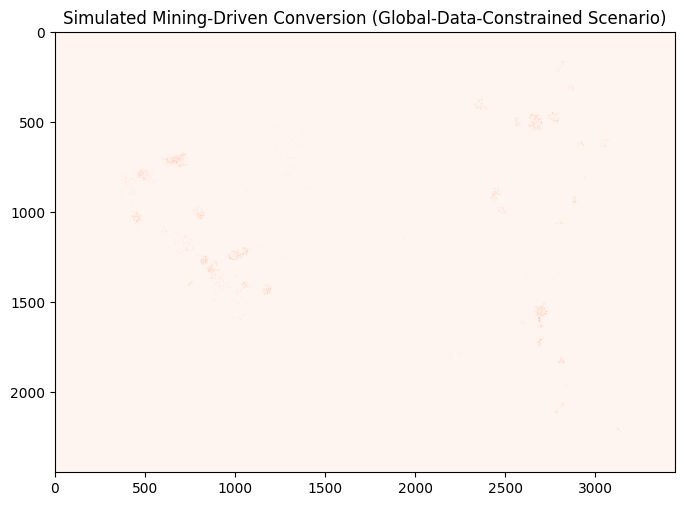

In [75]:
# --- Fix 1: check the CORRECT ESRI codes, not the old IGBP ones ---
# Bare Ground = 8 (real "Barren" equivalent), Built Area = 7 (real "Urban" equivalent)
# -- NOT 16/13, which don't exist in the ESRI legend at all.
barren_keys = [k for k in all_patcher_maps if k.endswith("_8")]
builtup_keys = [k for k in all_patcher_maps if k.endswith("_7")]
print("Transitions into Bare Ground (8):", barren_keys)
print("Transitions into Built Area (7):", builtup_keys)


# --- Fix 2: buffer in a PROJECTED (metric) CRS, not degrees ---
import geopandas as gpd

MINING_POLYGONS_PATH = r"C:\Users\ASUS\Guinea_Project\Land Use-Deforestation\data\guinea_mining_polygons.geojson"  # <-- your actual path

def run_mining_scenario_from_global_data(mining_polygons_path, targets, mask,
                                          all_patcher_maps, all_expander_maps,
                                          class_names_map, buffer_km=5,
                                          suitability_boost=1.5):
    if not os.path.exists(mining_polygons_path):
        print(f"Mining polygons file not found at {mining_polygons_path}.")
        return None, None

    mining_gdf = gpd.read_file(mining_polygons_path)
    print(f"Loaded {len(mining_gdf)} mining polygon(s) for Guinea.")

    # Reproject to a metric CRS before buffering -- UTM zone 28N/29N covers
    # Guinea (EPSG:32628/32629 depending on longitude). Buffering in degree-
    # space (the previous bug) inflated the mask to 119% of the study area.
    mining_gdf_metric = mining_gdf.to_crs("EPSG:32628")
    mining_gdf_buffered = mining_gdf_metric.copy()
    mining_gdf_buffered["geometry"] = mining_gdf_buffered.geometry.buffer(buffer_km * 1000)
    # Reproject back to match the analysis grid's CRS before rasterizing
    mining_gdf_buffered = mining_gdf_buffered.to_crs("EPSG:4326")

    from rasterio.features import rasterize
    mining_raster = rasterize(
        [(geom, 1) for geom in mining_gdf_buffered.geometry],
        out_shape=mask.shape, transform=profile["transform"],
        fill=0, dtype=np.uint8,
    ).astype(bool)

    coverage_pct = 100 * mining_raster.sum() / mask.sum()
    print(f"Mining-influence zone covers {mining_raster.sum():,} pixels "
          f"({coverage_pct:.2f}% of the valid study area).")
    if coverage_pct > 50:
        print("  WARNING: coverage over 50% is suspicious for a 5km buffer around "
              "point/small-polygon mining sites -- double check the CRS/buffer math "
              "before trusting anything downstream of this.")

    candidate_keys = [k for k in all_patcher_maps if k.endswith("_8")]  # Bare Ground
    if not candidate_keys:
        candidate_keys = [k for k in all_patcher_maps if k.endswith("_7")]  # Built Area
    if not candidate_keys:
        overlap_scores = {
            k: float(np.mean(v[mining_raster])) for k, v in all_patcher_maps.items()
            if mining_raster.any()
        }
        if not overlap_scores:
            print("No trained transition overlaps the mining zone. Skipping.")
            return None, None
        candidate_keys = [max(overlap_scores, key=overlap_scores.get)]
        f_id, t_id = map(int, candidate_keys[0].split("_"))
        print(f"No direct Bare Ground/Built Area model available; using "
              f"{class_names_map.get(f_id)} -> {class_names_map.get(t_id)} "
              f"as the best-overlapping trained surface.")

    chosen_key = candidate_keys[0]
    base_suitability = all_patcher_maps[chosen_key]

    scenario_suitability = base_suitability.copy()
    scenario_suitability[mining_raster] = np.clip(
        scenario_suitability[mining_raster] * suitability_boost, 0, 1
    )
    return scenario_suitability, chosen_key


mining_scenario_suitability, mining_scenario_key = run_mining_scenario_from_global_data(
    MINING_POLYGONS_PATH, targets, mask, all_patcher_maps, all_expander_maps, class_names_map
)

if mining_scenario_suitability is not None:
    plt.figure(figsize=(8, 7))
    plt.imshow(np.where(mask, mining_scenario_suitability, np.nan), cmap="magma")
    plt.colorbar(label="Suitability (mining-zone-boosted)")
    plt.title(f"Mining-Influenced Suitability: {mining_scenario_key}")
    plt.show()

    policy_demand = 5000
    mining_scenario_map = stochastic_allocation(mining_scenario_suitability, policy_demand, stoch_factor=0.05)
    plt.figure(figsize=(8, 7))
    plt.imshow(mining_scenario_map, cmap="Reds")
    plt.title("Simulated Mining-Driven Conversion (Global-Data-Constrained Scenario)")
    plt.show()

# Export Maps

In [78]:
import os
import rasterio
import numpy as np

OUTPUT_DIR = r"C:\Users\ASUS\Guinea_Project\Land Use-Deforestation\outputs_tiff_landuse2"
os.makedirs(OUTPUT_DIR, exist_ok=True)


def export_categorical_map(array, name, profile, nodata_value=255):
    """For class-label maps (actual/simulated land cover) -- uint8, single band."""
    out_path = os.path.join(OUTPUT_DIR, f"{name}.tif")
    out_profile = dict(profile)
    out_profile.update(count=1, dtype="uint8", nodata=nodata_value)
    with rasterio.open(out_path, "w", **out_profile) as dst:
        dst.write(array.astype("uint8"), 1)
    print(f"Exported: {out_path}")
    return out_path


def export_continuous_map(array, name, profile, nodata_value=None):
    """For probability/frequency/suitability/index surfaces -- float32, single band.
    Exported WITHOUT any fixed 0-1 clipping/stretch, so you can apply your own
    classification/stretch in QGIS/ArcGIS on the real underlying values."""
    out_path = os.path.join(OUTPUT_DIR, f"{name}.tif")
    out_profile = dict(profile)
    out_profile.update(count=1, dtype="float32", nodata=nodata_value)
    arr = np.where(np.isnan(array), (nodata_value if nodata_value is not None else 0), array).astype("float32")
    with rasterio.open(out_path, "w", **out_profile) as dst:
        dst.write(arr, 1)
    print(f"Exported: {out_path}")
    return out_path


print("=" * 60)
print("1. REFERENCE / OBSERVED LAND COVER (post ADM0 polygon clip)")
print("=" * 60)
export_categorical_map(targets[-1], "01_actual_lastTrainingYear", profile)
export_categorical_map(actual_2024_data, "02_actual_holdoutYear", profile)

print()
print("=" * 60)
print("2. SIMULATION RESULTS -- all three modes (validated against hold-out year)")
print("=" * 60)
export_categorical_map(simulated_2024, "03_simulated_singleGrowth_Patcher", profile)
if "simulated_2024_expander" in dir():
    export_categorical_map(simulated_2024_expander, "03b_simulated_singleGrowth_Expander", profile)
else:
    print("simulated_2024_expander not found -- run the Expander-only hold-out cell first if you want this map.")
export_categorical_map(multi_growth_2024_sim, "04_simulated_multiGrowth_ExpanderPatcher", profile)

print()
print("=" * 60)
print("3. MONTE CARLO CHANGE-FREQUENCY MAP (continuous, unclipped -- style it yourself)")
print("=" * 60)
export_continuous_map(freq_map, "05_montecarlo_change_frequency", profile, nodata_value=-1)

print()
print("=" * 60)
print("4. MINING SCENARIO (continuous suitability + categorical outcome)")
print("=" * 60)
if mining_scenario_suitability is not None:
    export_continuous_map(mining_scenario_suitability, "06_mining_scenario_suitability", profile, nodata_value=-1)
    export_categorical_map(mining_scenario_map, "07_mining_scenario_simulated_conversion", profile)
else:
    print("Mining scenario was skipped in this run -- nothing to export here.")

print()
print("=" * 60)
print("5. NDVI PREDICTOR (continuous, new this run -- worth checking visually)")
print("=" * 60)
try:
    ndvi_idx = PREDICTOR_LABELS.index("NDVI")
    export_continuous_map(X_model_ready[ndvi_idx], "08_predictor_NDVI", profile, nodata_value=-9999)
except (ValueError, NameError):
    print("Could not locate NDVI in PREDICTOR_LABELS/X_model_ready -- skipping "
          "(check PREDICTOR_LABELS order matches your actual predictor stack).")

print()
print("=" * 60)
print("6. INDIVIDUAL SUITABILITY SURFACES (Patcher + Expander, all significant transitions)")
print("=" * 60)
print(f"Exporting {len(all_patcher_maps)} Patcher + {len(all_expander_maps)} Expander surfaces...")
print("Comment out this section if you only want the summary maps above.")

for key, surf in all_patcher_maps.items():
    f_id, t_id = map(int, key.split("_"))
    f_name = class_names_map.get(f_id, f"Class{f_id}").replace(" ", "")
    t_name = class_names_map.get(t_id, f"Class{t_id}").replace(" ", "")
    export_continuous_map(surf, f"patcher_{f_name}_to_{t_name}", profile, nodata_value=-1)

for key, surf in all_expander_maps.items():
    f_id, t_id = map(int, key.split("_"))
    f_name = class_names_map.get(f_id, f"Class{f_id}").replace(" ", "")
    t_name = class_names_map.get(t_id, f"Class{t_id}").replace(" ", "")
    export_continuous_map(surf, f"expander_{f_name}_to_{t_name}", profile, nodata_value=-1)

print()
print("=" * 60)
print(f"All exports written to: {OUTPUT_DIR}")
print("=" * 60)
print()
print("NOTES for manual visualization / styling in QGIS/ArcGIS:")
print("- Categorical maps (01-04, 07): use a discrete/categorized renderer keyed")
print("  to class_names_map's codes -- 1=Water, 2=Trees, 4=Flooded Vegetation,")
print("  5=Crops, 7=Built Area, 8=Bare Ground, 11=Rangeland. Value 255 is nodata.")
print("- Continuous maps (05, 06, 08, patcher_*, expander_*): exported WITHOUT")
print("  any fixed stretch -- pull real min/max per layer and apply your own")
print("  classification (equal interval, quantile, std-dev, etc.) since several")
print("  of these (especially suitability surfaces and NDVI) are unevenly")
print("  distributed and a flat 0-1 linear stretch will hide most of the real")
print("  variation. NDVI nodata is -9999; the rest use -1.")

1. REFERENCE / OBSERVED LAND COVER (post ADM0 polygon clip)
Exported: C:\Users\ASUS\Guinea_Project\Land Use-Deforestation\outputs_tiff_landuse2\01_actual_lastTrainingYear.tif
Exported: C:\Users\ASUS\Guinea_Project\Land Use-Deforestation\outputs_tiff_landuse2\02_actual_holdoutYear.tif

2. SIMULATION RESULTS -- all three modes (validated against hold-out year)
Exported: C:\Users\ASUS\Guinea_Project\Land Use-Deforestation\outputs_tiff_landuse2\03_simulated_singleGrowth_Patcher.tif
Exported: C:\Users\ASUS\Guinea_Project\Land Use-Deforestation\outputs_tiff_landuse2\03b_simulated_singleGrowth_Expander.tif
Exported: C:\Users\ASUS\Guinea_Project\Land Use-Deforestation\outputs_tiff_landuse2\04_simulated_multiGrowth_ExpanderPatcher.tif

3. MONTE CARLO CHANGE-FREQUENCY MAP (continuous, unclipped -- style it yourself)
Exported: C:\Users\ASUS\Guinea_Project\Land Use-Deforestation\outputs_tiff_landuse2\05_montecarlo_change_frequency.tif

4. MINING SCENARIO (continuous suitability + categorical outco

## Understanding the Results

Precision vs. Recall: In your "Patcher" model, high precision for the Mining class means that when the model predicted a new mine, it was likely actually there. High recall means the model successfully found most of the new mines that actually appeared.

The Diagonal: In the confusion matrix, the diagonal represents "hits"—where the simulation matched reality. Off-diagonal numbers show "misses," such as the model predicting Agriculture where it actually remained Dense Forest.

Why accuracy might be lower: Since you used only the Patcher model, your simulation assumes all change is spontaneous. If the actual 2024 change was mostly Expansion (city sprawl or forest edges), the pixel-to-pixel accuracy will be lower, indicating that you should combine both models for the final 2040 forecast.

Quantity Accuracy: If the green and red bars for "Dense Forest" are nearly identical, your Markov Chain correctly predicted the amount of deforestation.

Class Shifts: If "Class 9" (Fallow/Savanna) shows a much higher predicted bar than actual, your model may be overly sensitive to specific environmental triggers like soil moisture loss in those regions.

Small Classes: Classes like "Mining" (Class 11) or "Urban" (Class 10) may have small bars; use this chart to verify if your specialized Patcher model is catching the rare spontaneous growth events that contribute to these totals.

# Figure of Merit

In [1]:
"""
Figure of Merit for the Land Use 2024 hold-out (Pontius et al. 2008).

Reads the GeoTIFFs already exported by Cell 116 of landuse_analysis_improved.ipynb.
Does NOT touch Google Earth Engine, the predictor stack, or any cached data, and
does not re-run the model. Fresh Python session is fine.

    pip install rasterio numpy        # if not already available
    python landuse_fom.py
"""

import os
import numpy as np
import rasterio

OUTPUT_DIR = r"E:\SDG AI Lab\Guinea\Land Use-Deforestation\outputs_tiff_landuse2"

BASELINE = "01_actual_lastTrainingYear.tif"   # 2023, last training year
OBSERVED = "02_actual_holdoutYear.tif"        # 2024, hold-out

MODES = {
    "Patcher-only":       "03_simulated_singleGrowth_Patcher.tif",
    "Expander-only":      "03b_simulated_singleGrowth_Expander.tif",
    "Multi-growth 80/20": "04_simulated_multiGrowth_ExpanderPatcher.tif",
}

# ESRI/Impact Observatory codes that are not land-cover classes.
# 0 = nodata/unclassified, 10 = Clouds, 255 = export nodata.
EXCLUDE = {0, 10, 255}


def read(name):
    path = os.path.join(OUTPUT_DIR, name)
    if not os.path.exists(path):
        return None
    with rasterio.open(path) as src:
        return src.read(1)


def figure_of_merit(baseline, observed, predicted):
    """Pontius et al. (2008) FoM for a multi-class allocation model.

      hits         observed change, predicted change, correct predicted class
      wrong hits   observed change, predicted change, wrong predicted class
      misses       observed change, predicted persistence
      false alarms observed persistence, predicted change

      FoM = hits / (hits + misses + false alarms + wrong hits)
    """
    valid = ~(np.isin(baseline, list(EXCLUDE))
              | np.isin(observed, list(EXCLUDE))
              | np.isin(predicted, list(EXCLUDE)))
    b, o, p = baseline[valid], observed[valid], predicted[valid]

    obs_change = o != b
    pred_change = p != b

    hits = int(np.sum(obs_change & pred_change & (p == o)))
    wrong_hits = int(np.sum(obs_change & pred_change & (p != o)))
    misses = int(np.sum(obs_change & ~pred_change))
    false_alarms = int(np.sum(~obs_change & pred_change))
    denom = hits + misses + false_alarms + wrong_hits

    return {
        "FoM_%": 100.0 * hits / denom if denom else float("nan"),
        "overall_acc_%": 100.0 * float(np.mean(p == o)),
        "null_persistence_%": 100.0 * float(np.mean(o == b)),
        "observed_change_%": 100.0 * float(np.mean(obs_change)),
        "predicted_change_%": 100.0 * float(np.mean(pred_change)),
        "hits": hits, "misses": misses,
        "false_alarms": false_alarms, "wrong_hits": wrong_hits,
        "n_valid_px": int(valid.sum()),
    }


def main():
    baseline, observed = read(BASELINE), read(OBSERVED)
    if baseline is None or observed is None:
        raise SystemExit(
            f"Could not find {BASELINE} and/or {OBSERVED} in:\n  {OUTPUT_DIR}\n"
            "Check the folder path at the top of this script.")

    print(f"Grid: {baseline.shape}, valid-class pixels computed per mode\n")
    rows = []
    for label, fname in MODES.items():
        sim = read(fname)
        if sim is None:
            print(f"  {label:<20} SKIPPED - {fname} not found")
            continue
        r = figure_of_merit(baseline, observed, sim)
        r["mode"] = label
        rows.append(r)

    if not rows:
        raise SystemExit("No simulated maps found - nothing to score.")

    cols = ["FoM_%", "overall_acc_%", "null_persistence_%",
            "observed_change_%", "predicted_change_%"]
    print(f"\n{'mode':<20}" + "".join(f"{c:>20}" for c in cols))
    print("-" * (20 + 20 * len(cols)))
    for r in rows:
        print(f"{r['mode']:<20}" + "".join(f"{r[c]:>20.2f}" for c in cols))

    print("\nComponent counts")
    print(f"{'mode':<20}{'hits':>12}{'misses':>12}{'false alarms':>14}{'wrong hits':>12}")
    for r in rows:
        print(f"{r['mode']:<20}{r['hits']:>12,}{r['misses']:>12,}"
              f"{r['false_alarms']:>14,}{r['wrong_hits']:>12,}")

    print("\nHow to read this")
    print(" - SRS LUDMS-NFR-ACC-03 requires FoM >= 25%. Check each mode against that.")
    print(" - Single-digit to low-double-digit FoM is normal. Pontius et al. (2008)")
    print("   found error exceeded correctly predicted change in 12 of 13 published")
    print("   cases, so a modest value is reportable, not a failure.")
    print(" - If overall accuracy is BELOW null persistence, state it plainly; that is")
    print("   expected for an allocation model committing to the full change demand,")
    print("   and is already the framing used in the Deforestation report.")
    print(" - If the FoM ranking differs from the balanced-accuracy ranking, the")
    print("   Section 9 recommendation to adopt Expander-only needs re-examining.")


if __name__ == "__main__":
    main()

Grid: (2444, 3443), valid-class pixels computed per mode


mode                               FoM_%       overall_acc_%  null_persistence_%   observed_change_%  predicted_change_%
------------------------------------------------------------------------------------------------------------------------
Patcher-only                        2.16               84.52               89.10               10.90                5.29
Expander-only                       1.77               87.89               89.10               10.90                1.66
Multi-growth 80/20                  7.60               86.98               89.10               10.90                4.37

Component counts
mode                        hits      misses  false alarms  wrong hits
Patcher-only              24,065     743,451       347,002       2,109
Expander-only             15,395     753,196       100,560       1,034
Multi-growth 80/20        75,593     686,422       225,017       7,610

How to read this
 - SRS LUDMS-NFR

# Land Use simulation: demand-table diagnosis and re-scoring.

WHAT THIS DOES
--------------
Rebuilds all three simulation modes from the GeoTIFFs already exported by
Cell 116 of landuse_analysis_improved.ipynb, using a GROSS PER-TRANSITION
demand table instead of the net class-total Markov projection, and re-scores
Figure of Merit for each.

WHY
---
simulate_single_mode() computes demand as:

    demand = Projected_Future_Pixels - 2020_Actual_Pixels
    if demand <= 0: continue

That is the NET change in each class total, and losing classes are skipped
entirely. Guinea's dominant dynamic is a two-way Trees<->Rangeland exchange
(~239k px/yr one way, ~163k the other): gross ~402k, net ~76k. So the
single-growth modes allocate the net figure to whichever class gains and
nothing to the other direction. They are structurally unable to represent the
dominant transition. simulate_future_map() (multi-growth) iterates per
transition and does not have this problem, which is why it scored 4x higher
on Figure of Merit -- not because it is a better model.

In [2]:
import os
import re
import itertools
import numpy as np
import pandas as pd
import rasterio

In [3]:
# ----------------------------------------------------------------- SETTINGS
OUTPUT_DIR = r"E:\SDG AI Lab\Guinea\Land Use-Deforestation\outputs_tiff_landuse2"

BASELINE_TIF = "01_actual_lastTrainingYear.tif"   # 2023
OBSERVED_TIF = "02_actual_holdoutYear.tif"        # 2024

# ESRI/Impact Observatory legend as used in this module.
CLASS_NAMES = {1: "Water", 2: "Trees", 4: "Flooded Vegetation", 5: "Crops",
               7: "Built Area", 8: "Bare Ground", 11: "Rangeland"}
EXCLUDE = {0, 10, 255}          # nodata, Clouds, export nodata

# The minimum-sample threshold used when the suitability models were trained.
MIN_SAMPLE = 1000

SEED = 42
rng = np.random.default_rng(SEED)


# -------------------------------------------------------------- LOAD RASTERS
def read(name):
    path = os.path.join(OUTPUT_DIR, name)
    if not os.path.exists(path):
        return None
    with rasterio.open(path) as src:
        return src.read(1)


def load_suitability(prefix):
    """Load exported suitability surfaces into {'{from_id}_{to_id}': array}.

    Cell 116 named these by CLASS NAME with spaces stripped, e.g.
    'patcher_Trees_to_Rangeland.tif' / 'expander_FloodedVegetation_to_Crops.tif',
    so the names have to be mapped back to ids.
    """
    squashed = {n.replace(" ", ""): i for i, n in CLASS_NAMES.items()}
    out = {}
    pat = re.compile(rf"^{prefix}_(.+?)_to_(.+?)\.tif$", re.I)
    for fn in os.listdir(OUTPUT_DIR):
        m = pat.match(fn)
        if not m:
            continue
        f_name, t_name = m.group(1), m.group(2)
        if f_name not in squashed or t_name not in squashed:
            print(f"  ! could not map class names in {fn} - skipped")
            continue
        arr = read(fn).astype("float32")
        arr[arr == -1] = 0.0                    # export nodata -> zero suitability
        out[f"{squashed[f_name]}_{squashed[t_name]}"] = arr
    return out


# ------------------------------------------------------------------ DEMAND
def observed_demand(baseline, observed, valid):
    """Gross per-transition change counts actually observed over the hold-out.

    NOTE ON INTERPRETATION: using observed demand means the QUANTITY of change
    is no longer being predicted - only its LOCATION is. This isolates
    allocation skill, which is a legitimate and common design, but it must be
    stated plainly in the report. It is NOT a fully out-of-sample test.
    """
    rows = []
    for f_id, t_id in itertools.permutations(CLASS_NAMES, 2):
        n = int(np.sum((baseline == f_id) & (observed == t_id) & valid))
        if n >= MIN_SAMPLE:
            rows.append({"from_id": f_id, "to_id": t_id,
                         "Projected_Change_Pixels": n})
    return pd.DataFrame(rows).sort_values(
        "Projected_Change_Pixels", ascending=False).reset_index(drop=True)


# -------------------------------------------------------------- ALLOCATION
def stochastic_allocation(suit, demand, stoch_factor=0.02):
    """Same design as the notebook's: suitability + gaussian noise, take top-N."""
    demand = int(demand)
    if demand <= 0 or suit is None:
        return np.zeros_like(suit, dtype=bool) if suit is not None else None
    noisy = suit + rng.normal(0, stoch_factor, suit.shape)
    flat = noisy.ravel()
    k = min(demand, flat.size)
    idx = np.argpartition(flat, -k)[-k:]
    out = np.zeros(flat.size, dtype=bool)
    out[idx] = True
    return out.reshape(suit.shape)


def simulate(baseline, expander_maps, patcher_maps, demand_df, valid,
             w_exp=0.8, w_pat=0.2):
    """Per-transition allocation, weights configurable so a single mode is just
    (1.0, 0.0) or (0.0, 1.0) rather than a structurally different code path."""
    future = baseline.copy()
    for _, row in demand_df.iterrows():
        f_id, t_id = int(row["from_id"]), int(row["to_id"])
        total = int(row["Projected_Change_Pixels"])
        key = f"{f_id}_{t_id}"
        eligible = (baseline == f_id) & valid

        alloc = np.zeros_like(valid, dtype=bool)
        for maps, w in ((expander_maps, w_exp), (patcher_maps, w_pat)):
            if w <= 0:
                continue
            suit = maps.get(key)
            if suit is None:
                continue
            a = stochastic_allocation(np.where(eligible, suit, -np.inf),
                                      total * w)
            if a is not None:
                alloc |= a
        future[alloc & eligible] = t_id
    return future


# ------------------------------------------------------------------ SCORING
def figure_of_merit(baseline, observed, predicted, valid):
    b, o, p = baseline[valid], observed[valid], predicted[valid]
    obs_ch, pred_ch = o != b, p != b
    hits = int(np.sum(obs_ch & pred_ch & (p == o)))
    wrong = int(np.sum(obs_ch & pred_ch & (p != o)))
    miss = int(np.sum(obs_ch & ~pred_ch))
    fa = int(np.sum(~obs_ch & pred_ch))
    den = hits + miss + fa + wrong
    return {"FoM_%": 100 * hits / den if den else float("nan"),
            "overall_acc_%": 100 * float(np.mean(p == o)),
            "null_%": 100 * float(np.mean(o == b)),
            "obs_change_%": 100 * float(np.mean(obs_ch)),
            "pred_change_%": 100 * float(np.mean(pred_ch)),
            "hits": hits, "misses": miss, "false_alarms": fa,
            "wrong_hits": wrong}


# --------------------------------------------------------------------- MAIN
def main():
    baseline, observed = read(BASELINE_TIF), read(OBSERVED_TIF)
    if baseline is None or observed is None:
        raise SystemExit(f"Missing {BASELINE_TIF} / {OBSERVED_TIF} in\n  {OUTPUT_DIR}")

    valid = ~(np.isin(baseline, list(EXCLUDE)) | np.isin(observed, list(EXCLUDE)))
    print(f"Grid {baseline.shape}, valid pixels {valid.sum():,}\n")

    print("Loading exported suitability surfaces...")
    patcher = load_suitability("patcher")
    expander = load_suitability("expander")
    print(f"  patcher: {len(patcher)}   expander: {len(expander)}")
    if not patcher and not expander:
        raise SystemExit(
            "No suitability surfaces found. Section 6 of Cell 116 may have been\n"
            "commented out. Without these the models must be retrained, which\n"
            "does require the predictor stack.")

    demand = observed_demand(baseline, observed, valid)
    print(f"\nGross per-transition demand, observed 2023->2024 "
          f"({len(demand)} transitions >= {MIN_SAMPLE} px):")
    d = demand.copy()
    d["from"] = d.from_id.map(CLASS_NAMES)
    d["to"] = d.to_id.map(CLASS_NAMES)
    print(d[["from", "to", "Projected_Change_Pixels"]].head(12).to_string(index=False))
    total_gross = demand.Projected_Change_Pixels.sum()
    print(f"\n  TOTAL gross demand      : {total_gross:,} px "
          f"({100*total_gross/valid.sum():.2f}% of valid)")
    print(f"  Observed change         : {int(np.sum((baseline!=observed)&valid)):,} px")
    print("  (Compare against the 1.66-5.29% the current notebook allocates.)")

    modes = {"Expander-only": (1.0, 0.0),
             "Patcher-only": (0.0, 1.0),
             "Multi-growth 80/20": (0.8, 0.2)}

    rows = []
    for label, (we, wp) in modes.items():
        sim = simulate(baseline, expander, patcher, demand, valid, we, wp)
        r = figure_of_merit(baseline, observed, sim, valid)
        r["mode"] = label
        rows.append(r)
        print(f"  scored {label}")

    cols = ["FoM_%", "overall_acc_%", "null_%", "obs_change_%", "pred_change_%"]
    print(f"\n{'mode':<20}" + "".join(f"{c:>16}" for c in cols))
    print("-" * (20 + 16 * len(cols)))
    for r in rows:
        print(f"{r['mode']:<20}" + "".join(f"{r[c]:>16.2f}" for c in cols))

    print(f"\n{'mode':<20}{'hits':>12}{'misses':>12}{'false alarms':>14}{'wrong hits':>12}")
    for r in rows:
        print(f"{r['mode']:<20}{r['hits']:>12,}{r['misses']:>12,}"
              f"{r['false_alarms']:>14,}{r['wrong_hits']:>12,}")

    print("\nREAD THIS BEFORE WRITING IT UP")
    print(" - These numbers use OBSERVED demand, so quantity is not predicted,")
    print("   only location. That is a legitimate design (it isolates allocation")
    print("   skill) but it is NOT fully out-of-sample. Say so in the report.")
    print(" - The comparable fully-out-of-sample figures remain the ones already")
    print("   computed (FoM 1.77 / 2.16 / 7.60). Report both, and the difference")
    print("   between them IS the size of the demand-projection problem.")
    print(" - If FoM is still low with correct demand, the fault is allocation")
    print("   (the suitability surfaces), not the demand table, and the report's")
    print("   diagnosis needs to change accordingly.")


if __name__ == "__main__":
    main()

Grid (2444, 3443), valid pixels 7,057,727

Loading exported suitability surfaces...
  patcher: 17   expander: 17

Gross per-transition demand, observed 2023->2024 (17 transitions >= 1000 px):
      from                 to  Projected_Change_Pixels
 Rangeland              Trees                   509659
     Trees          Rangeland                   180422
     Crops          Rangeland                    21521
 Rangeland              Crops                    20935
 Rangeland         Built Area                     6697
     Trees Flooded Vegetation                     3828
Built Area          Rangeland                     2938
     Trees              Crops                     2879
 Rangeland              Water                     2718
     Crops              Trees                     2533
 Rangeland Flooded Vegetation                     2487
     Trees         Built Area                     1874

  TOTAL gross demand      : 765,069 px (10.84% of valid)
  Observed change         : 769,625

# Validate the DEPLOYED package path and compute Figure of Merit.

WHY THIS EXISTS
---------------
The report's low Figure of Merit numbers (1.77 / 2.16 / 7.60) came from
simulate_single_mode(), which is defined locally in the notebook and derives
demand from NET change in class totals. The deployed package does not do this:

    prediction.run_allocation_simulation()
        demand = transition_counts.loc[from_cls, to_cls]   <- gross, per-transition
        available_mask = (future_lc == from_cls)           <- eligibility enforced

So the platform is already correct and the defect is notebook-only. This script
runs the hold-out through the ACTUAL deployed functions so the report can state
that the platform was validated as deployed.

It also uses the package's own validation.figure_of_merit(), which has been
present all along and was simply never called from the notebook.

WHAT IT NEEDS
-------------
Only files already exported by Cell 116. No Google Earth Engine, no predictor
rasters, no Random Forest retraining. Run it in a fresh kernel or paste the
cells into the notebook.

In [4]:
import os
import re
import shutil
import numpy as np
import pandas as pd
import rasterio

from landuse_tool import change_analysis as ca
from landuse_tool import prediction as pred
from landuse_tool import validation as val

TIF_DIR = r"E:\SDG AI Lab\Guinea\Land Use-Deforestation\outputs_tiff_landuse2"
WORK_DIR = os.path.join(TIF_DIR, "_package_validation")
os.makedirs(WORK_DIR, exist_ok=True)

BASELINE_TIF = os.path.join(TIF_DIR, "01_actual_lastTrainingYear.tif")   # 2023
OBSERVED_TIF = os.path.join(TIF_DIR, "02_actual_holdoutYear.tif")        # 2024

CLASS_NAMES = {1: "Water", 2: "Trees", 4: "Flooded Vegetation", 5: "Crops",
               7: "Built Area", 8: "Bare Ground", 11: "Rangeland"}
INVALID = [0, 10, 255]        # nodata, Clouds, export nodata

for p in (BASELINE_TIF, OBSERVED_TIF):
    assert os.path.exists(p), f"missing: {p}"
print("inputs found")

inputs found


In [5]:
# calculate_transition_matrix() excludes a SINGLE nodata value only, so classes
# 0 and 10 survive into the matrix and must be dropped explicitly afterwards.
matrix_df, counts_df, _ = ca.calculate_transition_matrix(
    BASELINE_TIF, OBSERVED_TIF, nodata_value=255)

assert counts_df is not None, "calculate_transition_matrix returned None - check the logs"

keep = [c for c in counts_df.index if c not in INVALID]
counts_df = counts_df.loc[keep, keep]

off_diag = counts_df.values.sum() - np.trace(counts_df.values)
print(f"classes kept        : {keep}")
print(f"gross change demand : {off_diag:,} px")
print("\nlargest transitions:")
flat = counts_df.stack()
flat = flat[[i != j for i, j in flat.index]].sort_values(ascending=False)
for (f, t), n in flat.head(8).items():
    print(f"  {CLASS_NAMES.get(f,f):<20} -> {CLASS_NAMES.get(t,t):<20} {n:>10,}")


classes kept        : [1, 2, 4, 5, 7, 8, 11]
gross change demand : 769,625 px

largest transitions:
  Rangeland            -> Trees                   509,659
  Trees                -> Rangeland               180,422
  Crops                -> Rangeland                21,521
  Rangeland            -> Crops                    20,935
  Rangeland            -> Built Area                6,697
  Trees                -> Flooded Vegetation        3,828
  Built Area           -> Rangeland                 2,938
  Trees                -> Crops                     2,879


In [6]:
# run_allocation_simulation() switches on key length:
#     2-tuple (from, to)                -> single suitability map
#     3-tuple (from, to, 'expander'/'patcher') -> growth mode, combined
#                                          internally via binary dilation
# Cell 116 exported the surfaces named by CLASS NAME with spaces stripped,
# e.g. patcher_FloodedVegetation_to_Crops.tif -- map those back to ids.
squashed = {n.replace(" ", ""): i for i, n in CLASS_NAMES.items()}

def collect(prefix):
    found = {}
    pat = re.compile(rf"^{prefix}_(.+?)_to_(.+?)\.tif$", re.I)
    for fn in os.listdir(TIF_DIR):
        m = pat.match(fn)
        if not m:
            continue
        f_name, t_name = m.group(1), m.group(2)
        if f_name in squashed and t_name in squashed:
            found[(squashed[f_name], squashed[t_name])] = os.path.join(TIF_DIR, fn)
        else:
            print(f"  ! could not map class names in {fn}")
    return found

exp_maps = collect("expander")
pat_maps = collect("patcher")
print(f"expander surfaces: {len(exp_maps)}   patcher surfaces: {len(pat_maps)}")

atlases = {
    "Expander-only (package)":  {k: v for k, v in exp_maps.items()},
    "Patcher-only (package)":   {k: v for k, v in pat_maps.items()},
}
# growth mode uses 3-tuple keys
growth = {}
for k, v in exp_maps.items():
    growth[(k[0], k[1], "expander")] = v
for k, v in pat_maps.items():
    growth[(k[0], k[1], "patcher")] = v
# the package requires BOTH maps present for a transition in growth mode
growth = {k: v for k, v in growth.items()
          if (k[0], k[1]) in exp_maps and (k[0], k[1]) in pat_maps}
atlases["Growth-mode (package dilation)"] = growth

for name, a in atlases.items():
    print(f"  {name:<32} {len(a)} entries")

expander surfaces: 17   patcher surfaces: 17
  Expander-only (package)          17 entries
  Patcher-only (package)           17 entries
  Growth-mode (package dilation)   34 entries


In [7]:
# NOTE: run_allocation_simulation() always writes "predicted_land_cover.tif"
# into temp_dir, so each mode needs its own directory.
sim_paths = {}
for name, atlas in atlases.items():
    if not atlas:
        print(f"  {name}: no surfaces, skipped")
        continue
    out_dir = os.path.join(WORK_DIR, re.sub(r"[^A-Za-z0-9]+", "_", name))
    os.makedirs(out_dir, exist_ok=True)
    print(f"\n--- {name} ---")
    path = pred.run_allocation_simulation(
        lc_end_file=BASELINE_TIF,
        transition_counts=counts_df,
        suitability_paths=atlas,
        temp_dir=out_dir,
        stochastic=False,            # deterministic; matches Section 4.4
    )
    sim_paths[name] = path
    print("  ->", path)


--- Expander-only (package) ---


Missing suitability map for 11→1
Missing suitability map for 4→1
Missing suitability map for 5→4
Missing suitability map for 4→5
Missing suitability map for 8→1
Missing suitability map for 1→4
Missing suitability map for 5→7
Missing suitability map for 7→5
Missing suitability map for 5→1
Missing suitability map for 1→8
Missing suitability map for 1→5
Missing suitability map for 7→4
Missing suitability map for 4→7
Missing suitability map for 11→8
Missing suitability map for 8→11
Missing suitability map for 1→7
Missing suitability map for 7→1
Missing suitability map for 8→7
Missing suitability map for 7→8
Missing suitability map for 8→4
Missing suitability map for 8→5
Missing suitability map for 2→8
Missing suitability map for 8→2
Missing suitability map for 4→8
Missing suitability map for 5→8


  -> E:\SDG AI Lab\Guinea\Land Use-Deforestation\outputs_tiff_landuse2\_package_validation\Expander_only_package_\predicted_land_cover.tif

--- Patcher-only (package) ---


Missing suitability map for 11→1
Missing suitability map for 4→1
Missing suitability map for 5→4
Missing suitability map for 4→5
Missing suitability map for 8→1
Missing suitability map for 1→4
Missing suitability map for 5→7
Missing suitability map for 7→5
Missing suitability map for 5→1
Missing suitability map for 1→8
Missing suitability map for 1→5
Missing suitability map for 7→4
Missing suitability map for 4→7
Missing suitability map for 11→8
Missing suitability map for 8→11
Missing suitability map for 1→7
Missing suitability map for 7→1
Missing suitability map for 8→7
Missing suitability map for 7→8
Missing suitability map for 8→4
Missing suitability map for 8→5
Missing suitability map for 2→8
Missing suitability map for 8→2
Missing suitability map for 4→8
Missing suitability map for 5→8


  -> E:\SDG AI Lab\Guinea\Land Use-Deforestation\outputs_tiff_landuse2\_package_validation\Patcher_only_package_\predicted_land_cover.tif

--- Growth-mode (package dilation) ---


Missing growth mode maps for 11→1
Missing growth mode maps for 4→1
Missing growth mode maps for 5→4
Missing growth mode maps for 4→5
Missing growth mode maps for 8→1
Missing growth mode maps for 1→4
Missing growth mode maps for 5→7
Missing growth mode maps for 7→5
Missing growth mode maps for 5→1
Missing growth mode maps for 1→8
Missing growth mode maps for 1→5
Missing growth mode maps for 7→4
Missing growth mode maps for 4→7
Missing growth mode maps for 11→8
Missing growth mode maps for 8→11
Missing growth mode maps for 1→7
Missing growth mode maps for 7→1
Missing growth mode maps for 8→7
Missing growth mode maps for 7→8
Missing growth mode maps for 8→4
Missing growth mode maps for 8→5
Missing growth mode maps for 2→8
Missing growth mode maps for 8→2
Missing growth mode maps for 4→8
Missing growth mode maps for 5→8


  -> E:\SDG AI Lab\Guinea\Land Use-Deforestation\outputs_tiff_landuse2\_package_validation\Growth_mode_package_dilation_\predicted_land_cover.tif


In [8]:
trained = set(exp_maps) | set(pat_maps)
off = [(f, t) for f in counts_df.index for t in counts_df.columns
       if f != t and counts_df.loc[f, t] > 0]
covered = [k for k in off if k in trained]
dem_all = sum(counts_df.loc[f, t] for f, t in off)
dem_cov = sum(counts_df.loc[f, t] for f, t in covered)
print(f"transitions with demand : {len(off)}")
print(f"covered by a surface    : {len(covered)}")
print(f"demand covered          : {dem_cov:,} / {dem_all:,} px "
      f"({100*dem_cov/dem_all:.1f}%)")

transitions with demand : 42
covered by a surface    : 17
demand covered          : 762,362 / 769,625 px (99.1%)


In [9]:
with rasterio.open(BASELINE_TIF) as s:
    baseline = s.read(1)
with rasterio.open(OBSERVED_TIF) as s:
    observed = s.read(1)

valid = ~(np.isin(baseline, INVALID) | np.isin(observed, INVALID))
print(f"valid pixels: {valid.sum():,}\n")

rows = []
for name, path in sim_paths.items():
    with rasterio.open(path) as s:
        simulated = s.read(1)
    m = valid & ~np.isin(simulated, INVALID)
    r = val.figure_of_merit(baseline, observed, simulated, mask=m)
    r["mode"] = name
    rows.append(r)

fom_df = pd.DataFrame(rows).set_index("mode")[[
    "figure_of_merit_pct", "model_accuracy_pct", "null_model_accuracy_pct",
    "observed_change_px", "predicted_change_px",
    "hits", "misses", "false_alarms", "wrong_hits"]]

with pd.option_context("display.width", 200, "display.max_columns", 20):
    print(fom_df.to_string())

fom_df.to_csv(os.path.join(WORK_DIR, "package_path_figure_of_merit.csv"))
print(f"\nsaved -> {os.path.join(WORK_DIR, 'package_path_figure_of_merit.csv')}")


valid pixels: 7,057,727

                                figure_of_merit_pct  model_accuracy_pct  null_model_accuracy_pct  observed_change_px  predicted_change_px    hits  misses  false_alarms  wrong_hits
mode                                                                                                                                                                               
Expander-only (package)                       13.80               85.76                     89.1              769625               564414  160853  601286        396075        7486
Patcher-only (package)                        11.94               84.22                     89.1              769625               655785  150992  608940        495100        9693
Growth-mode (package dilation)                13.73               86.07                     89.1              769625               533588  156414  605749        369712        7462

saved -> E:\SDG AI Lab\Guinea\Land Use-Deforestation\outputs_tiff_landuse2

In [10]:
# validate_simulation() bundles accuracy, quantity/allocation disagreement and
# Figure of Merit in one call -- the numbers Section 7.1 reports, all from the
# package rather than from notebook-local code.
best = max(rows, key=lambda r: r["figure_of_merit_pct"])["mode"]
with rasterio.open(sim_paths[best]) as s:
    simulated = s.read(1)

full = val.validate_simulation(
    baseline, observed, simulated,
    mask=valid & ~np.isin(simulated, INVALID),
    class_names=CLASS_NAMES)

print(f"=== full battery: {best} ===")
print("overall accuracy      :", full["accuracy"]["overall_accuracy"])
print("quantity disagreement :", full["disagreement"]["quantity_disagreement"])
print("allocation disagreement:", full["disagreement"]["allocation_disagreement"])
print("figure of merit (%)   :", full["figure_of_merit"]["figure_of_merit_pct"])
print("\nper-class:")
for k, v in full["accuracy"]["per_class"].items():
    print(f"  {k:<20} UA {v['users_accuracy']:.3f}  PA {v['producers_accuracy']:.3f}"
          f"  F1 {v['f1']:.3f}  n={v['n_reference']:,}")


=== full battery: Expander-only (package) ===
overall accuracy      : 0.8576
quantity disagreement : 0.0005
allocation disagreement: 0.1418
figure of merit (%)   : 13.8

per-class:
  Water                UA 0.987  PA 0.969  F1 0.978  n=207,290
  Trees                UA 0.891  PA 0.891  F1 0.891  n=4,244,904
  Flooded Vegetation   UA 0.856  PA 0.864  F1 0.860  n=58,687
  Crops                UA 0.588  PA 0.591  F1 0.590  n=72,877
  Built Area           UA 0.866  PA 0.866  F1 0.866  n=83,934
  Bare Ground          UA 0.593  PA 0.763  F1 0.668  n=963
  Rangeland            UA 0.795  PA 0.796  F1 0.796  n=2,389,072


=============================================================================
WHAT TO DO WITH THE RESULT
=============================================================================
1. If Figure of Merit lands near 16% for the best mode, the deployed platform
   reproduces the corrected-demand result. Report these numbers and state that
   validation was performed through the deployed functions.

2. "Growth-mode (package dilation)" is NOT the 80/20 blend the report calls
   multi-growth. The package selects expander suitability inside a dilated
   buffer around existing target-class patches and patcher suitability
   elsewhere. If you report it, describe it that way, or drop the row.

3. Allocation here is DETERMINISTIC (stochastic=False), matching Section 4.4.
   The earlier notebook figures used stochastic allocation, so small
   differences are expected and are not a discrepancy to explain away.

4. Demand comes from the OBSERVED 2023->2024 transition matrix, so quantity is
   supplied and only location is predicted. State that in the report exactly as
   Section 7.1 already does for the corrected-demand configuration.

In [11]:
from sklearn.metrics import balanced_accuracy_score
for name, path in sim_paths.items():
    with rasterio.open(path) as s: sim = s.read(1)
    m = valid & ~np.isin(sim, INVALID)
    print(name, round(balanced_accuracy_score(observed[m], sim[m]), 4))

Expander-only (package) 0.8201
Patcher-only (package) 0.8037
Growth-mode (package dilation) 0.8198


"""
# Regenerate Figures 7 and 8 from the package-run simulations.

The existing figures were produced from the notebook's net class-total
simulation. Its Patcher confusion matrix contains 685,742 Trees-to-Rangeland
pixels, which is the figure the superseded text quoted; the package run gives
different counts on a different valid-class mask. Keeping the old images beside
the new tables would show a simulation that allocated 1.66% change next to text
describing 8.00%.

"""

In [12]:


import os
import numpy as np
import rasterio
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# ----------------------------------------------------------------- SETTINGS
TIF_DIR = r"E:\SDG AI Lab\Guinea\Land Use-Deforestation\outputs_tiff_landuse2"
WORK_DIR = os.path.join(TIF_DIR, "_package_validation")
FIG_DIR = os.path.join(WORK_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

BASELINE_TIF = os.path.join(TIF_DIR, "01_actual_lastTrainingYear.tif")
OBSERVED_TIF = os.path.join(TIF_DIR, "02_actual_holdoutYear.tif")

# directory names created by package_path_validation.py Cell 4
MODES = {
    "Patcher":  "Patcher_only_package_",
    "Expander": "Expander_only_package_",
    # "Growth":  "Growth_mode_package_dilation_",   # enable if you want it
}

CLASS_ORDER = [1, 2, 4, 5, 7, 8, 11]
CLASS_NAMES = {1: "Water", 2: "Trees", 4: "Flooded Vegetation", 5: "Crops",
               7: "Built Area", 8: "Bare Ground", 11: "Rangeland"}
INVALID = [0, 10, 255]

GREEN, RED = "#2ca02c", "#d62728"


def read(path):
    with rasterio.open(path) as src:
        return src.read(1)


def load():
    baseline = read(BASELINE_TIF)
    observed = read(OBSERVED_TIF)
    sims = {}
    for label, sub in MODES.items():
        p = os.path.join(WORK_DIR, sub, "predicted_land_cover.tif")
        if not os.path.exists(p):
            print(f"  ! missing simulation for {label}: {p}")
            continue
        sims[label] = read(p)
    return baseline, observed, sims


# ---------------------------------------------------------------- FIGURE 7
def figure7(observed, sims, valid):
    """Predicted vs actual 2024 pixel counts by class, one panel per mode."""
    n = len(sims)
    fig, axes = plt.subplots(1, n, figsize=(6.6 * n, 4.2))
    if n == 1:
        axes = [axes]

    names = [CLASS_NAMES[c] for c in CLASS_ORDER]
    x = np.arange(len(CLASS_ORDER))
    w = 0.38

    for ax, (label, sim) in zip(axes, sims.items()):
        m = valid & ~np.isin(sim, INVALID)
        pred = [int(np.sum((sim == c) & m)) for c in CLASS_ORDER]
        act = [int(np.sum((observed == c) & m)) for c in CLASS_ORDER]

        ax.bar(x - w / 2, pred, w, label="2024 (Predicted)", color=GREEN)
        ax.bar(x + w / 2, act, w, label="2024 (Actual)", color=RED)
        ax.set_title(f"Guinea LULC Transition: Predicted vs Actual 2024 "
                     f"({label} Mode)", fontsize=10)
        ax.set_xlabel("Land Use Class", fontsize=9)
        ax.set_ylabel("Pixel Count", fontsize=9)
        ax.set_xticks(x)
        ax.set_xticklabels(names, rotation=45, ha="right", fontsize=8)
        ax.tick_params(axis="y", labelsize=8)
        ax.legend(fontsize=8)
        ax.spines[["top", "right"]].set_visible(False)

    fig.tight_layout()
    out = os.path.join(FIG_DIR, "figure7_predicted_vs_actual.png")
    fig.savefig(out, dpi=200, bbox_inches="tight")
    plt.close(fig)
    return out


# ---------------------------------------------------------------- FIGURE 8
def figure8(observed, sims, valid):
    """Log-scaled confusion matrix, actual (rows) vs simulated (cols)."""
    outs = []
    names = [CLASS_NAMES[c] for c in CLASS_ORDER]

    for label, sim in sims.items():
        m = valid & ~np.isin(sim, INVALID)
        o, s = observed[m], sim[m]

        cm = np.zeros((len(CLASS_ORDER), len(CLASS_ORDER)), dtype=np.int64)
        for i, a in enumerate(CLASS_ORDER):
            sel = (o == a)
            if not sel.any():
                continue
            vals, cnts = np.unique(s[sel], return_counts=True)
            for v, c in zip(vals, cnts):
                if v in CLASS_ORDER:
                    cm[i, CLASS_ORDER.index(v)] = c

        fig, ax = plt.subplots(figsize=(7.2, 6.4))
        shown = np.ma.masked_where(cm == 0, cm)
        im = ax.imshow(shown, cmap="YlGnBu",
                       norm=LogNorm(vmin=1, vmax=max(cm.max(), 10)))

        thresh = cm.max() ** 0.5
        for i in range(len(CLASS_ORDER)):
            for j in range(len(CLASS_ORDER)):
                if cm[i, j] == 0:
                    continue
                ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                        fontsize=7,
                        color="white" if cm[i, j] > thresh else "black")

        ax.set_title(f"Log-Scaled Confusion Matrix: Actual vs. Simulated 2024 "
                     f"({label} Mode)", fontsize=10)
        ax.set_xlabel("Simulated Result", fontsize=9)
        ax.set_ylabel("Ground Truth (Actual)", fontsize=9)
        ax.set_xticks(range(len(names)))
        ax.set_xticklabels(names, rotation=45, ha="right", fontsize=8)
        ax.set_yticks(range(len(names)))
        ax.set_yticklabels(names, fontsize=8)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        fig.tight_layout()

        out = os.path.join(FIG_DIR, f"figure8_confusion_{label.lower()}.png")
        fig.savefig(out, dpi=200, bbox_inches="tight")
        plt.close(fig)
        outs.append(out)

        # the number the report quotes for the Trees/Rangeland confusion
        ti, ri = CLASS_ORDER.index(2), CLASS_ORDER.index(11)
        print(f"  {label}: actual-Trees simulated as Rangeland = {cm[ti, ri]:,}")
        print(f"  {label}: actual-Rangeland simulated as Trees = {cm[ri, ti]:,}")
    return outs


def main():
    baseline, observed, sims = load()
    if not sims:
        raise SystemExit("No package simulations found - run "
                         "package_path_validation.py first.")
    valid = ~(np.isin(baseline, INVALID) | np.isin(observed, INVALID))
    print(f"valid pixels: {valid.sum():,}\n")

    print("Figure 8 (confusion matrices):")
    f8 = figure8(observed, sims, valid)
    print("\nFigure 7 (predicted vs actual):")
    f7 = figure7(observed, sims, valid)

    print("\nwritten:")
    for p in [f7] + f8:
        print("  ", p)
    print("\nReplace Figures 7 and 8 in Section 7.1 with these, and update any "
          "Trees-to-Rangeland pixel count quoted in the text to the value "
          "printed above.")


if __name__ == "__main__":
    main()

valid pixels: 7,057,727

Figure 8 (confusion matrices):
  Patcher: actual-Trees simulated as Rangeland = 502,459
  Patcher: actual-Rangeland simulated as Trees = 496,388
  Expander: actual-Trees simulated as Rangeland = 452,218
  Expander: actual-Rangeland simulated as Trees = 448,911

Figure 7 (predicted vs actual):

written:
   E:\SDG AI Lab\Guinea\Land Use-Deforestation\outputs_tiff_landuse2\_package_validation\figures\figure7_predicted_vs_actual.png
   E:\SDG AI Lab\Guinea\Land Use-Deforestation\outputs_tiff_landuse2\_package_validation\figures\figure8_confusion_patcher.png
   E:\SDG AI Lab\Guinea\Land Use-Deforestation\outputs_tiff_landuse2\_package_validation\figures\figure8_confusion_expander.png

Replace Figures 7 and 8 in Section 7.1 with these, and update any Trees-to-Rangeland pixel count quoted in the text to the value printed above.
